# 4.2 - HPA heatmaps


## 1. Configuration

In [1]:
from pathlib import Path
import gzip, io, math, os, re, textwrap, warnings, zipfile
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 180)

# -----------------------------------------------------------------------------
# Shared paths and target groups
# -----------------------------------------------------------------------------
BASE_DIR = Path.cwd()
DOWNLOAD_DIR = BASE_DIR / 'pan_atlas_downloads'
OUTPUT_ROOT = BASE_DIR / '4.2_HPA_heatmaps_outputs'
SHARED_OUTPUT_DIR = OUTPUT_ROOT / 'shared'
SHARED_TABLE_DIR = SHARED_OUTPUT_DIR / 'tables'
SHARED_FIGURE_DIR = SHARED_OUTPUT_DIR / 'figures'

# These globals are switched by configure_target() before each target is run.
OUTPUT_DIR = SHARED_OUTPUT_DIR
TABLE_DIR = SHARED_TABLE_DIR
FIGURE_DIR = SHARED_FIGURE_DIR
TARGET_GROUP_NAME = 'Shared setup'
TARGET_STAGE_GROUPS = []

for folder in [OUTPUT_ROOT, SHARED_OUTPUT_DIR, SHARED_TABLE_DIR, SHARED_FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# All five uploaded variants are run sequentially. Remove an entry here if needed.
TARGET_SPECS = [
    {
        'key': 'proxy',
        'target_group_name': 'Proxy model',
        'target_stage_groups': ['Proxy model'],
        'output_folder_name': 'hpa_macroclass_proxy_single_model_mse020_030_outputs',
    },
    {
        'key': 'elasticnet',
        'target_group_name': 'ElasticNet',
        'target_stage_groups': ['ElasticNet'],
        'output_folder_name': 'hpa_macroclass_elasticnet_mse020_030_outputs',
    },
    {
        'key': 'xgb',
        'target_group_name': 'XGB',
        'target_stage_groups': ['XGB'],
        'output_folder_name': 'hpa_macroclass_xgb_mse020_030_outputs',
    },
    {
        'key': 'still_not_good',
        'target_group_name': 'Still not good',
        'target_stage_groups': ['Still not good'],
        'output_folder_name': 'hpa_macroclass_still_not_good_mse020_030_outputs',
    },
    {
        'key': 'model_good_union',
        'target_group_name': 'Model-good union: Proxy + ElasticNet + XGB',
        'target_stage_groups': ['Proxy model', 'ElasticNet', 'XGB'],
        'output_folder_name': 'hpa_macroclass_all_model_threshold_good_union_mse020_030_outputs',
    },
]

HPA_MACRO_CLASSES = ['Enzymes', 'Metabolic proteins', 'CD markers', 'Blood group antigen proteins', 'Nuclear receptors', 'Transporters', 'Ribosomal proteins', 'G-protein coupled receptors', 'Voltage-gated ion channels', 'Predicted membrane proteins', 'Predicted secreted proteins', 'Predicted intracellular proteins', 'Plasma proteins', 'Transcription factors', 'RNA polymerase related proteins', 'RAS pathway related proteins', 'Citric acid cycle related proteins', 'Essential proteins', 'Immunoglobulin genes', 'T-cell receptor genes']

# Local-first HPA file search. No internet/download is used.
HPA_CANDIDATE_FILES = [
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv.zip', DOWNLOAD_DIR / 'proteinatlas.tsv.zip',
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv.gz', DOWNLOAD_DIR / 'proteinatlas.tsv.gz',
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv', DOWNLOAD_DIR / 'proteinatlas.tsv',
    BASE_DIR / 'hpa_proteinatlas.tsv.zip', BASE_DIR / 'proteinatlas.tsv.zip',
]

# Manual override: paste one or more cascade_partition_proteins_long.csv paths here if auto-search is too broad.
CASCADE_LONG_FILES = []
AUTO_SEARCH_CASCADE_FILES = True

# Explicitly exclude old procedural and procedural-linear/proxy-linear exports.
EXCLUDED_SOURCE_IDS = {'procedural', 'proxy_linear'}
EXCLUDED_PATH_KEYWORDS = {'procedural_tables', 'procedural_proxy_norm_tables'}

SELECTED_METRICS = ['Pearson', 'Cosine', 'MSE']
SELECTED_THRESHOLDS_BY_METRIC = {
    'Pearson': [0.50, 0.70],
    'Cosine': [0.50, 0.70],
    'MSE': [0.20, 0.30],
}
THRESHOLD_TOLERANCE = 1e-7
MIN_HIGH_COVERAGE_PCT = 70.0

SAVE_PNG = True
SAVE_SVG = True
SAVE_PDF = False
DPI = 300

# The merged notebook displays every plot sequentially by default.
DISPLAY_ALL_PLOTS = True
MAX_HIGH_COVERAGE_ROWS_PER_PLOT = 30

mpl.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': DPI,
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'legend.fontsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

STAGE_COLORS = OrderedDict([
    ('Proxy model', '#4E79A7'),
    ('ElasticNet', '#F28E2B'),
    ('XGB', '#E15759'),
    ('Still not good', '#B07AA1'),
    ('scTranslator', '#76B7B2'),
    ('Other', '#9D9D9D'),
])
METRIC_ORDER = {'Pearson': 0, 'Cosine': 1, 'MSE': 2}

print(f'Base directory: {BASE_DIR}')
print(f'Merged output root: {OUTPUT_ROOT}')
print(f'Target groups configured: {len(TARGET_SPECS)}')
print(f'HPA macro protein classes configured: {len(HPA_MACRO_CLASSES)}')
print(f'Display every generated plot: {DISPLAY_ALL_PLOTS}')
print('Selected thresholds by metric:', SELECTED_THRESHOLDS_BY_METRIC)

Base directory: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Merged output root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs
Target groups configured: 5
HPA macro protein classes configured: 20
Display every generated plot: True
Selected thresholds by metric: {'Pearson': [0.5, 0.7], 'Cosine': [0.5, 0.7], 'MSE': [0.2, 0.3]}


## 2. Shared helper functions

In [2]:

def safe_filename(text, max_len=180):
    text = re.sub(r'[^A-Za-z0-9._ -]+', '_', str(text))
    text = re.sub(r'\s+', '_', text).strip('._-')
    return (text[:max_len] or 'figure')

def wrap_label(text, width=30):
    return '\n'.join(textwrap.wrap(str(text), width=width, break_long_words=False))

def normalize_text(value):
    value = str(value).strip().replace('–', '-').replace('—', '-').replace('−', '-')
    return re.sub(r'\s+', ' ', value).casefold()

def clean_gene_symbol(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if not value or value.lower() in {'nan', 'none', 'na', 'null'}:
        return np.nan
    # Partition proteins are gene symbols in the cascade exports. If a compound field appears, keep the first symbol.
    return re.split(r'[;|,/\s]+', value)[0].upper()

def split_hpa_terms(value):
    if pd.isna(value):
        return []
    text = str(value).strip()
    if not text or text.lower() in {'nan', 'none', 'na', 'null'}:
        return []
    out, seen = [], set()
    for part in re.split(r'[,;|]+', text):
        term = re.sub(r'\s+', ' ', part.strip())
        key = normalize_text(term)
        if term and key not in seen:
            out.append(term)
            seen.add(key)
    return out

def pick_column(df, candidates, required=True):
    norm_to_col = {normalize_text(c): c for c in df.columns}
    for cand in candidates:
        if cand in df.columns:
            return cand
        if normalize_text(cand) in norm_to_col:
            return norm_to_col[normalize_text(cand)]
    for cand in candidates:
        words = normalize_text(cand).split()
        for col in df.columns:
            if all(w in normalize_text(col) for w in words):
                return col
    if required:
        raise KeyError(f'Could not find any of {candidates}. Available columns include {list(df.columns)[:40]}')
    return None

def read_table_any(path):
    path = Path(path)
    suffixes = [s.lower() for s in path.suffixes]
    if suffixes and suffixes[-1] == '.zip':
        with zipfile.ZipFile(path) as zf:
            names = [n for n in zf.namelist() if not n.endswith('/') and n.lower().endswith(('.tsv', '.txt', '.csv'))]
            if not names:
                raise ValueError(f'No delimited .tsv/.txt/.csv file was found inside {path}')
            inner = names[0]
            sep = ',' if inner.lower().endswith('.csv') else '\t'
            with zf.open(inner) as fh:
                return pd.read_csv(fh, sep=sep, dtype=str, low_memory=False)
    if suffixes and suffixes[-1] == '.gz':
        sep = ',' if len(suffixes) >= 2 and suffixes[-2] == '.csv' else '\t'
        return pd.read_csv(path, sep=sep, dtype=str, compression='gzip', low_memory=False)
    if path.suffix.lower() == '.csv':
        return pd.read_csv(path, dtype=str, low_memory=False)
    return pd.read_csv(path, sep='\t', dtype=str, low_memory=False)

def save_figure(fig, stem):
    stem = safe_filename(stem)
    paths = []
    if SAVE_PNG:
        p = FIGURE_DIR / f'{stem}.png'
        fig.savefig(p, bbox_inches='tight', dpi=DPI)
        paths.append(p)
    if SAVE_SVG:
        p = FIGURE_DIR / f'{stem}.svg'
        fig.savefig(p, bbox_inches='tight')
        paths.append(p)
    if SAVE_PDF:
        p = FIGURE_DIR / f'{stem}.pdf'
        fig.savefig(p, bbox_inches='tight')
        paths.append(p)
    return paths

def show_or_close(fig, show=False):
    if show:
        plt.show()
    else:
        plt.close(fig)

def canonical_stage_group(raw_stage):
    text = normalize_text(raw_stage)
    if not text or text in {'nan', 'none'}:
        return 'Other'
    # Proxy is treated as one model; Proxy Pearson and Proxy Spearman are intentionally not split.
    if 'proxy' in text:
        return 'Proxy model'
    if 'enet' in text or 'elastic' in text:
        return 'ElasticNet'
    if 'xgb' in text or 'xgboost' in text:
        return 'XGB'
    if ('still' in text and 'good' in text) or 'no valid mse' in text:
        return 'Still not good'
    if 'sctranslator' in text:
        return 'scTranslator'
    return str(raw_stage).strip() or 'Other'

def parse_metric_family(analysis, label):
    text = f'{analysis} {label}'.casefold()
    if 'pearson' in text:
        return 'Pearson'
    if 'cosine' in text:
        return 'Cosine'
    if 'mse' in text:
        return 'MSE'
    return 'Other'

def parse_threshold_value(row):
    # Prefer explicit numeric threshold columns when available.
    for col in ['threshold', 'prediction_threshold', 'corr_threshold', 'mse_threshold', 'metric_threshold']:
        if col in row.index and pd.notna(row[col]):
            try:
                value = float(str(row[col]).strip())
                if math.isfinite(value):
                    return value
            except Exception:
                pass
    label = str(row.get('threshold_label', ''))
    nums = re.findall(r'[-+]?\d*\.\d+|[-+]?\d+', label)
    if not nums:
        return np.nan
    value = float(nums[-1])
    metric = parse_metric_family(row.get('analysis', ''), label)
    if metric in {'Pearson', 'Cosine'} and 1 < value <= 100:
        value /= 100.0
    return value

def threshold_name(metric, value):
    if pd.isna(value):
        return 'no fixed threshold'
    if metric in {'Pearson', 'Cosine'}:
        return f'>= {value:.2f}'
    if metric == 'MSE':
        return f'<= {value:.2f}'
    return f'{value:.2f}'

def preferred_analysis_rank(analysis, metric):
    a = normalize_text(analysis)
    if metric == 'Pearson':
        if a == 'pearson_threshold_sweep': return 0
        if a == 'main_pearson_cascade': return 1
        if 'pearson' in a and 'threshold' in a: return 2
        if 'pearson' in a: return 3
    if metric == 'Cosine':
        if a == 'cosine_threshold_sweep': return 0
        if a == 'main_cosine_cascade': return 1
        if 'cosine' in a and 'threshold' in a: return 2
        if 'cosine' in a: return 3
    if metric == 'MSE':
        if a == 'mse_threshold_sweep': return 0
        if a == 'main_mse_cascade': return 1
        if 'mse' in a and 'threshold' in a and 'percentile' not in a: return 2
        if 'mse' in a: return 3
    return 99

def infer_source_id(path):
    p = Path(path)
    parts = [x.lower() for x in p.parts]
    if 'procedural_proxy_z_tables' in parts:
        return 'proxy_z'
    if 'procedural_proxy_norm_tables' in parts:
        return 'proxy_linear'
    if 'procedural_tables' in parts:
        return 'procedural'
    for part in reversed(p.parts):
        if part.endswith('_tables') or part.startswith('procedural'):
            return safe_filename(part)
    return safe_filename(p.parent.parent.name if len(p.parts) >= 3 else p.parent.name)

def find_cascade_long_files():
    manual = [Path(p) for p in CASCADE_LONG_FILES]
    files = [p for p in manual if p.exists()]
    if AUTO_SEARCH_CASCADE_FILES:
        standard = [
            BASE_DIR / 'procedural_proxy_z_tables' / 'protein_names_by_cascade_partition' / 'cascade_partition_proteins_long.csv',
            BASE_DIR / 'protein_names_by_cascade_partition' / 'cascade_partition_proteins_long.csv',
        ]
        for p in standard:
            if p.exists():
                files.append(p)
        files.extend(BASE_DIR.rglob('protein_names_by_cascade_partition/cascade_partition_proteins_long.csv'))
    # De-duplicate while preserving order, and drop old procedural/proxy-linear exports.
    out, seen = [], set()
    for p in files:
        sid = infer_source_id(p)
        path_text = str(p).lower()
        if sid in EXCLUDED_SOURCE_IDS or any(k in path_text for k in EXCLUDED_PATH_KEYWORDS):
            continue
        rp = p.resolve()
        if rp not in seen:
            out.append(p)
            seen.add(rp)
    return out


## 3. Load HPA macro protein classes and cascade partitions once

The HPA membership table and standardized cascade partition table are shared by every target.

In [3]:

# -----------------------------
# HPA macro protein-class memberships
# -----------------------------
hpa_path = next((p for p in HPA_CANDIDATE_FILES if p.exists()), None)
if hpa_path is None:
    raise FileNotFoundError(
        'Could not find a local HPA protein atlas file. Expected pan_atlas_downloads/hpa_proteinatlas.tsv.zip or proteinatlas.tsv.zip.'
    )

hpa_raw = read_table_any(hpa_path)
gene_col = pick_column(hpa_raw, ['Gene', 'gene', 'Gene name', 'Gene symbol', 'gene_symbol', 'Gene name according to HGNC'])
protein_class_col = pick_column(hpa_raw, ['Protein class', 'protein_class', 'Protein classes'])
macro_map = {normalize_text(x): x for x in HPA_MACRO_CLASSES}
rows = []
for gene, protein_class in zip(hpa_raw[gene_col], hpa_raw[protein_class_col]):
    g = clean_gene_symbol(gene)
    if pd.isna(g):
        continue
    for term in split_hpa_terms(protein_class):
        macro_class = macro_map.get(normalize_text(term))
        if macro_class is not None:
            rows.append((g, macro_class, str(hpa_path)))

hpa_macro = pd.DataFrame(rows, columns=['gene_symbol', 'hpa_macro_class', 'hpa_source_file']).drop_duplicates(['gene_symbol', 'hpa_macro_class'])
if hpa_macro.empty:
    raise ValueError('No HPA macro protein classes matched. Check the Protein class column and HPA_MACRO_CLASSES.')
hpa_macro['hpa_macro_class'] = pd.Categorical(hpa_macro['hpa_macro_class'], categories=HPA_MACRO_CLASSES, ordered=True)
hpa_macro = hpa_macro.sort_values(['hpa_macro_class', 'gene_symbol']).reset_index(drop=True)
hpa_macro.to_csv(TABLE_DIR / 'hpa_macro_class_membership_long.csv', index=False)

hpa_group_sizes = hpa_macro.groupby('hpa_macro_class', observed=True)['gene_symbol'].nunique().reset_index(name='n_hpa_genes')
hpa_group_sizes.to_csv(TABLE_DIR / 'hpa_macro_class_sizes_in_hpa_file.csv', index=False)

print('HPA file loaded:', hpa_path)
print(f'HPA macro-class memberships retained: {len(hpa_macro):,}')
print(f'HPA genes with at least one retained macro class: {hpa_macro.gene_symbol.nunique():,}')
print(f'HPA macro classes observed in the local file: {hpa_macro.hpa_macro_class.nunique():,} / {len(HPA_MACRO_CLASSES)}')
print('Largest retained HPA macro classes:')
print(hpa_group_sizes.sort_values('n_hpa_genes', ascending=False).head(8).to_string(index=False))

# -----------------------------
# Cascade partition exports
# -----------------------------
cascade_files = find_cascade_long_files()
if not cascade_files:
    raise FileNotFoundError(
        'No cascade_partition_proteins_long.csv file found. Run the procedural export cell first, or set CASCADE_LONG_FILES manually.'
    )

all_parts = []
for path in cascade_files:
    df = pd.read_csv(path, dtype=str, low_memory=False)
    df['source_path'] = str(path)
    df['source_id'] = infer_source_id(path)
    all_parts.append(df)

raw_partitions = pd.concat(all_parts, ignore_index=True, sort=False)
required = ['protein', 'stage']
missing_required = [c for c in required if c not in raw_partitions.columns]
if missing_required:
    raise KeyError(f'Missing required columns in cascade export: {missing_required}')
if 'dataset' not in raw_partitions.columns:
    raw_partitions['dataset'] = 'dataset'
if 'analysis' not in raw_partitions.columns:
    raw_partitions['analysis'] = 'analysis_unknown'
if 'threshold_label' not in raw_partitions.columns:
    raw_partitions['threshold_label'] = ''

partitions = raw_partitions.copy()
partitions['gene_symbol'] = partitions['protein'].apply(clean_gene_symbol)
partitions = partitions.dropna(subset=['gene_symbol']).copy()
partitions['stage_group'] = partitions['stage'].apply(canonical_stage_group)
partitions['metric_family'] = partitions.apply(lambda r: parse_metric_family(r.get('analysis', ''), r.get('threshold_label', '')), axis=1)
partitions['threshold_value'] = partitions.apply(parse_threshold_value, axis=1)
partitions['threshold_value_rounded'] = partitions['threshold_value'].round(2)

# Keep Pearson/Cosine at 0.50 and 0.70, but MSE at 0.20 and 0.30.
thr_mask = pd.Series(False, index=partitions.index)
thr_values = partitions['threshold_value'].astype(float)
for metric, thresholds in SELECTED_THRESHOLDS_BY_METRIC.items():
    metric_thr_mask = pd.Series(False, index=partitions.index)
    for thr in thresholds:
        metric_thr_mask = metric_thr_mask | np.isclose(thr_values, thr, atol=THRESHOLD_TOLERANCE, equal_nan=False)
    thr_mask = thr_mask | (partitions['metric_family'].eq(metric) & metric_thr_mask)
selected = partitions[thr_mask].copy()
if selected.empty:
    raise ValueError('No selected threshold rows were found: Pearson/Cosine 0.50/0.70 and MSE 0.20/0.30.')

# Avoid double-counting when both main_*_cascade and *_threshold_sweep exist for the same metric and threshold.
selected['analysis_rank'] = selected.apply(lambda r: preferred_analysis_rank(r['analysis'], r['metric_family']), axis=1)
rank_cols = ['source_id', 'dataset', 'metric_family', 'threshold_value_rounded']
best_rank = selected.groupby(rank_cols, dropna=False)['analysis_rank'].min().reset_index(name='best_analysis_rank')
selected = selected.merge(best_rank, on=rank_cols, how='left')
selected = selected[selected['analysis_rank'] == selected['best_analysis_rank']].copy()

selected['threshold_name'] = selected.apply(lambda r: threshold_name(r['metric_family'], r['threshold_value_rounded']), axis=1)
# Clean plot/export labels: no procedural/proxy-linear source names and no CCLE prefix.
# Internal source/dataset columns are kept in tables for traceability, but figure labels and
# per-case file names use only the biological threshold case.
selected['case_key'] = selected.apply(
    lambda r: safe_filename(f"{r['metric_family']}__{r['threshold_value_rounded']:.2f}"), axis=1
)
selected['case_label'] = selected.apply(
    lambda r: f"{r['metric_family']} {r['threshold_name']}", axis=1
)
selected = selected.drop_duplicates(['source_id', 'dataset', 'metric_family', 'threshold_value_rounded', 'analysis', 'stage', 'gene_symbol'])
selected.to_csv(TABLE_DIR / 'selected_standardized_cascade_partitions.csv', index=False)

print('\nCascade partition files loaded:')
for path in cascade_files:
    print('-', path)
print(f'Raw partition rows: {len(raw_partitions):,}')
print(f'Selected Pearson/Cosine 0.50/0.70 and MSE 0.20/0.30 rows after duplicate-analysis preference: {len(selected):,}')
print(f'Selected unique genes: {selected.gene_symbol.nunique():,}')
print('Selected cases:')
case_preview = selected[['analysis', 'metric_family', 'threshold_name', 'case_label', 'case_key']].drop_duplicates().sort_values(['metric_family', 'threshold_name', 'analysis'])
print(case_preview.to_string(index=False))
print('\nObserved canonical stage groups in selected rows:')
stage_counts = selected.groupby('stage_group')['gene_symbol'].nunique().sort_values(ascending=False)
print(stage_counts.to_string())


HPA file loaded: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_downloads\hpa_proteinatlas.tsv.zip
HPA macro-class memberships retained: 41,660
HPA genes with at least one retained macro class: 20,151
HPA macro classes observed in the local file: 20 / 20
Largest retained HPA macro classes:
                 hpa_macro_class  n_hpa_genes
Predicted intracellular proteins        15906
     Predicted membrane proteins         5571
                         Enzymes         3777
                 Plasma proteins         3750
              Metabolic proteins         2882
                    Transporters         2137
              Essential proteins         2022
     Predicted secreted proteins         1902

Cascade partition files loaded:
- c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_z_tables\protein_names_by_cascade_partition\cascade_partition_proteins_long.csv
Raw partition rows: 355,616
Selected Pearson/Cosine 

## 4. Compute shared case denominators and stage splits once

In [4]:
CASE_COLS = ['source_id', 'dataset', 'metric_family', 'threshold_value_rounded', 'threshold_name', 'case_key', 'case_label']

# Denominator: genes from each HPA macro class present anywhere in each case's partition universe.
case_universe = selected[CASE_COLS + ['gene_symbol']].drop_duplicates()
case_macro = case_universe.merge(hpa_macro, on='gene_symbol', how='inner')
macro_universe_counts = (
    case_macro
    .groupby(CASE_COLS + ['hpa_macro_class'], observed=True)['gene_symbol']
    .nunique()
    .reset_index(name='n_macro_genes_in_partition_universe')
)
if macro_universe_counts.empty:
    raise ValueError('No selected partition genes matched the retained HPA macro protein classes.')

# Full partition split, shared by every target analysis.
stage_macro = selected[CASE_COLS + ['stage_group', 'gene_symbol']].drop_duplicates().merge(
    hpa_macro, on='gene_symbol', how='inner'
)
stage_counts = (
    stage_macro
    .groupby(CASE_COLS + ['stage_group', 'hpa_macro_class'], observed=True)['gene_symbol']
    .nunique()
    .reset_index(name='n_stage_group_genes_in_macro')
)
stage_coverage = stage_counts.merge(
    macro_universe_counts, on=CASE_COLS + ['hpa_macro_class'], how='left'
)
stage_coverage['pct_macro_captured_by_stage_group'] = (
    100 * stage_coverage['n_stage_group_genes_in_macro']
    / stage_coverage['n_macro_genes_in_partition_universe']
)
stage_coverage['hpa_macro_class'] = pd.Categorical(
    stage_coverage['hpa_macro_class'], categories=HPA_MACRO_CLASSES, ordered=True
)
stage_coverage = stage_coverage.sort_values(
    CASE_COLS + ['hpa_macro_class', 'stage_group']
).reset_index(drop=True)
stage_coverage.to_csv(
    SHARED_TABLE_DIR / 'hpa_macro_class_coverage_by_all_partition_stage_groups.csv', index=False
)

print(f'Shared case/macro denominator rows: {len(macro_universe_counts):,}')
print(f'Shared stage-coverage rows: {len(stage_coverage):,}')

Shared case/macro denominator rows: 108
Shared stage-coverage rows: 344


## 5. Target-specific coverage function

In [5]:
def configure_target(target_group_name, target_stage_groups, output_folder_name):
    """Switch the active target context used by saving and plotting functions."""
    global TARGET_GROUP_NAME, TARGET_STAGE_GROUPS, OUTPUT_DIR, TABLE_DIR, FIGURE_DIR

    TARGET_GROUP_NAME = target_group_name
    TARGET_STAGE_GROUPS = list(target_stage_groups)
    OUTPUT_DIR = OUTPUT_ROOT / output_folder_name
    TABLE_DIR = OUTPUT_DIR / 'tables'
    FIGURE_DIR = OUTPUT_DIR / 'figures'
    for folder in [OUTPUT_DIR, TABLE_DIR, FIGURE_DIR]:
        folder.mkdir(parents=True, exist_ok=True)


def compute_target_results(spec):
    """Compute and save target-specific HPA macro-class coverage tables."""
    configure_target(
        spec['target_group_name'],
        spec['target_stage_groups'],
        spec['output_folder_name'],
    )

    target_rows = selected[selected['stage_group'].isin(TARGET_STAGE_GROUPS)].copy()
    if target_rows.empty:
        raise ValueError(
            f'No selected rows matched target stage groups: {TARGET_STAGE_GROUPS}. '
            f'Observed groups: {sorted(selected.stage_group.unique())}'
        )

    target_macro = (
        target_rows[CASE_COLS + ['gene_symbol']]
        .drop_duplicates()
        .merge(hpa_macro, on='gene_symbol', how='inner')
    )
    target_counts = (
        target_macro
        .groupby(CASE_COLS + ['hpa_macro_class'], observed=True)['gene_symbol']
        .nunique()
        .reset_index(name='n_target_genes_in_macro')
    )

    coverage = macro_universe_counts.merge(
        target_counts, on=CASE_COLS + ['hpa_macro_class'], how='left'
    )
    coverage['n_target_genes_in_macro'] = coverage['n_target_genes_in_macro'].fillna(0).astype(int)
    coverage['pct_macro_captured_by_target'] = (
        100 * coverage['n_target_genes_in_macro']
        / coverage['n_macro_genes_in_partition_universe']
    )
    coverage['target_group'] = TARGET_GROUP_NAME
    coverage['hpa_macro_class'] = pd.Categorical(
        coverage['hpa_macro_class'], categories=HPA_MACRO_CLASSES, ordered=True
    )
    coverage = coverage.sort_values(CASE_COLS + ['hpa_macro_class']).reset_index(drop=True)
    coverage.to_csv(TABLE_DIR / 'target_hpa_macro_class_coverage.csv', index=False)

    target_gene_lists = (
        target_macro
        .groupby(CASE_COLS + ['hpa_macro_class'], observed=True)['gene_symbol']
        .apply(lambda s: ';'.join(sorted(set(s))))
        .reset_index(name='target_genes_in_macro')
    )
    target_gene_lists['target_group'] = TARGET_GROUP_NAME
    target_gene_lists.to_csv(TABLE_DIR / 'target_hpa_macro_class_gene_lists.csv', index=False)

    high_coverage = coverage[
        (coverage['n_target_genes_in_macro'] > 0)
        & (coverage['pct_macro_captured_by_target'] >= MIN_HIGH_COVERAGE_PCT)
    ].copy()
    high_coverage = high_coverage.sort_values(
        ['pct_macro_captured_by_target', 'n_target_genes_in_macro'],
        ascending=[False, False],
    )
    high_coverage.to_csv(
        TABLE_DIR / f'high_coverage_hpa_macro_classes_ge_{int(MIN_HIGH_COVERAGE_PCT)}pct.csv',
        index=False,
    )

    summary = coverage.groupby(CASE_COLS, observed=True).agg(
        macro_classes_with_denominator=(
            'n_macro_genes_in_partition_universe', lambda s: int((s > 0).sum())
        ),
        target_gene_macro_memberships=('n_target_genes_in_macro', 'sum'),
        median_pct_macro_captured=('pct_macro_captured_by_target', 'median'),
        mean_pct_macro_captured=('pct_macro_captured_by_target', 'mean'),
        max_pct_macro_captured=('pct_macro_captured_by_target', 'max'),
        macro_classes_ge_70pct=(
            'pct_macro_captured_by_target',
            lambda s: int((s >= MIN_HIGH_COVERAGE_PCT).sum()),
        ),
        macro_classes_ge_90pct=(
            'pct_macro_captured_by_target', lambda s: int((s >= 90).sum())
        ),
    ).reset_index()
    summary['target_group'] = TARGET_GROUP_NAME
    summary = summary.sort_values(
        ['source_id', 'dataset', 'metric_family', 'threshold_value_rounded']
    )
    summary.to_csv(TABLE_DIR / 'compact_summary_by_threshold_case.csv', index=False)

    print('\nCompact HPA macro-class coverage summary')
    show_cols = [
        'source_id', 'dataset', 'metric_family', 'threshold_name',
        'macro_classes_with_denominator', 'target_gene_macro_memberships',
        'median_pct_macro_captured', 'max_pct_macro_captured',
        'macro_classes_ge_70pct',
    ]
    print(summary[show_cols].round(2).to_string(index=False))
    print(
        f'\nHigh-coverage rows: {len(high_coverage):,} '
        f'(coverage >= {MIN_HIGH_COVERAGE_PCT:.0f}%)'
    )

    return {
        'spec': spec,
        'coverage': coverage,
        'summary': summary,
        'high_coverage': high_coverage,
        'target_gene_lists': target_gene_lists,
        'stage_coverage': stage_coverage,
        'output_dir': OUTPUT_DIR,
        'table_dir': TABLE_DIR,
        'figure_dir': FIGURE_DIR,
    }

## 6. Plotting functions defined once

In [6]:

def ordered_cases(df):
    out = df[CASE_COLS].drop_duplicates().copy()
    out['metric_order'] = out['metric_family'].map(METRIC_ORDER).fillna(99)
    return out.sort_values(['source_id', 'dataset', 'metric_order', 'threshold_value_rounded']).drop(columns='metric_order')

def case_axis_labels(cases):
    # Clean labels: show only metric and threshold, never source names such as procedural/proxy_linear and never CCLE.
    labels = []
    for r in cases.itertuples(index=False):
        labels.append(f'{r.metric_family} {r.threshold_name}')
    return labels

def plot_overall_heatmap(cov, show=False):
    cases = ordered_cases(cov)
    if cases.empty:
        return
    case_order = cases['case_key'].tolist()
    labels = case_axis_labels(cases)
    mat = cov.pivot_table(
        index='hpa_macro_class', columns='case_key', values='pct_macro_captured_by_target', aggfunc='mean', observed=True
    ).reindex(index=HPA_MACRO_CLASSES, columns=case_order)
    fig, ax = plt.subplots(figsize=(max(9.5, 0.74 * len(case_order) + 3.2), 9.2))
    im = ax.imshow(mat.values.astype(float), aspect='auto', vmin=0, vmax=100, cmap='viridis')
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticks(range(len(HPA_MACRO_CLASSES)))
    ax.set_yticklabels([wrap_label(x, 31) for x in HPA_MACRO_CLASSES])
    ax.set_title(f'HPA macro-class coverage by {TARGET_GROUP_NAME}')
    ax.set_xlabel('Partition threshold case')
    ax.set_ylabel('HPA protein-class macro group')
    cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
    cbar.set_label('HPA macro group covered by target (%)')
    if len(case_order) <= 14:
        vals = mat.values
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                v = vals[i, j]
                if pd.notna(v):
                    ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5, color=('white' if v >= 55 else 'black'))
    fig.tight_layout()
    save_figure(fig, f'heatmap_hpa_macro_coverage_{TARGET_GROUP_NAME}')
    show_or_close(fig, show)

def plot_summary_case_bars(stats, show=False):
    if stats.empty:
        return
    stats = stats.copy()
    stats['metric_order'] = stats['metric_family'].map(METRIC_ORDER).fillna(99)
    stats = stats.sort_values(['source_id', 'dataset', 'metric_order', 'threshold_value_rounded'])
    labels = case_axis_labels(stats[CASE_COLS].drop_duplicates())
    vals = stats['macro_classes_ge_70pct'].astype(float).values
    med = stats['median_pct_macro_captured'].astype(float).values
    fig, ax1 = plt.subplots(figsize=(max(9.5, 0.70 * len(vals) + 3), 5.7))
    bar_color = STAGE_COLORS.get(TARGET_STAGE_GROUPS[0], '#4E79A7')
    bars = ax1.bar(range(len(vals)), vals, color=bar_color, alpha=0.88, label=f'Macro groups >= {MIN_HIGH_COVERAGE_PCT:.0f}%')
    ax1.set_ylabel(f'Number of HPA macro groups >= {MIN_HIGH_COVERAGE_PCT:.0f}% covered')
    ax1.set_xticks(range(len(vals)))
    ax1.set_xticklabels(labels, rotation=45, ha='right')
    ax1.grid(axis='y', alpha=0.22)
    for b, v in zip(bars, vals):
        ax1.text(b.get_x() + b.get_width()/2, v + 0.18, f'{int(v)}', ha='center', va='bottom', fontsize=9)
    ax2 = ax1.twinx()
    ax2.plot(range(len(med)), med, marker='o', linewidth=2.2, color='#222222', label='Median coverage')
    ax2.set_ylim(0, 100)
    ax2.set_ylabel('Median HPA macro coverage (%)')
    ax1.set_title(f'High-coverage HPA macro groups by threshold case: {TARGET_GROUP_NAME}')
    lines, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels1 + labels2, loc='upper left', frameon=False)
    fig.tight_layout()
    save_figure(fig, f'summary_high_coverage_counts_{TARGET_GROUP_NAME}')
    show_or_close(fig, show)

def plot_high_coverage_matrix(cov, show=False):
    high = cov.copy()
    high.loc[high['pct_macro_captured_by_target'] < MIN_HIGH_COVERAGE_PCT, 'pct_macro_captured_by_target'] = np.nan
    cases = ordered_cases(high)
    if cases.empty:
        return
    case_order = cases['case_key'].tolist()
    labels = case_axis_labels(cases)
    mat = high.pivot_table(index='hpa_macro_class', columns='case_key', values='pct_macro_captured_by_target', aggfunc='mean', observed=True).reindex(index=HPA_MACRO_CLASSES, columns=case_order)
    if mat.notna().sum().sum() == 0:
        return
    cmap = mpl.cm.get_cmap('magma').copy()
    cmap.set_bad('#F2F2F2')
    fig, ax = plt.subplots(figsize=(max(9.5, 0.74 * len(case_order) + 3.2), 9.2))
    im = ax.imshow(mat.values.astype(float), aspect='auto', vmin=MIN_HIGH_COVERAGE_PCT, vmax=100, cmap=cmap)
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticks(range(len(HPA_MACRO_CLASSES)))
    ax.set_yticklabels([wrap_label(x, 31) for x in HPA_MACRO_CLASSES])
    ax.set_title(f'HPA macro groups with >= {MIN_HIGH_COVERAGE_PCT:.0f}% coverage by {TARGET_GROUP_NAME}')
    ax.set_xlabel('Partition threshold case')
    ax.set_ylabel('HPA protein-class macro group')
    cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
    cbar.set_label('Coverage among high-covered groups (%)')
    if len(case_order) <= 14:
        vals = mat.values
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                v = vals[i, j]
                if pd.notna(v):
                    ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5, color='white')
    fig.tight_layout()
    save_figure(fig, f'high_coverage_matrix_ge_{int(MIN_HIGH_COVERAGE_PCT)}pct_{TARGET_GROUP_NAME}')
    show_or_close(fig, show)

def plot_high_coverage_bar_for_case(cov, case_key, show=False):
    sub = cov[(cov['case_key'] == case_key) & (cov['pct_macro_captured_by_target'] >= MIN_HIGH_COVERAGE_PCT) & (cov['n_target_genes_in_macro'] > 0)].copy()
    if sub.empty:
        return False
    sub = sub.sort_values(['pct_macro_captured_by_target', 'n_target_genes_in_macro'], ascending=[True, True]).tail(MAX_HIGH_COVERAGE_ROWS_PER_PLOT)
    desc = sub[CASE_COLS].drop_duplicates().iloc[0]
    y = np.arange(len(sub))
    vals = sub['pct_macro_captured_by_target'].astype(float).values
    n = sub['n_target_genes_in_macro'].astype(int).values
    d = sub['n_macro_genes_in_partition_universe'].astype(int).values
    colors = mpl.cm.viridis(np.linspace(0.32, 0.92, len(sub)))
    fig, ax = plt.subplots(figsize=(11.0, max(4.8, 0.43 * len(sub) + 2.0)))
    bars = ax.barh(y, vals, color=colors, alpha=0.95)
    ax.axvline(MIN_HIGH_COVERAGE_PCT, color='#333333', linestyle='--', linewidth=1.0, alpha=0.65)
    ax.set_xlim(max(0, MIN_HIGH_COVERAGE_PCT - 8), 103)
    ax.set_yticks(y)
    ax.set_yticklabels([wrap_label(x, 34) for x in sub['hpa_macro_class'].astype(str)])
    ax.set_xlabel('HPA macro group covered by target (%)')
    ax.set_ylabel('HPA protein-class macro group')
    ax.set_title(f'{TARGET_GROUP_NAME}: HPA macro groups >= {MIN_HIGH_COVERAGE_PCT:.0f}% covered\n{desc.case_label}')
    ax.grid(axis='x', alpha=0.22)
    for yi, v, nn, dd in zip(y, vals, n, d):
        ax.text(min(v + 0.8, 101.5), yi, f'{v:.0f}%  ({nn}/{dd})', va='center', ha='left', fontsize=9)
    fig.tight_layout()
    save_figure(fig, f'bar_high_coverage_ge_{int(MIN_HIGH_COVERAGE_PCT)}pct_{TARGET_GROUP_NAME}_{case_key}')
    show_or_close(fig, show)
    return True

def plot_high_coverage_dot_for_case(cov, case_key, show=False):
    sub = cov[(cov['case_key'] == case_key) & (cov['pct_macro_captured_by_target'] >= MIN_HIGH_COVERAGE_PCT) & (cov['n_target_genes_in_macro'] > 0)].copy()
    if sub.empty:
        return False
    sub = sub.sort_values(['pct_macro_captured_by_target', 'n_target_genes_in_macro'], ascending=[True, True]).tail(MAX_HIGH_COVERAGE_ROWS_PER_PLOT)
    desc = sub[CASE_COLS].drop_duplicates().iloc[0]
    y = np.arange(len(sub))
    vals = sub['pct_macro_captured_by_target'].astype(float).values
    denom = sub['n_macro_genes_in_partition_universe'].astype(float).values
    numer = sub['n_target_genes_in_macro'].astype(float).values
    sizes = 80 + 26 * np.sqrt(np.maximum(denom, 1))
    fig, ax = plt.subplots(figsize=(11.0, max(4.8, 0.43 * len(sub) + 2.0)))
    sc = ax.scatter(vals, y, s=sizes, c=numer, cmap='plasma', alpha=0.86, edgecolor='white', linewidth=0.8)
    ax.axvline(MIN_HIGH_COVERAGE_PCT, color='#333333', linestyle='--', linewidth=1.0, alpha=0.65)
    ax.set_xlim(max(0, MIN_HIGH_COVERAGE_PCT - 8), 103)
    ax.set_yticks(y)
    ax.set_yticklabels([wrap_label(x, 34) for x in sub['hpa_macro_class'].astype(str)])
    ax.set_xlabel('HPA macro group covered by target (%)')
    ax.set_ylabel('HPA protein-class macro group')
    ax.set_title(f'Dot/bubble view of high-covered HPA macro groups\n{TARGET_GROUP_NAME} - {desc.case_label}')
    ax.grid(axis='x', alpha=0.22)
    for yi, v, nn, dd in zip(y, vals, numer.astype(int), denom.astype(int)):
        ax.text(min(v + 0.8, 101.5), yi, f'{int(nn)}/{int(dd)}', va='center', ha='left', fontsize=9)
    cbar = fig.colorbar(sc, ax=ax, shrink=0.78, pad=0.02)
    cbar.set_label('Target genes in macro group')
    fig.tight_layout()
    save_figure(fig, f'dot_high_coverage_ge_{int(MIN_HIGH_COVERAGE_PCT)}pct_{TARGET_GROUP_NAME}_{case_key}')
    show_or_close(fig, show)
    return True

def plot_stage_split_for_top_high_groups(stage_cov, cov, case_key, show=False):
    top = cov[(cov['case_key'] == case_key) & (cov['pct_macro_captured_by_target'] >= MIN_HIGH_COVERAGE_PCT)].copy()
    if top.empty:
        return False
    top = top.sort_values(['pct_macro_captured_by_target', 'n_target_genes_in_macro'], ascending=[False, False]).head(12)
    macros = top['hpa_macro_class'].astype(str).tolist()
    sub = stage_cov[(stage_cov['case_key'] == case_key) & (stage_cov['hpa_macro_class'].astype(str).isin(macros))].copy()
    if sub.empty:
        return False
    desc = top[CASE_COLS].drop_duplicates().iloc[0]
    pivot = sub.pivot_table(index='hpa_macro_class', columns='stage_group', values='pct_macro_captured_by_stage_group', aggfunc='sum', observed=True).reindex(index=macros)
    stage_cols = [s for s in STAGE_COLORS.keys() if s in pivot.columns]
    if not stage_cols:
        return False
    pivot = pivot[stage_cols].fillna(0)
    fig, ax = plt.subplots(figsize=(12.5, max(5.2, 0.50 * len(pivot) + 2.2)))
    left = np.zeros(len(pivot))
    y = np.arange(len(pivot))
    for stage in stage_cols:
        vals = pivot[stage].astype(float).values
        ax.barh(y, vals, left=left, color=STAGE_COLORS.get(stage, '#999999'), label=stage, alpha=0.90)
        left += vals
    ax.set_xlim(0, 100)
    ax.set_yticks(y)
    ax.set_yticklabels([wrap_label(x, 34) for x in pivot.index.astype(str)])
    ax.invert_yaxis()
    ax.set_xlabel('Share of HPA macro group in each partition/model stage (%)')
    ax.set_ylabel('HPA protein-class macro group')
    ax.set_title(f'Partition split for high-covered HPA macro groups\n{desc.case_label}')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.22), ncol=min(5, len(stage_cols)), frameon=False)
    ax.grid(axis='x', alpha=0.22)
    fig.tight_layout()
    save_figure(fig, f'stage_split_top_high_coverage_groups_{TARGET_GROUP_NAME}_{case_key}')
    show_or_close(fig, show)
    return True


## 7. Sequential target runner

In [7]:
def generate_target_plots(results, display_all=True):
    """Generate, save, and sequentially display every available plot for one target."""
    coverage = results['coverage']
    summary = results['summary']

    # Overview plots.
    plot_overall_heatmap(coverage, show=True)
    plot_summary_case_bars(summary, show=True)
    plot_high_coverage_matrix(coverage, show=True)

    # Per-case plots. With display_all=True, every generated plot is displayed.
    created_bar = 0
    created_dot = 0
    created_split = 0
    cases = ordered_cases(coverage)
    for case_key in cases['case_key'].tolist():
        if plot_high_coverage_bar_for_case(coverage, case_key, show=display_all):
            created_bar += 1
        if plot_high_coverage_dot_for_case(coverage, case_key, show=display_all):
            created_dot += 1
        if plot_stage_split_for_top_high_groups(
            results['stage_coverage'], coverage, case_key, show=display_all
        ):
            created_split += 1

    print('\nFigures saved to:', results['figure_dir'])
    print(f'High-coverage bar plots created: {created_bar}')
    print(f'High-coverage dot/bubble plots created: {created_dot}')
    print(f'High-coverage partition-split plots created: {created_split}')
    print('Tables saved to:', results['table_dir'])


def run_target(spec, display_all=True):
    """Run one configured target from computation through plotting."""
    display(Markdown(f"## {spec['target_group_name']}"))
    print('Stage groups used as numerator:', spec['target_stage_groups'])
    results = compute_target_results(spec)
    generate_target_plots(results, display_all=display_all)
    return results

## 8. Run all heatmap analyses sequentially

This cell computes each target and displays its overview and per-case plots before moving to the next target.

## Proxy model

Stage groups used as numerator: ['Proxy model']

Compact HPA macro-class coverage summary
source_id dataset metric_family threshold_name  macro_classes_with_denominator  target_gene_macro_memberships  median_pct_macro_captured  max_pct_macro_captured  macro_classes_ge_70pct
  proxy_z    CCLE        Cosine        >= 0.50                              18                           5742                      56.17                  100.00                       4
  proxy_z    CCLE        Cosine        >= 0.70                              18                           2361                      23.32                  100.00                       3
  proxy_z    CCLE           MSE        <= 0.20                              18                            667                       3.09                   23.81                       0
  proxy_z    CCLE           MSE        <= 0.30                              18                           3225                      25.30                   42.86          

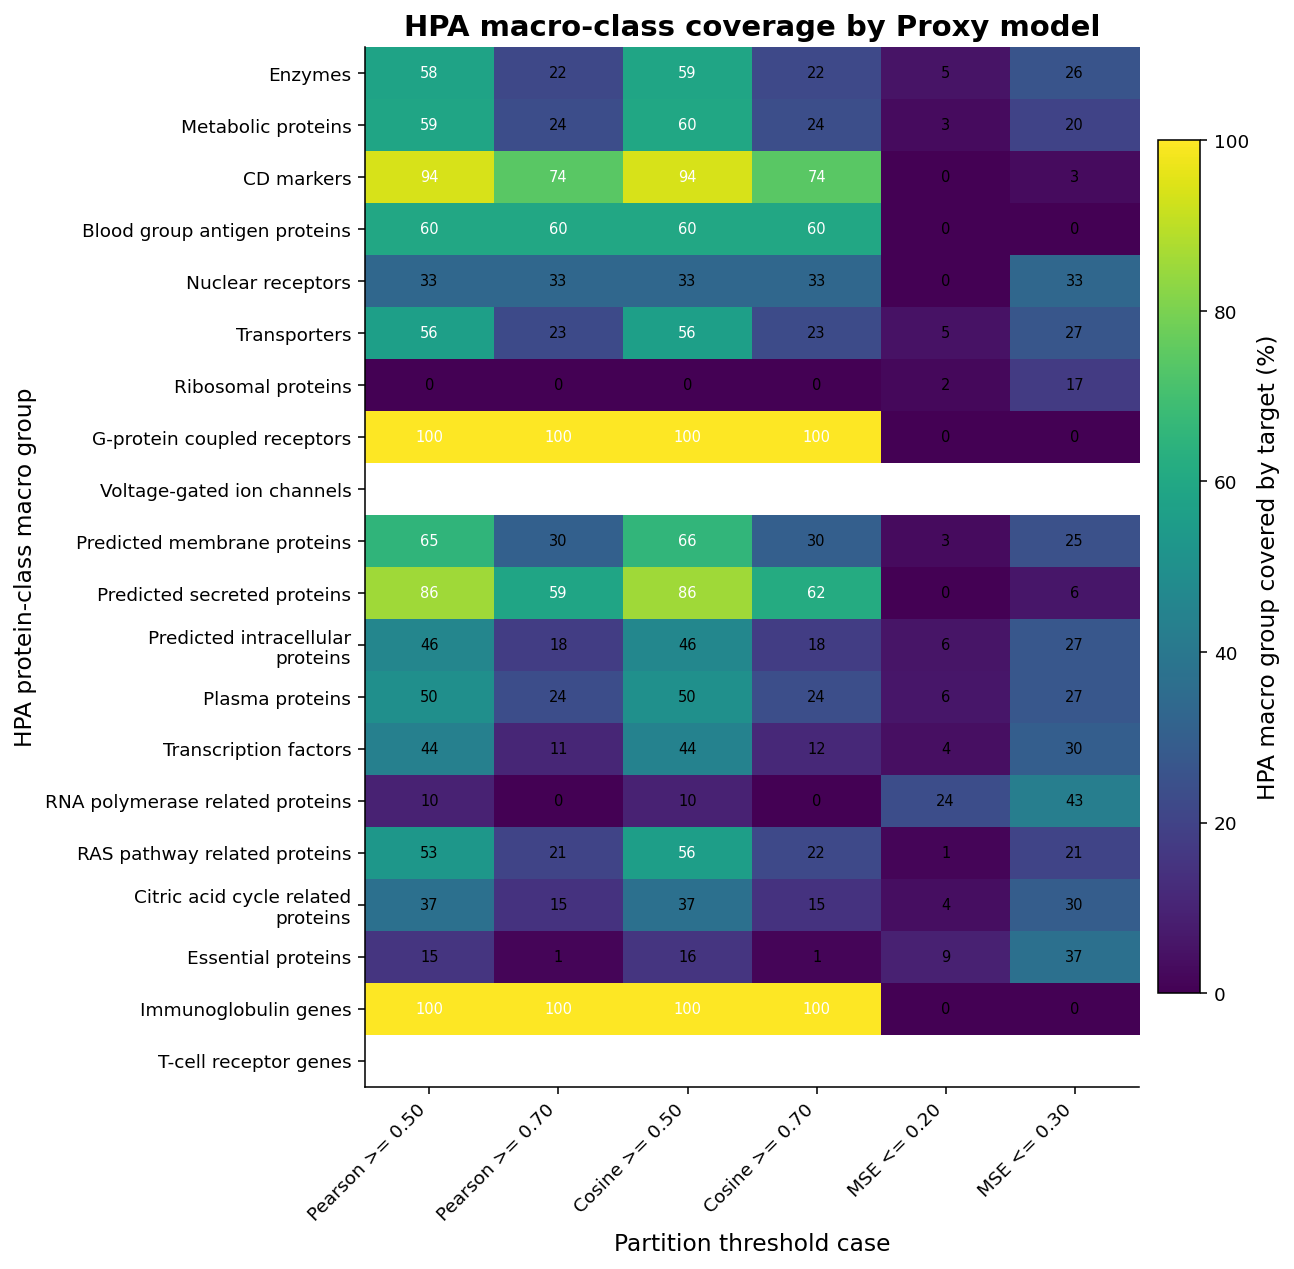

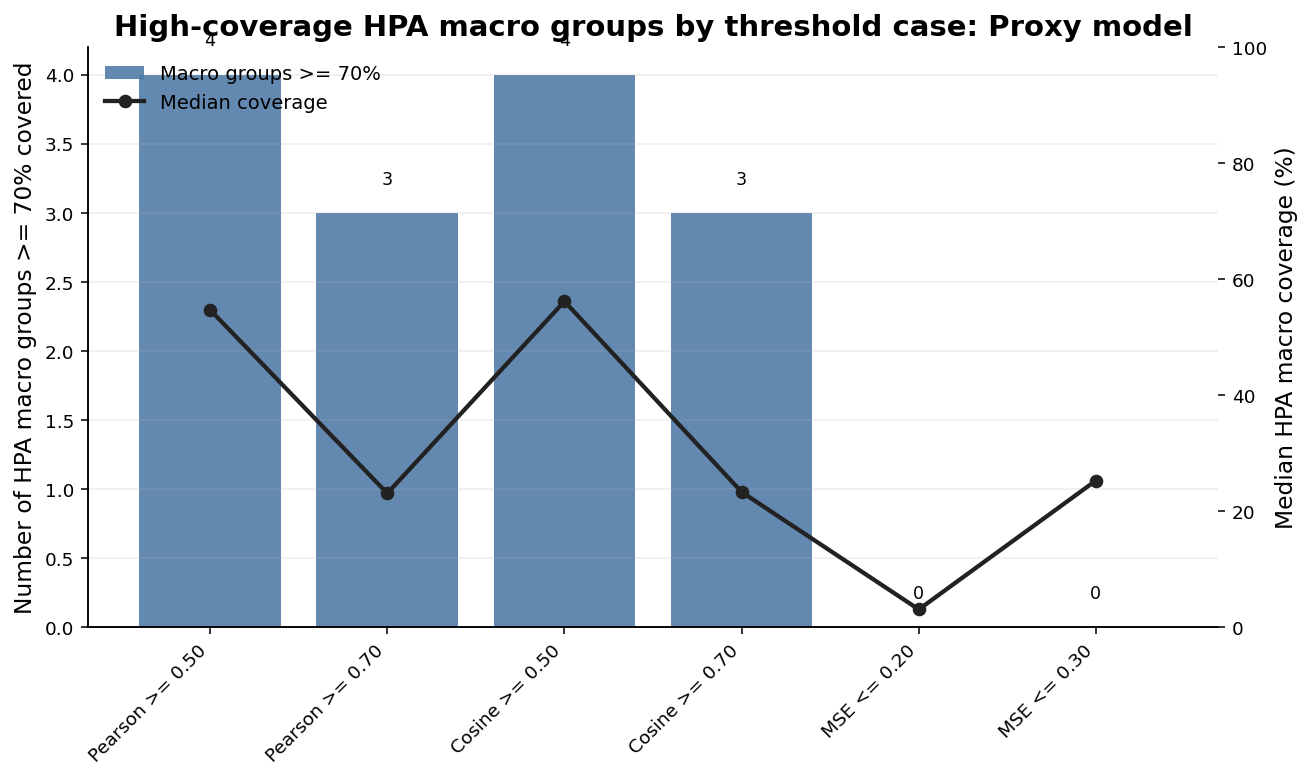

C:\Users\hp\AppData\Local\Temp\ipykernel_19564\3617896359.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap('magma').copy()


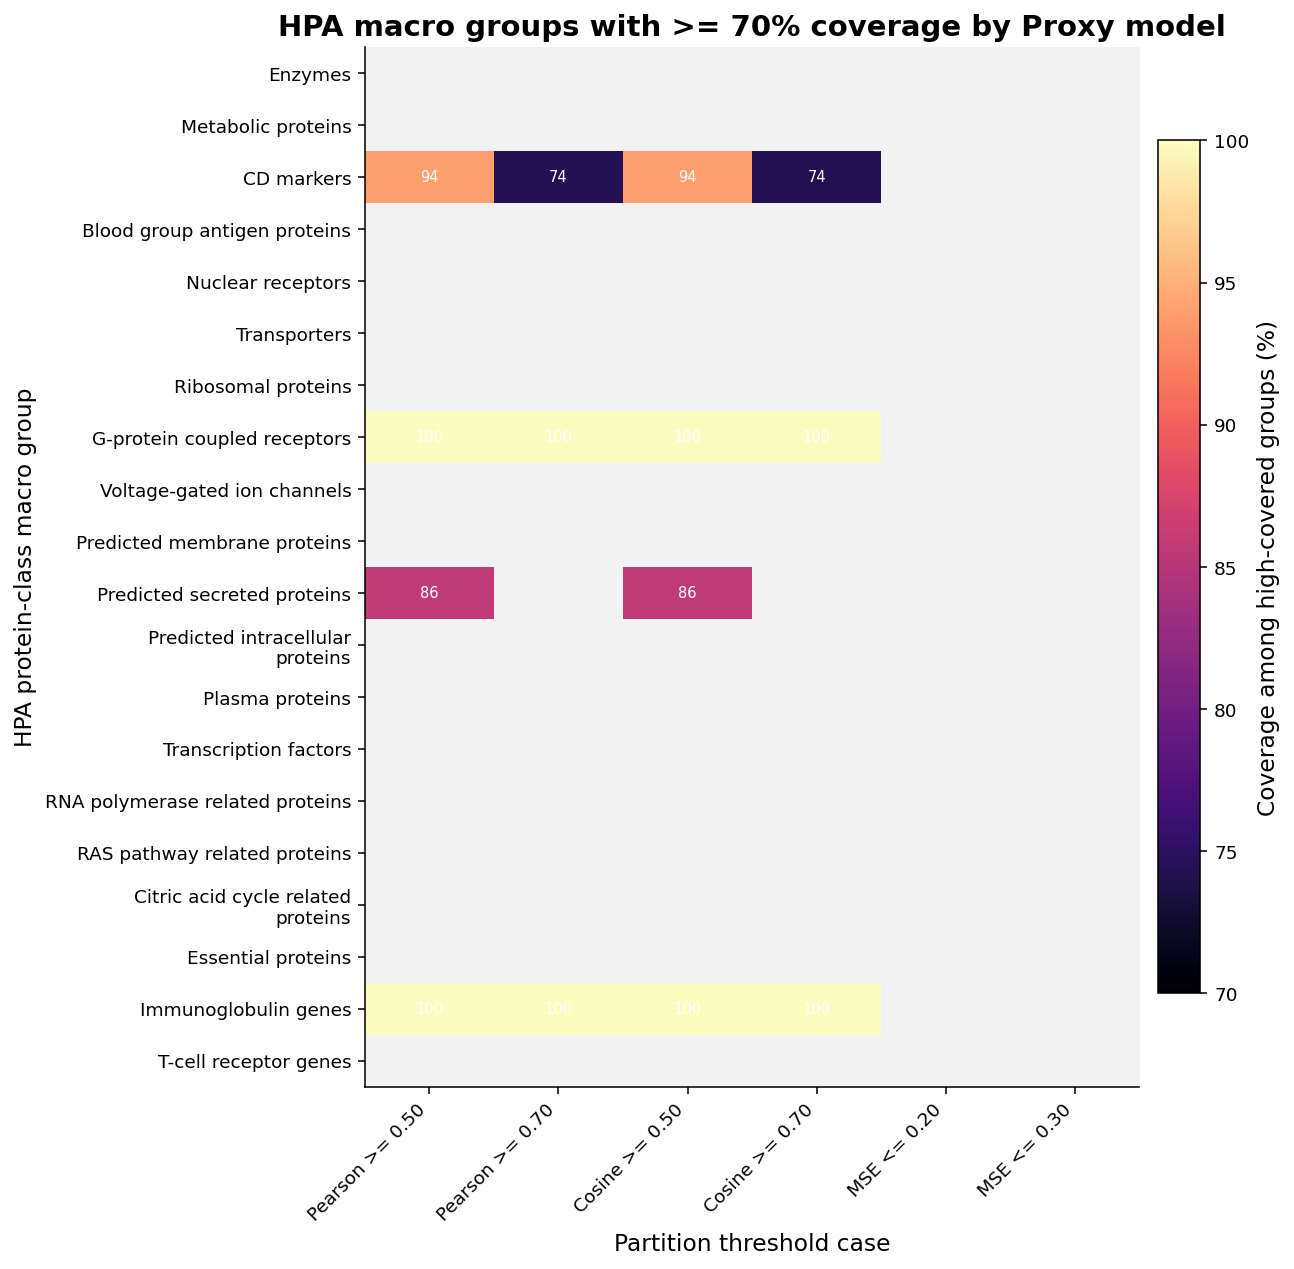

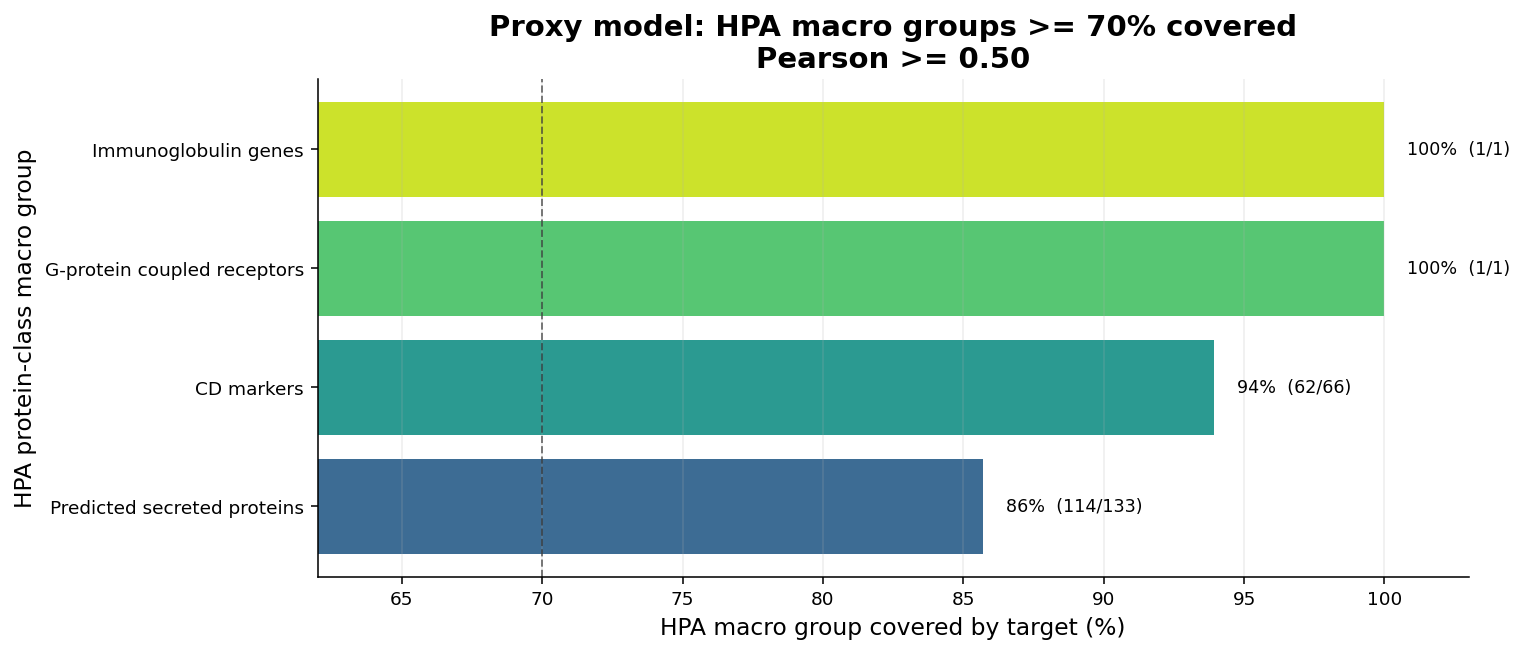

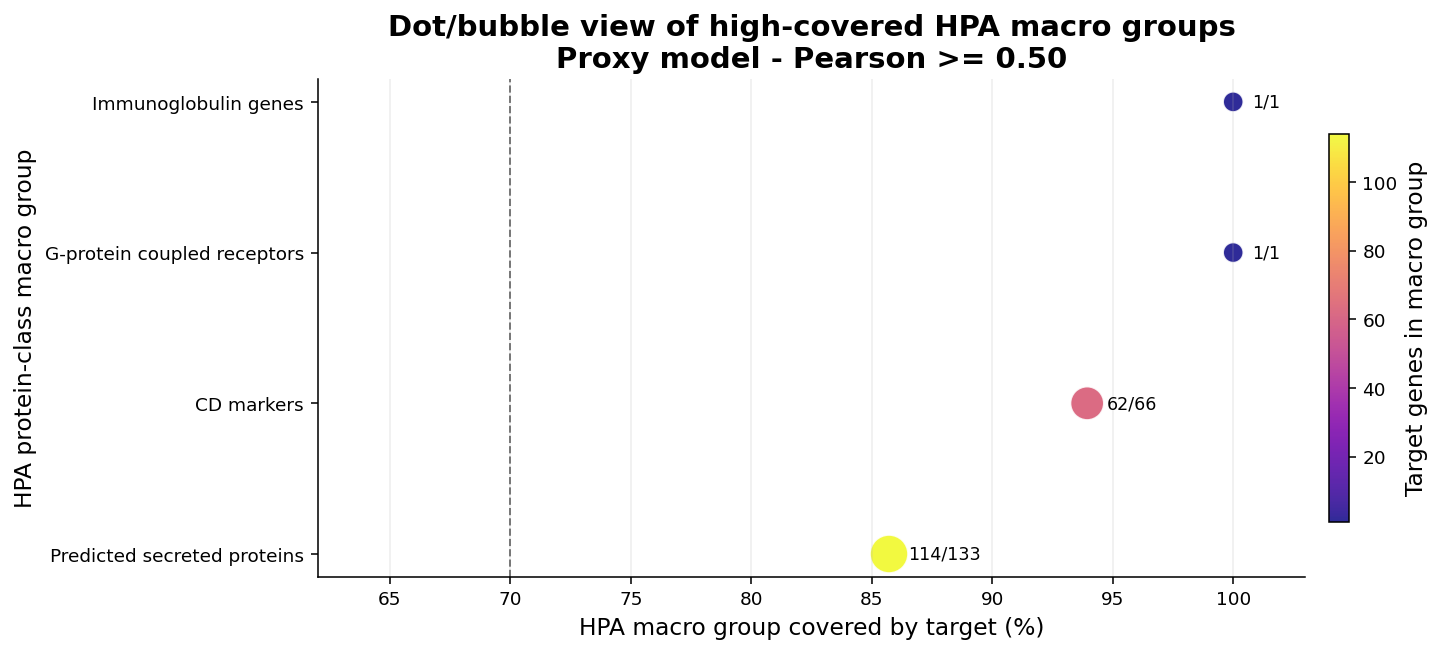

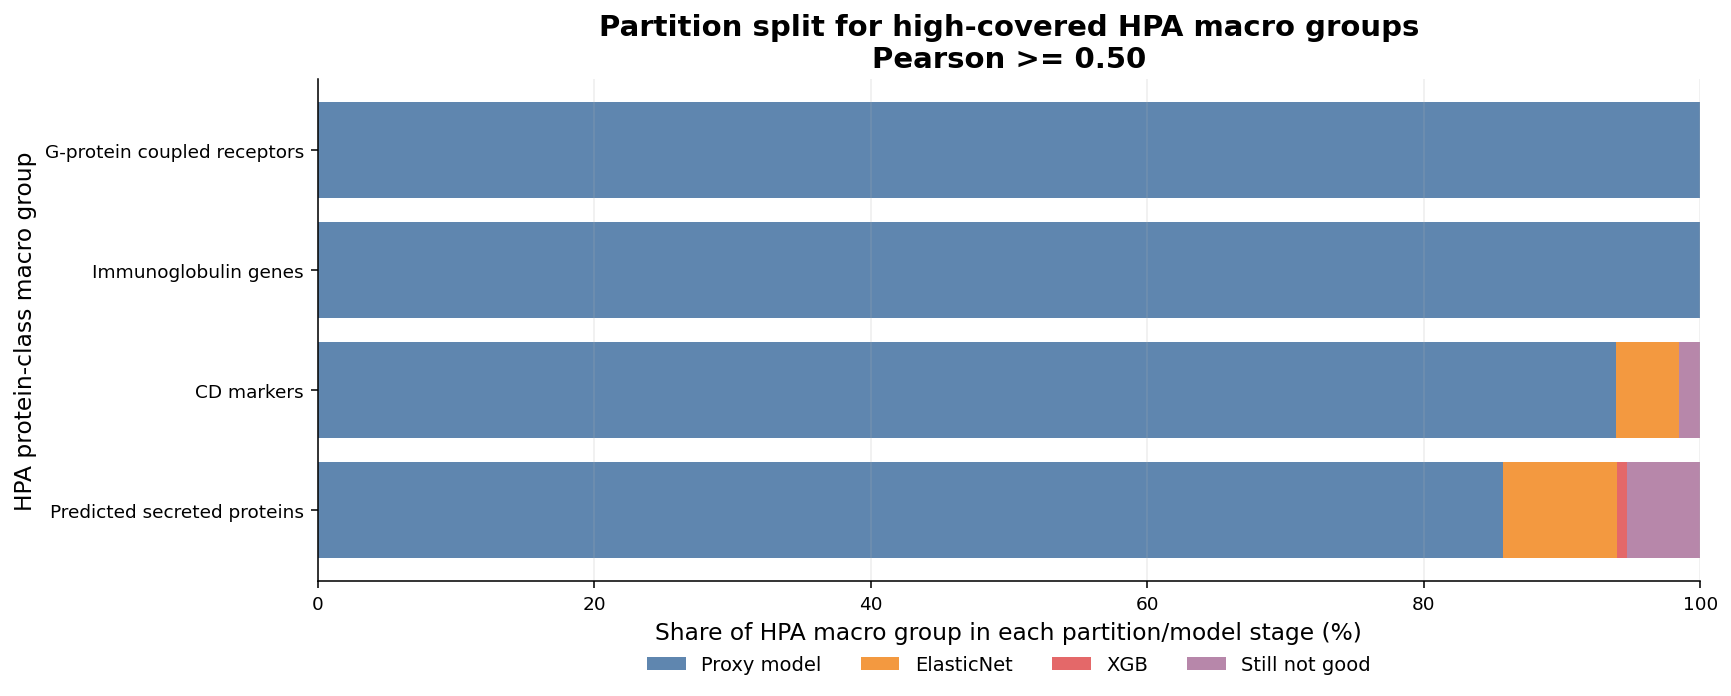

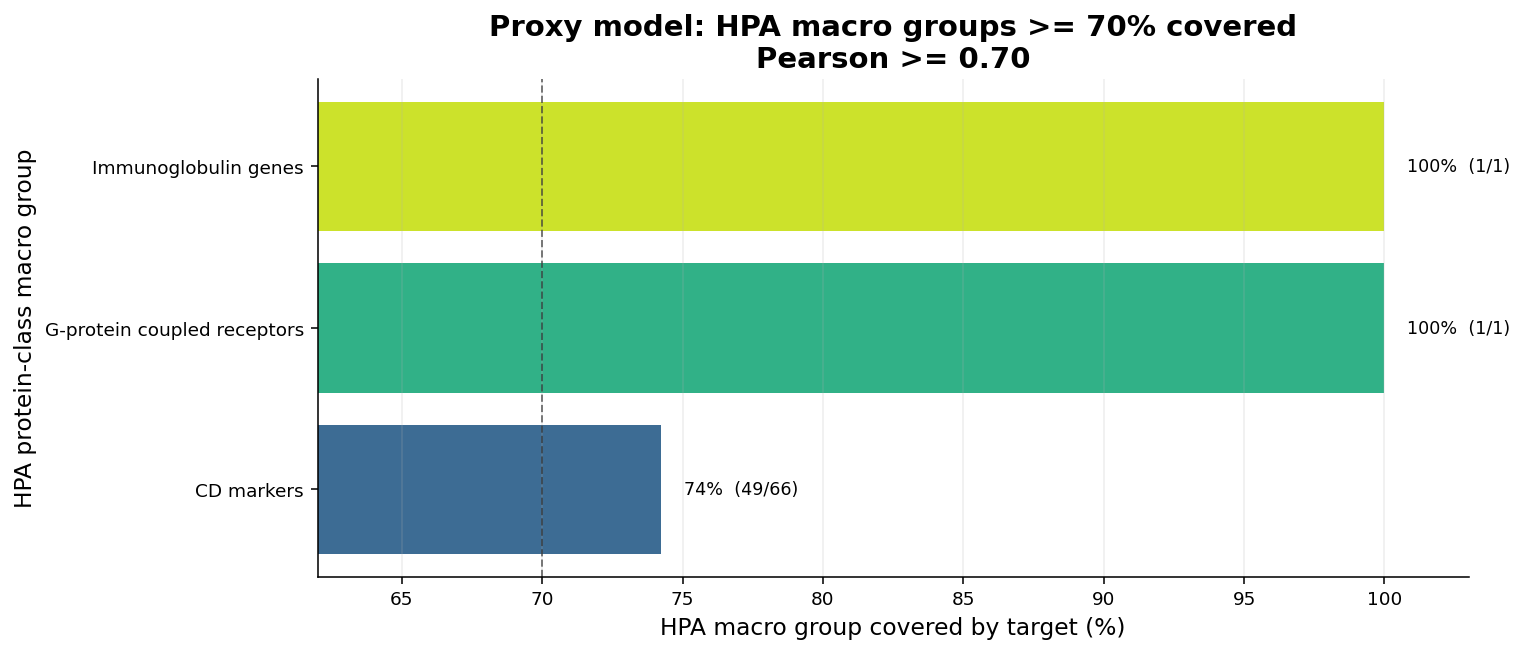

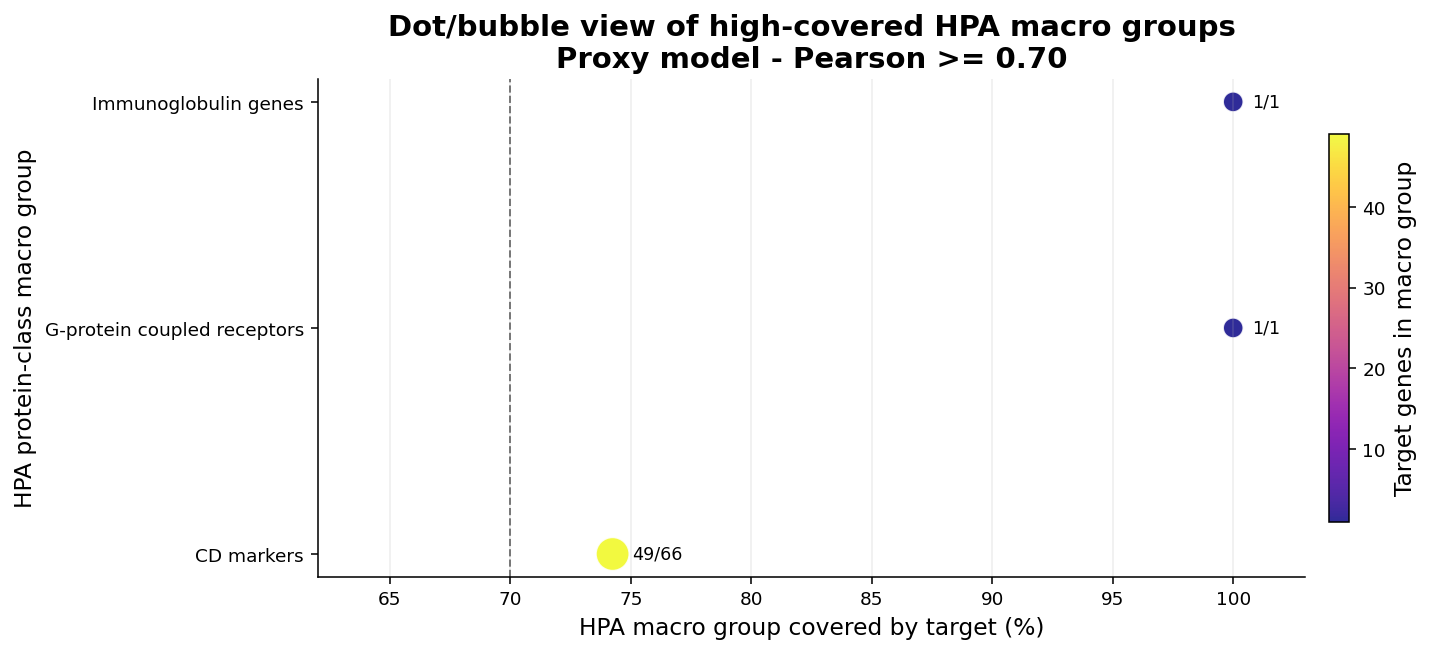

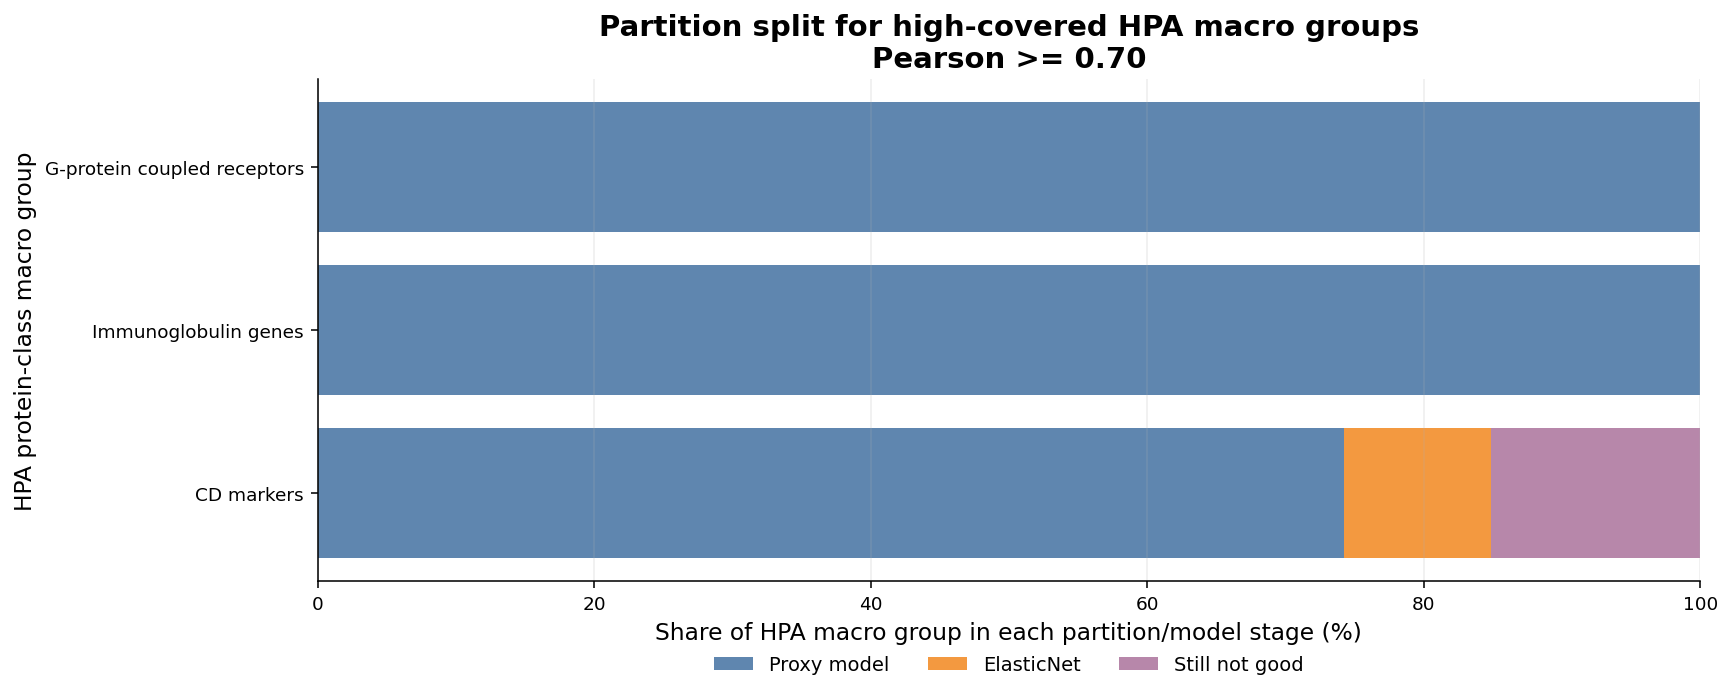

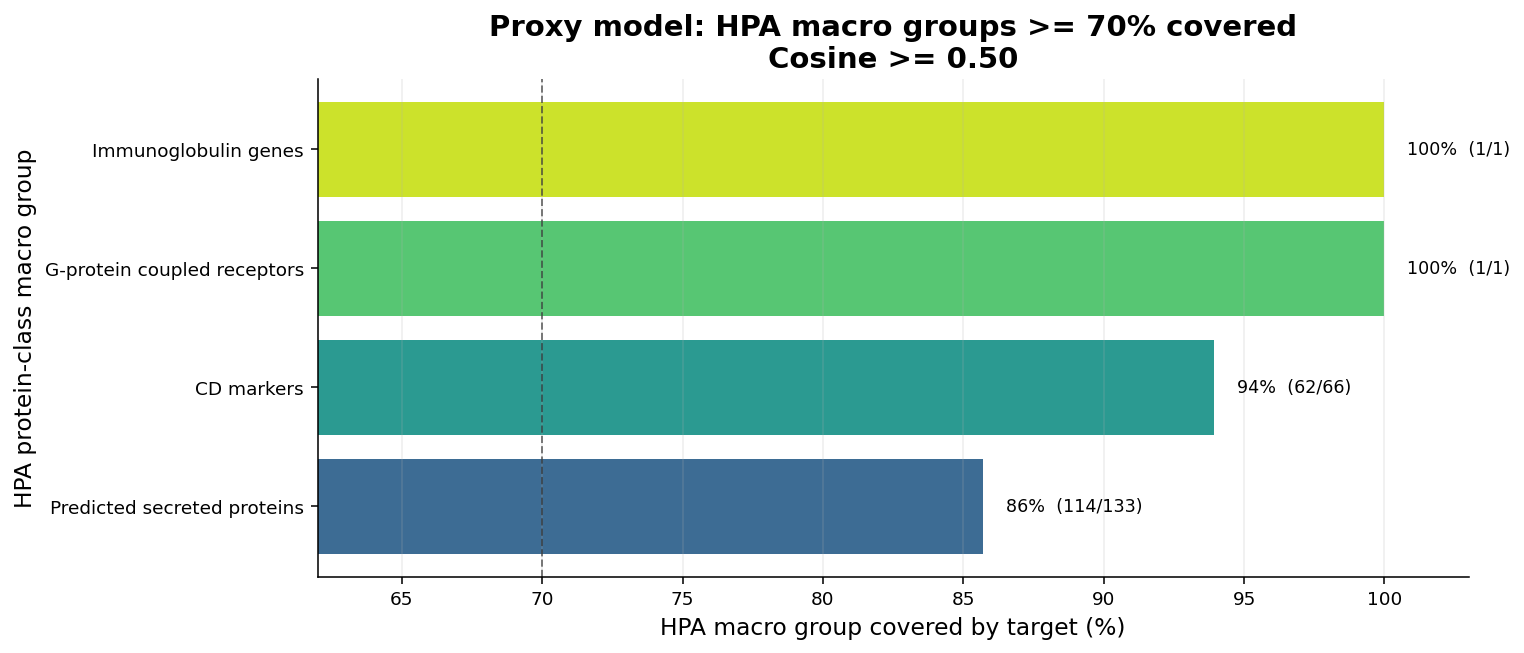

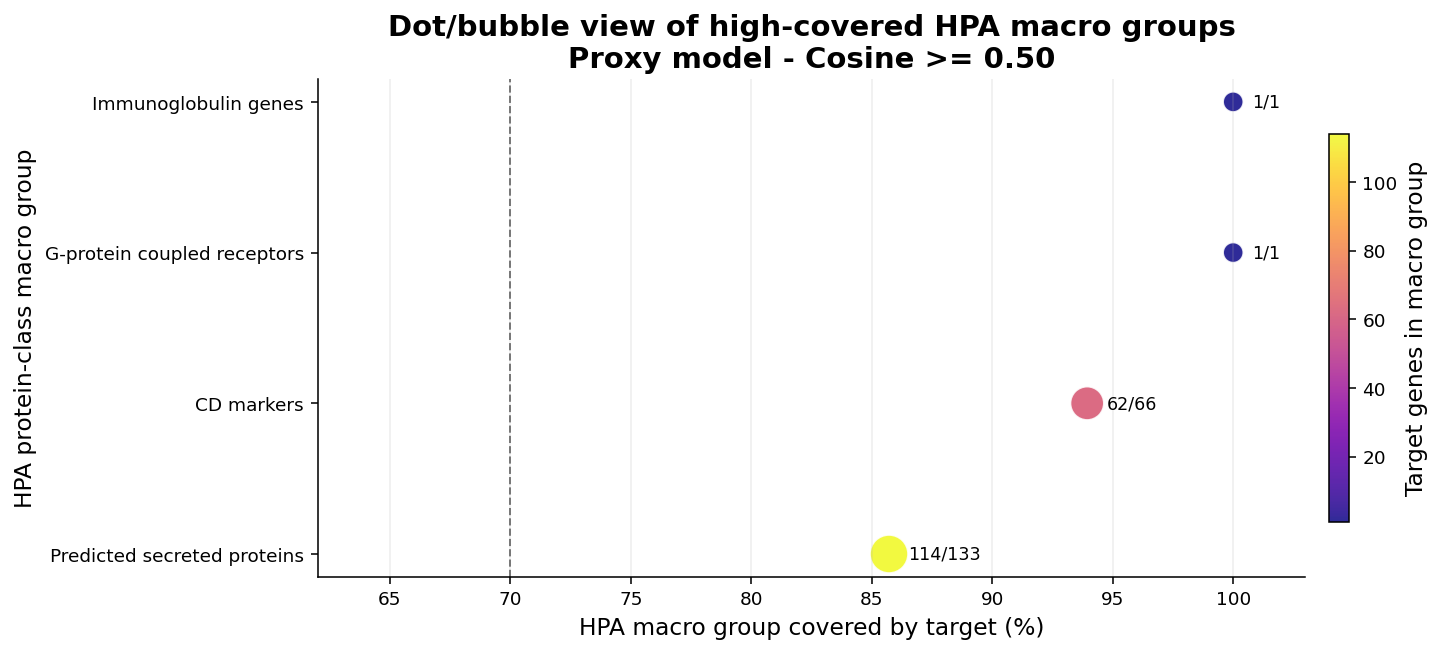

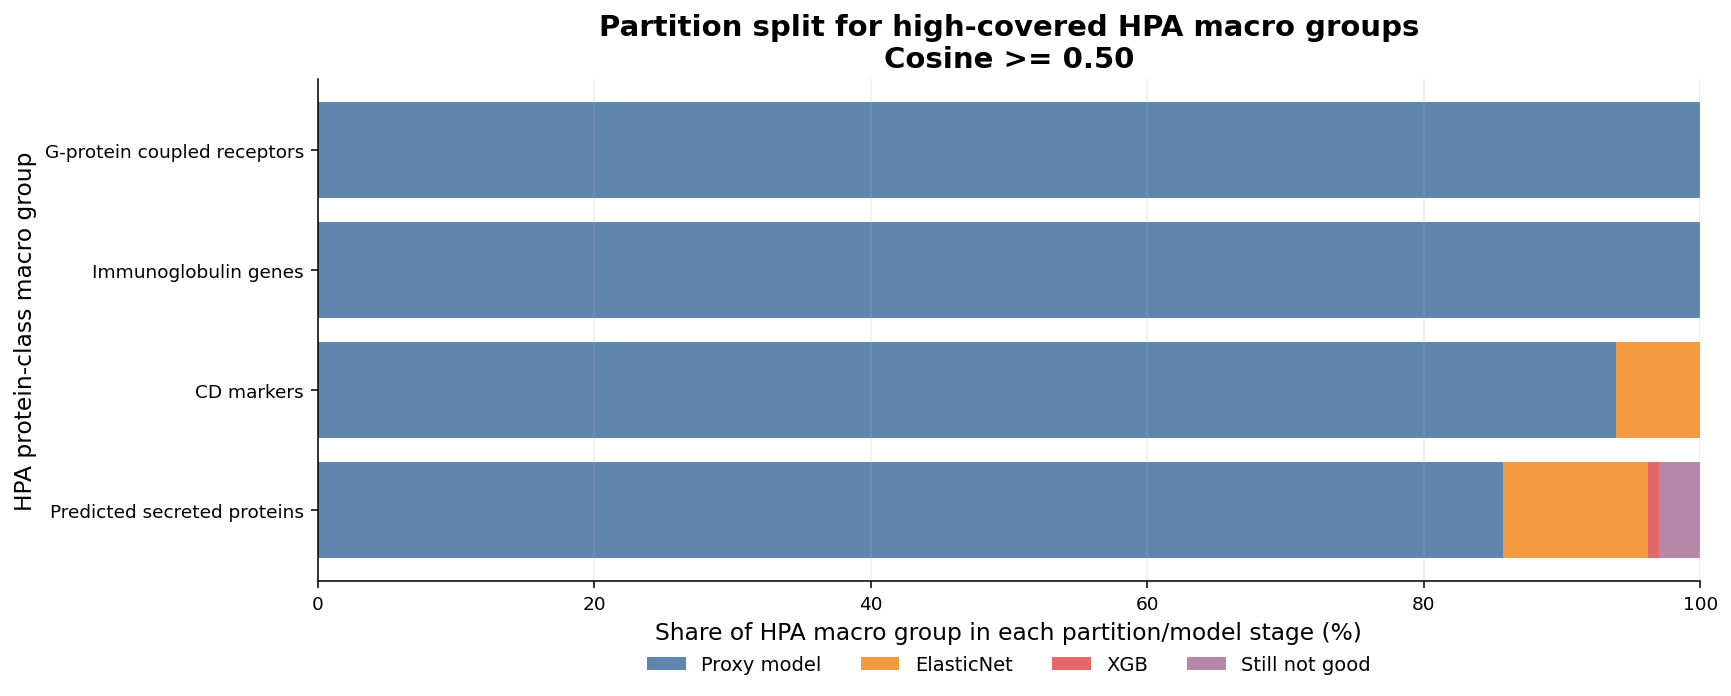

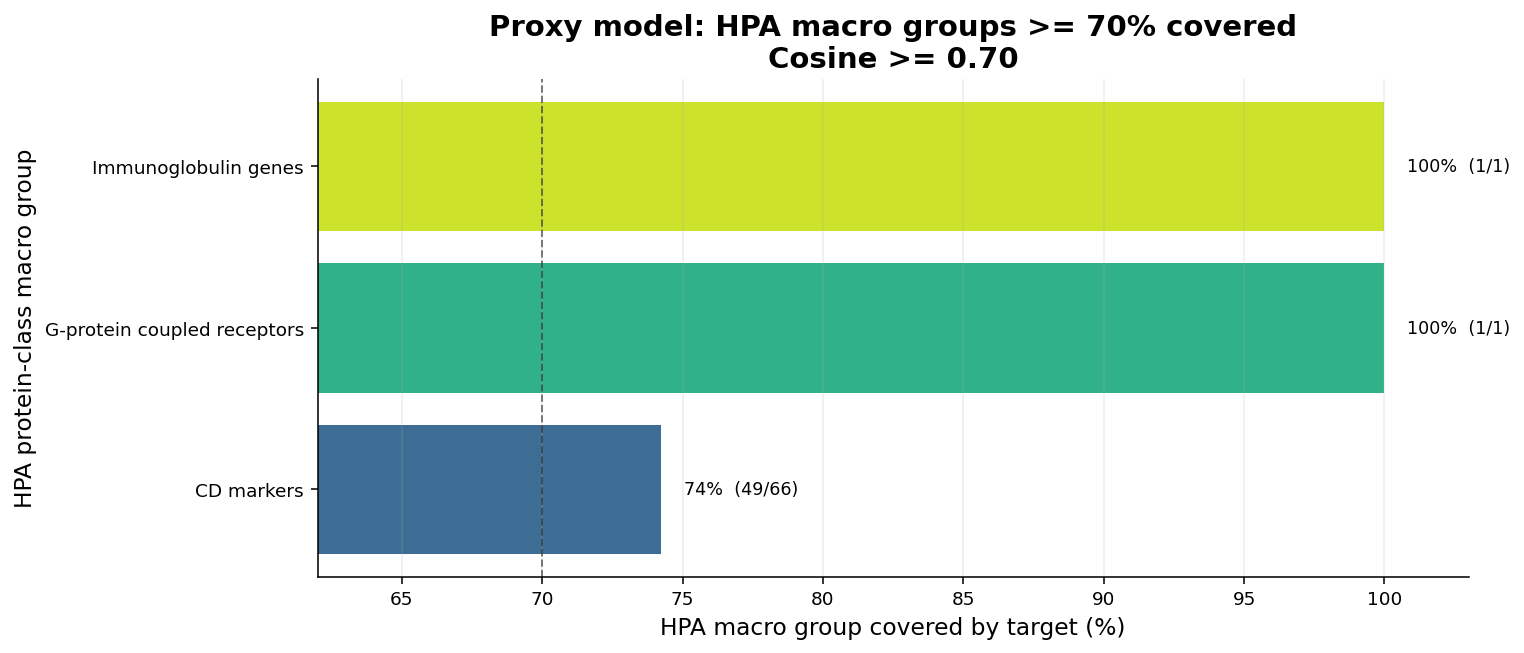

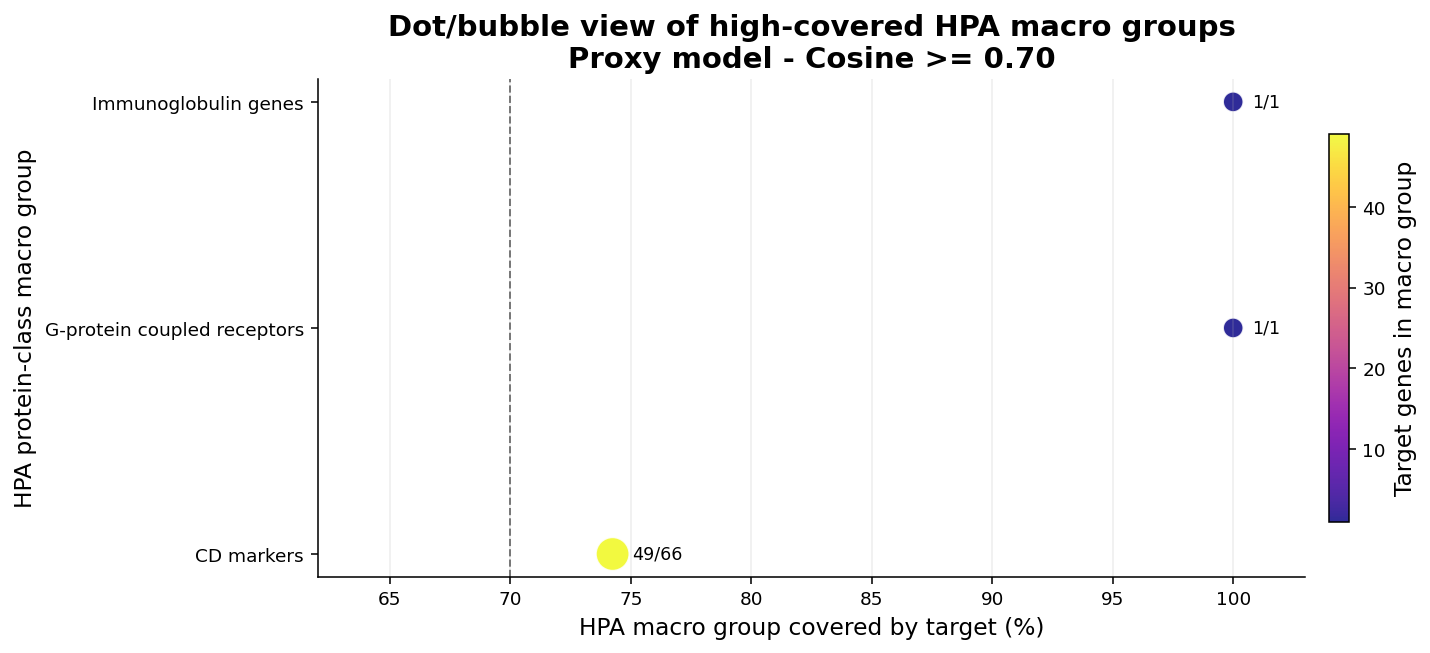

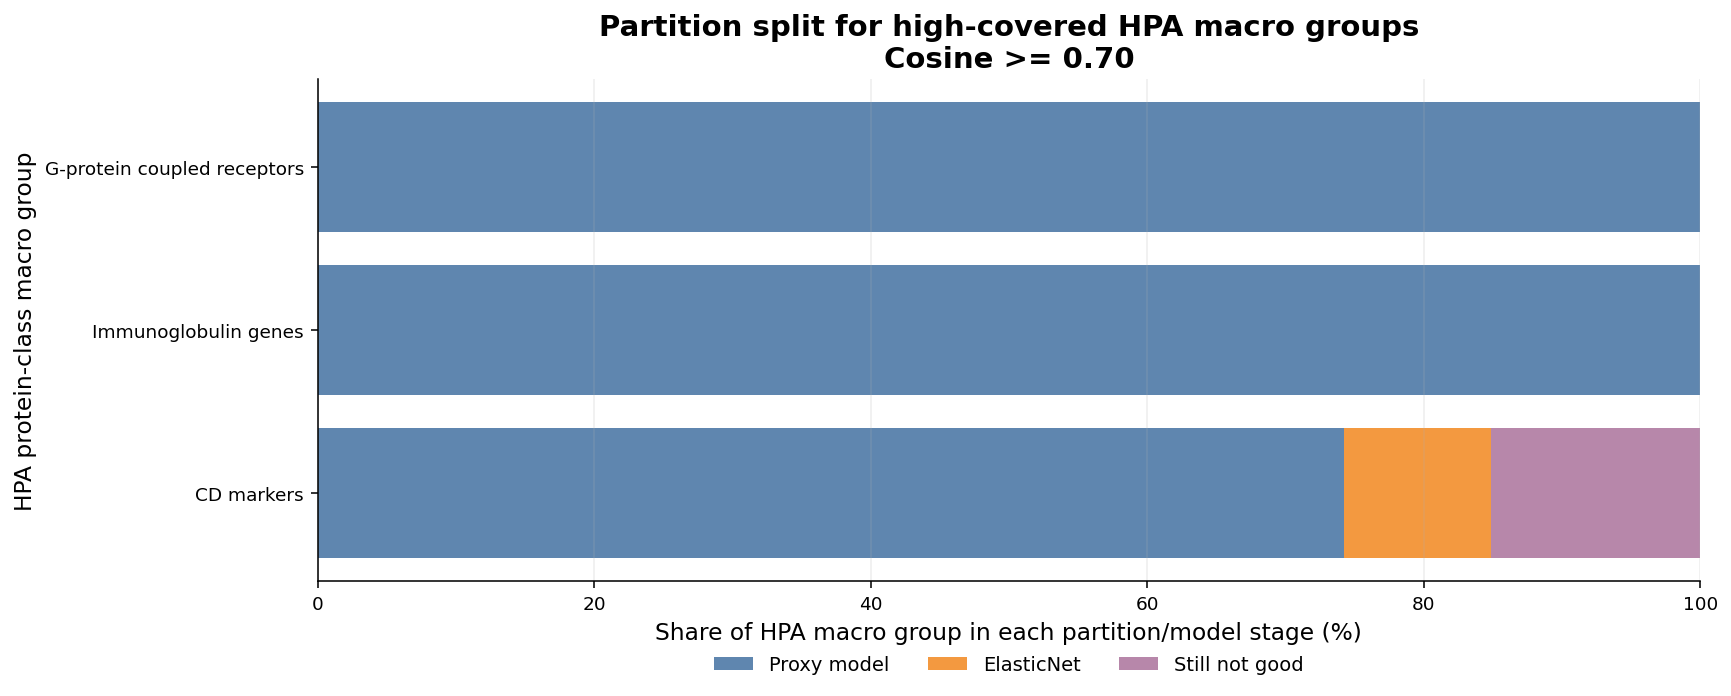


Figures saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_proxy_single_model_mse020_030_outputs\figures
High-coverage bar plots created: 4
High-coverage dot/bubble plots created: 4
High-coverage partition-split plots created: 4
Tables saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_proxy_single_model_mse020_030_outputs\tables


## ElasticNet

Stage groups used as numerator: ['ElasticNet']

Compact HPA macro-class coverage summary
source_id dataset metric_family threshold_name  macro_classes_with_denominator  target_gene_macro_memberships  median_pct_macro_captured  max_pct_macro_captured  macro_classes_ge_70pct
  proxy_z    CCLE        Cosine        >= 0.50                              18                           2796                      21.00                   44.44                       0
  proxy_z    CCLE        Cosine        >= 0.70                              18                           1094                       9.14                   33.33                       0
  proxy_z    CCLE           MSE        <= 0.20                              18                           3084                      22.93                   53.79                       0
  proxy_z    CCLE           MSE        <= 0.30                              18                           4433                      33.26                   77.93           

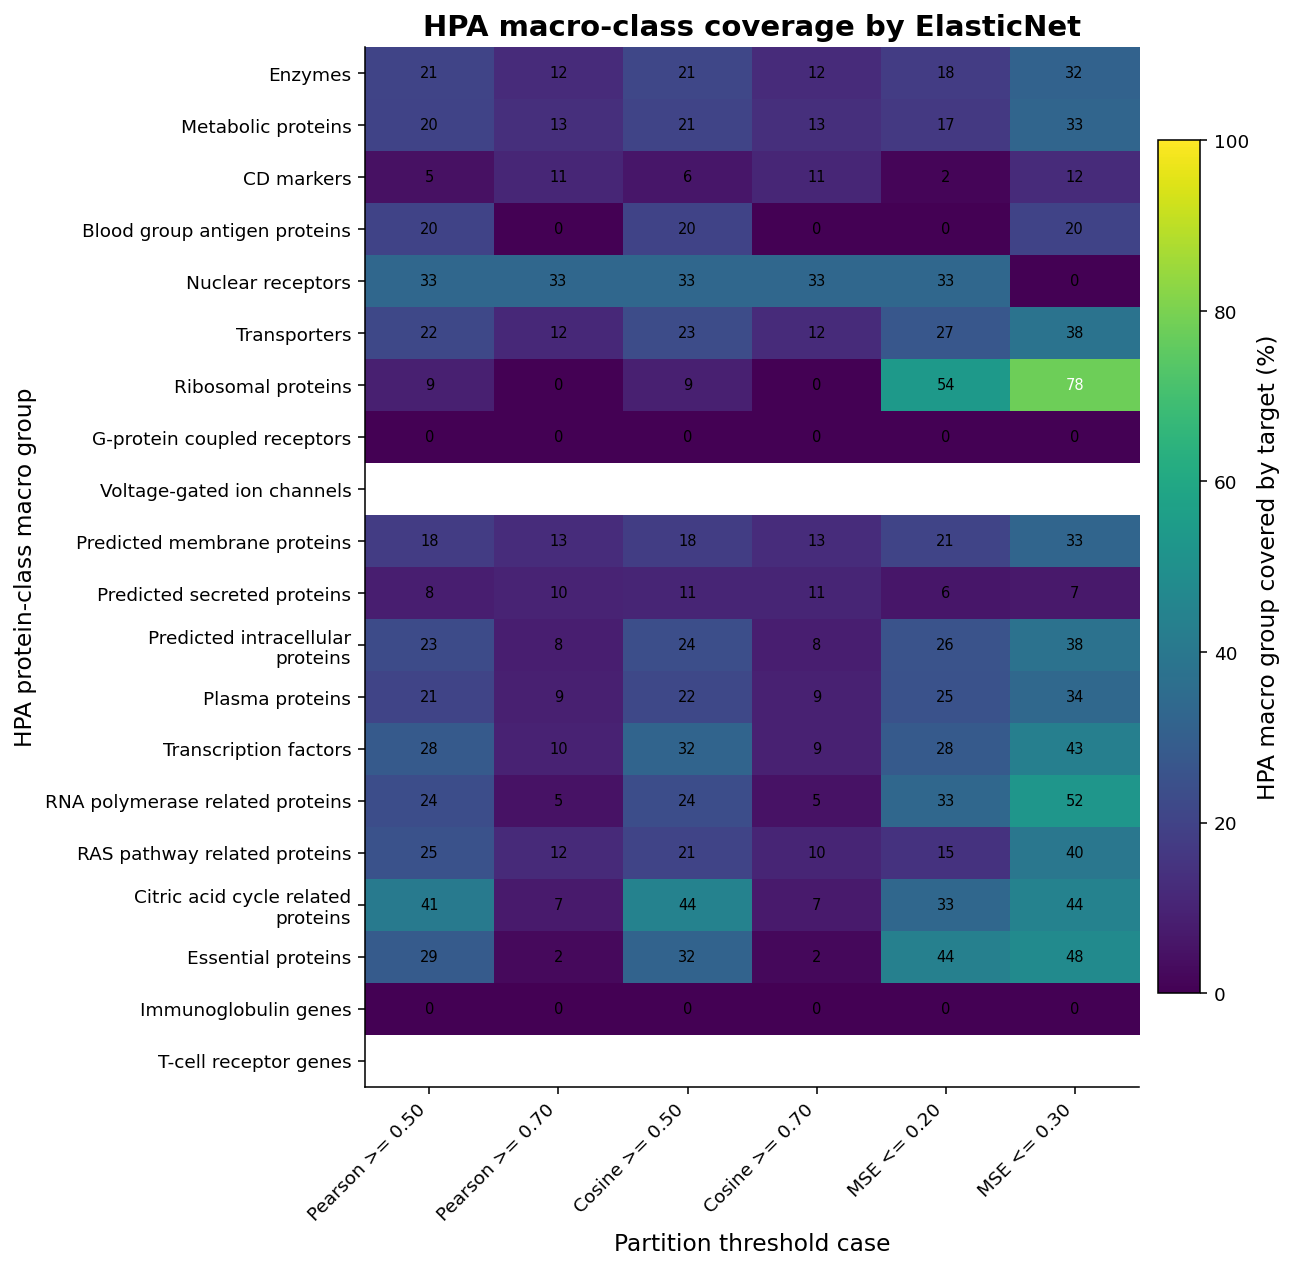

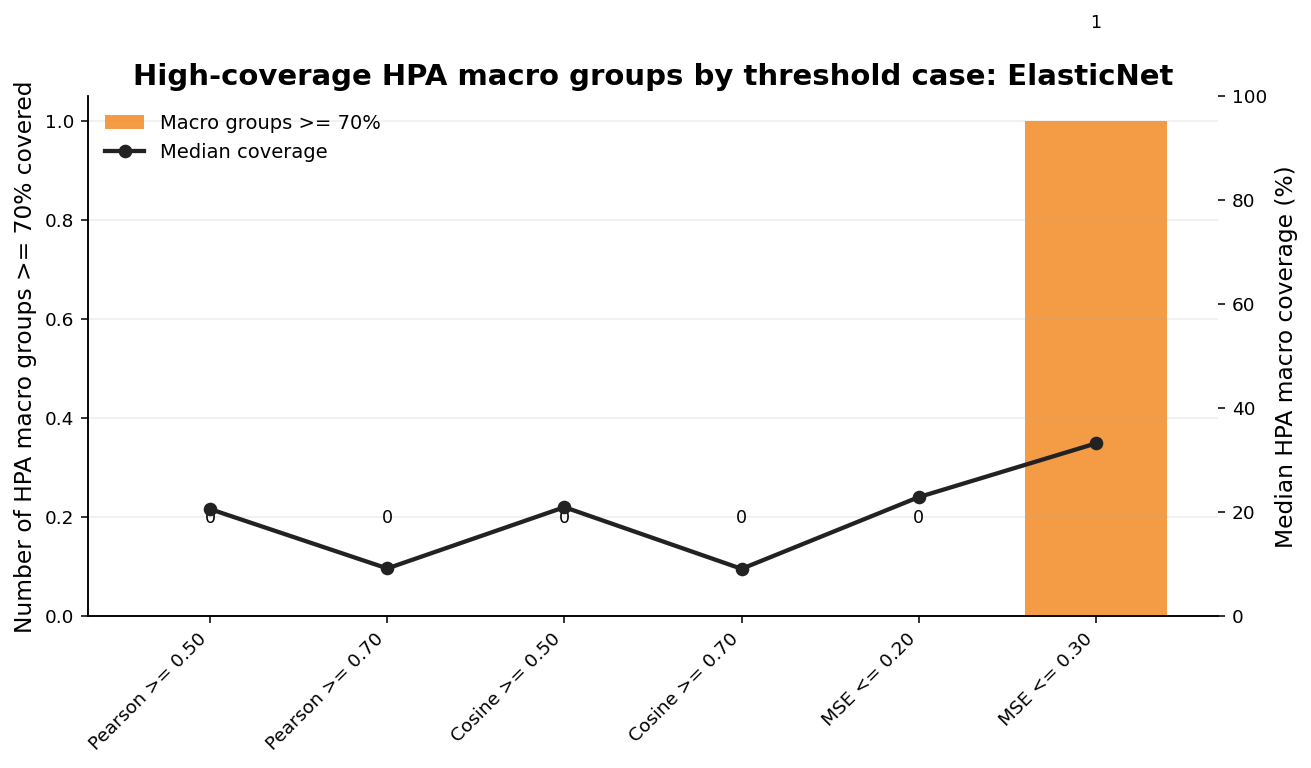

C:\Users\hp\AppData\Local\Temp\ipykernel_19564\3617896359.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap('magma').copy()


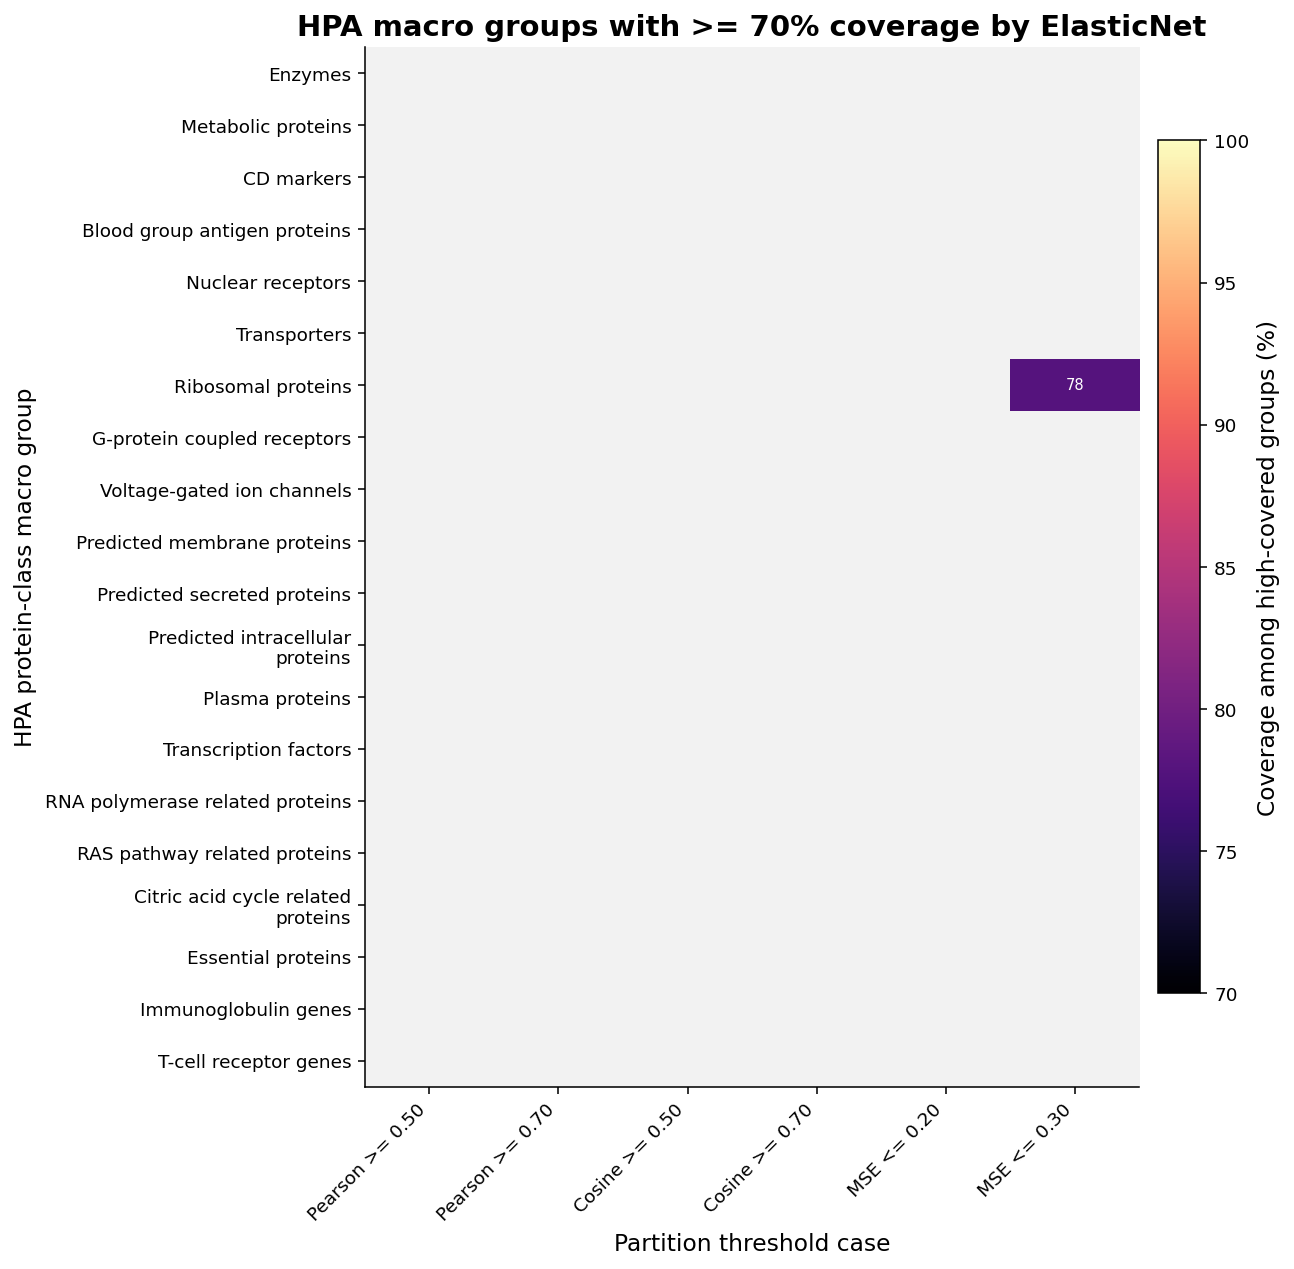

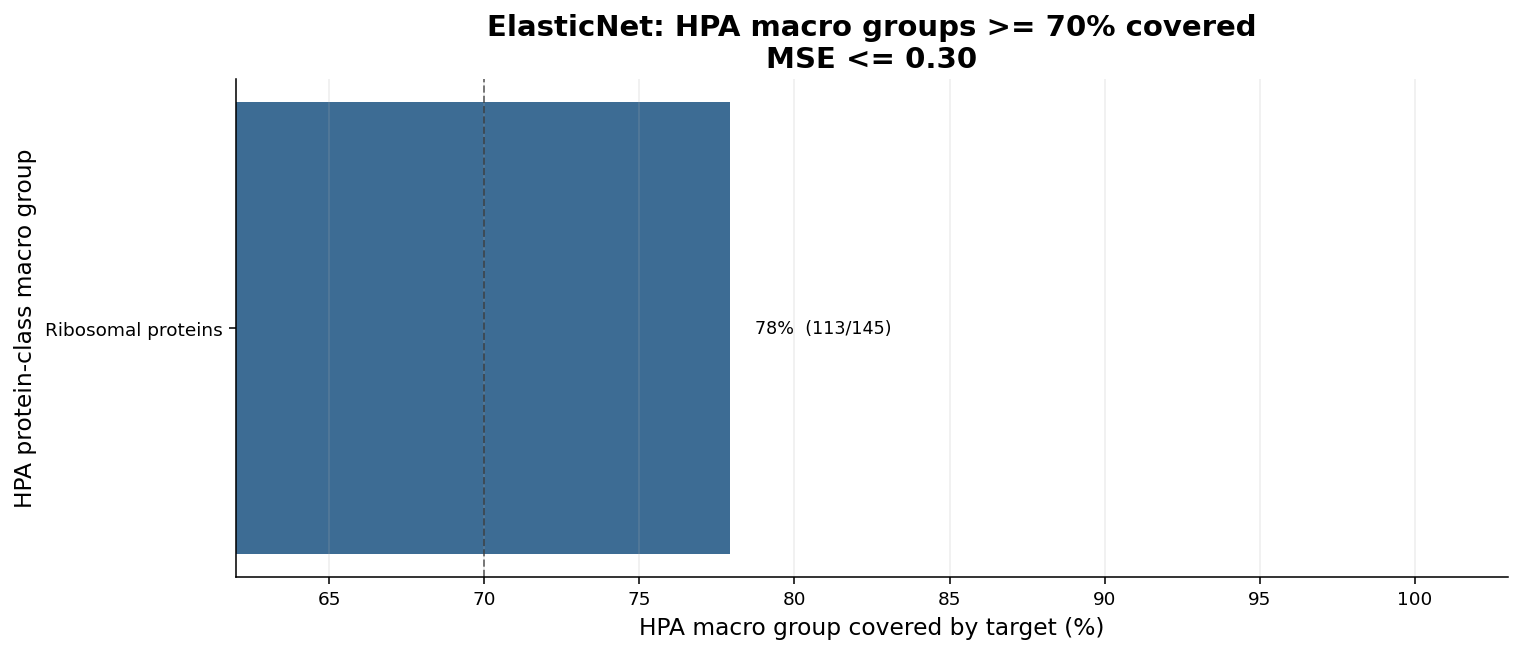

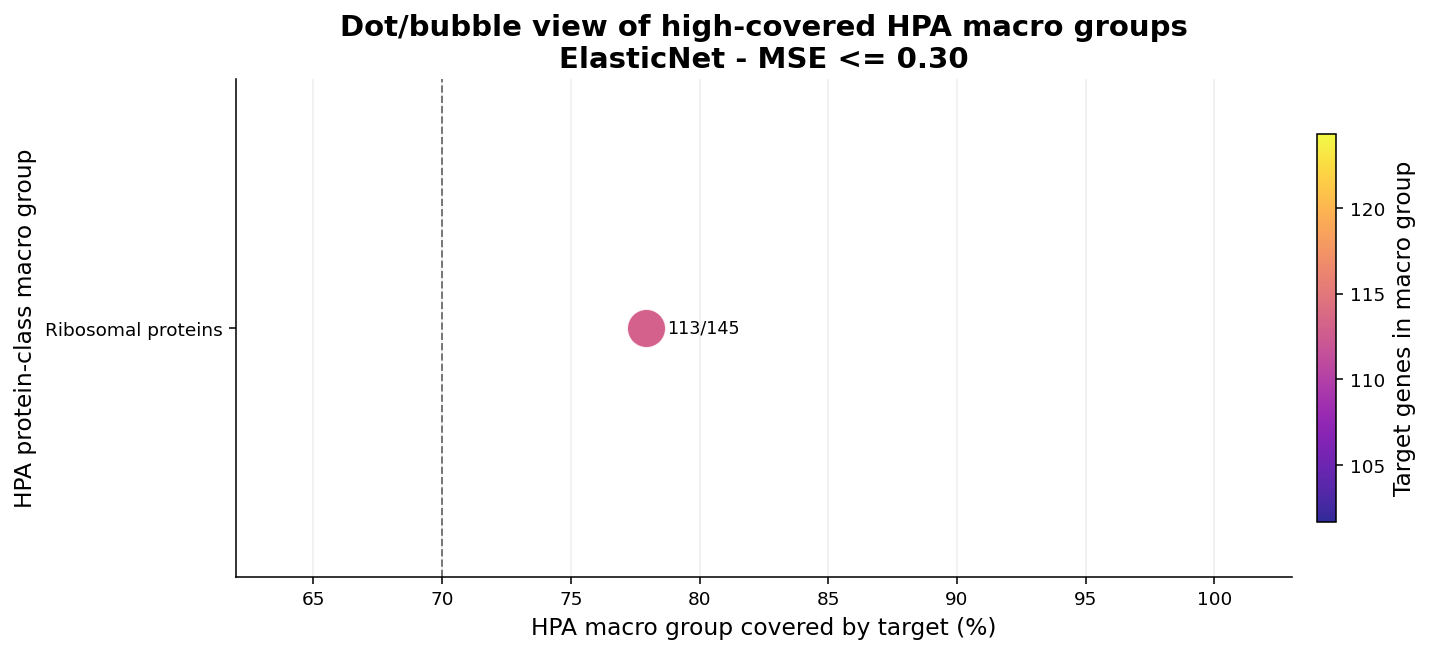

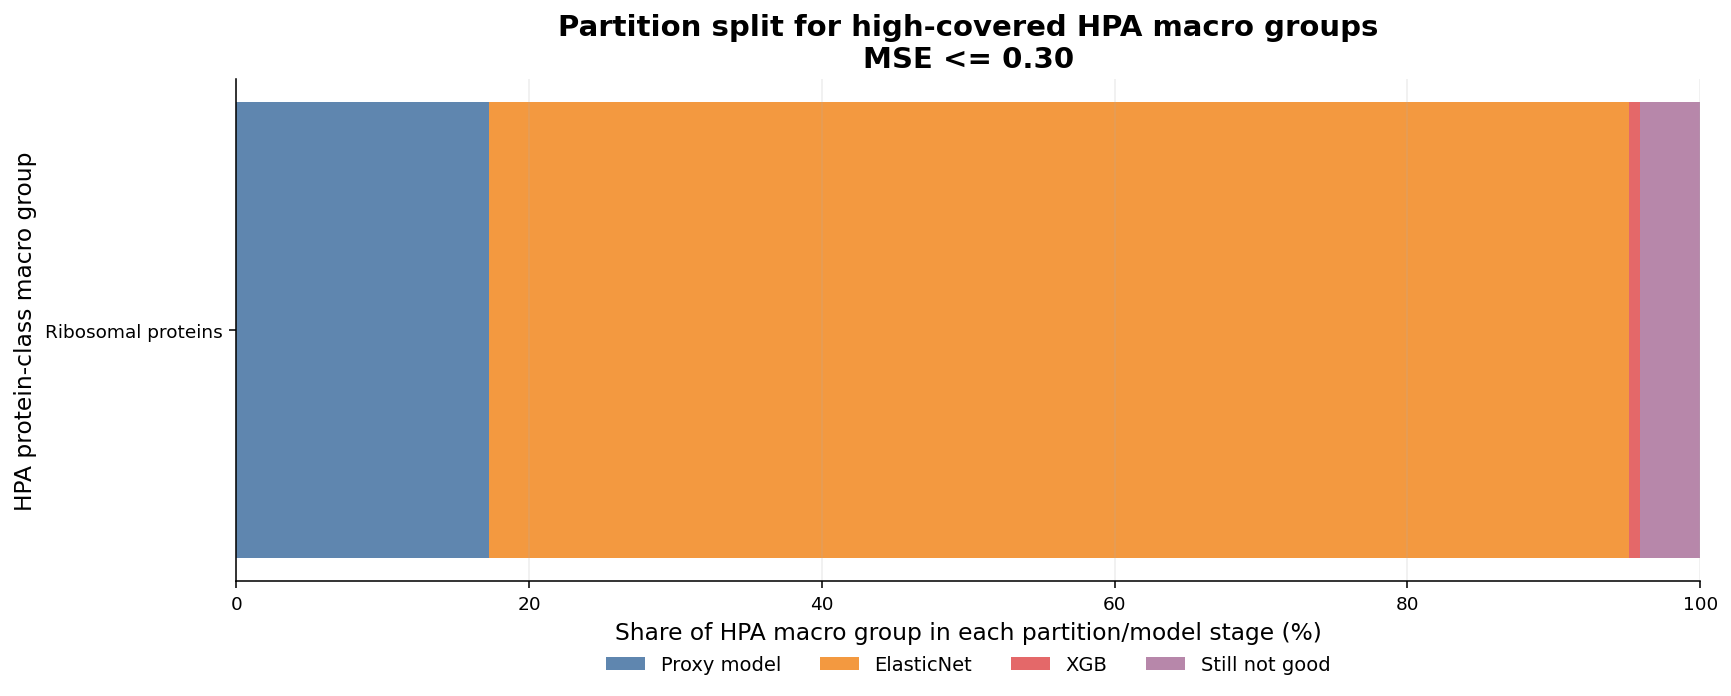


Figures saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_elasticnet_mse020_030_outputs\figures
High-coverage bar plots created: 1
High-coverage dot/bubble plots created: 1
High-coverage partition-split plots created: 1
Tables saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_elasticnet_mse020_030_outputs\tables


## XGB

Stage groups used as numerator: ['XGB']

Compact HPA macro-class coverage summary
source_id dataset metric_family threshold_name  macro_classes_with_denominator  target_gene_macro_memberships  median_pct_macro_captured  max_pct_macro_captured  macro_classes_ge_70pct
  proxy_z    CCLE        Cosine        >= 0.50                              18                            250                       1.17                    3.70                       0
  proxy_z    CCLE        Cosine        >= 0.70                              18                             78                       0.06                    1.21                       0
  proxy_z    CCLE           MSE        <= 0.20                              18                            198                       1.04                    2.42                       0
  proxy_z    CCLE           MSE        <= 0.30                              18                            136                       0.83                    1.62                  

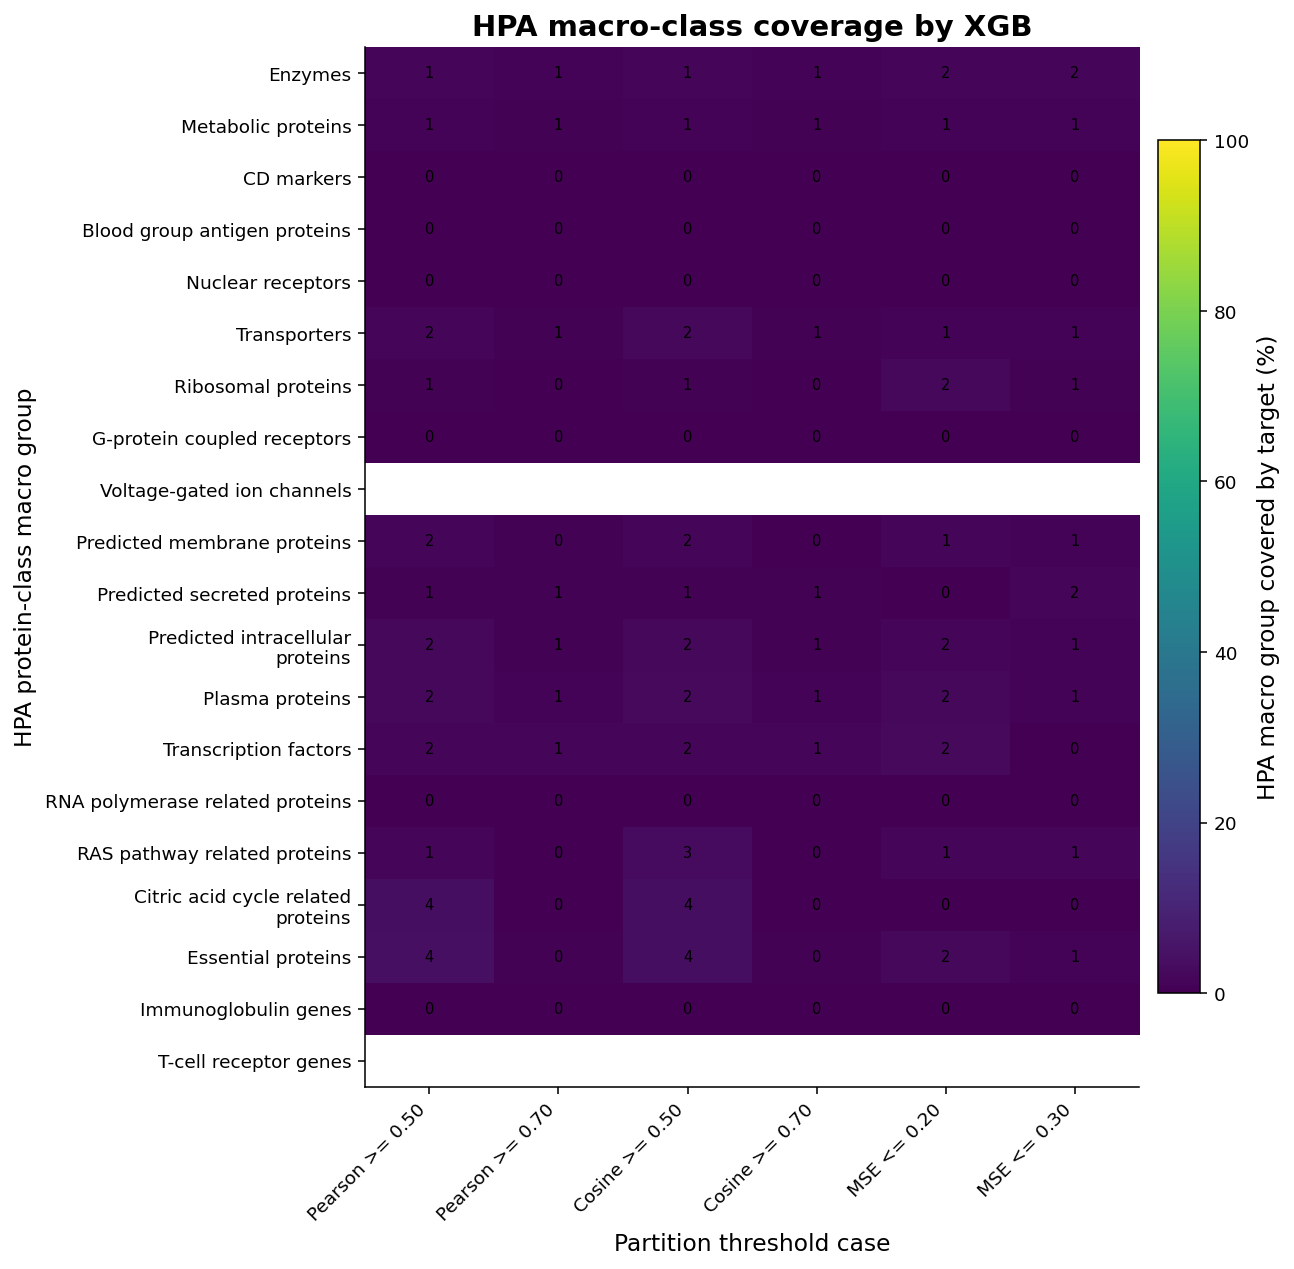

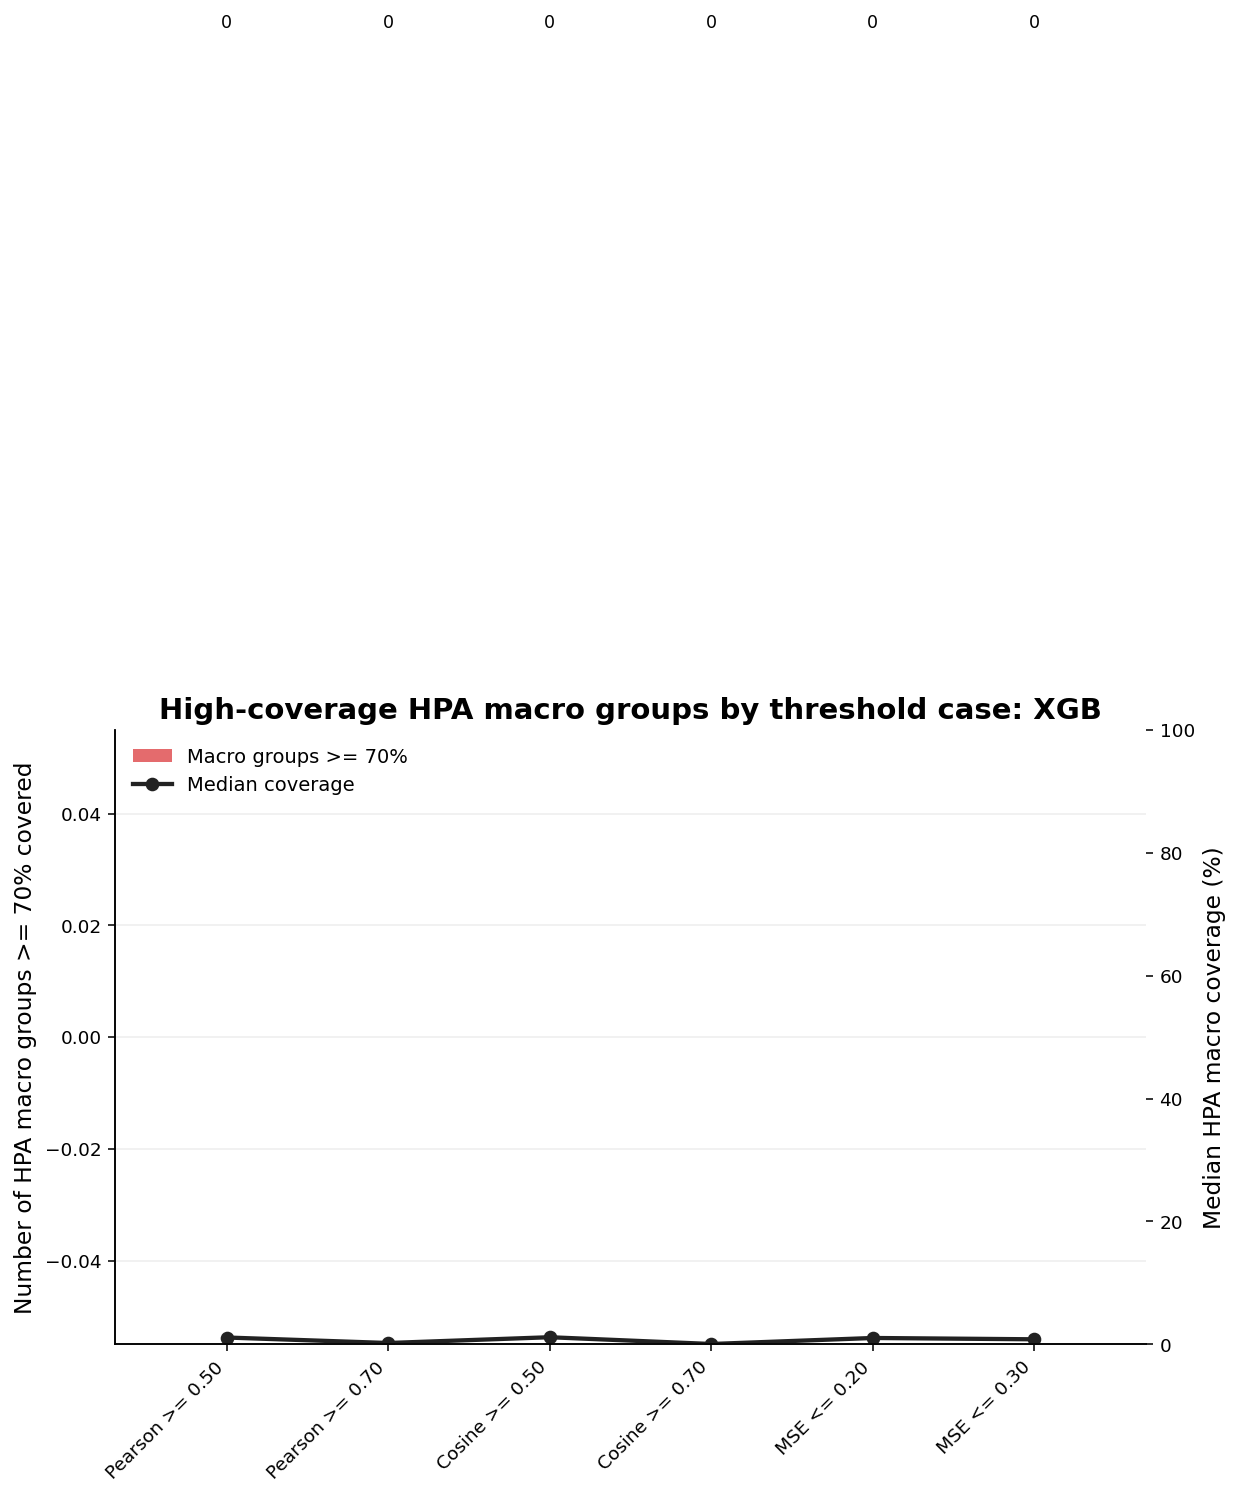


Figures saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_xgb_mse020_030_outputs\figures
High-coverage bar plots created: 0
High-coverage dot/bubble plots created: 0
High-coverage partition-split plots created: 0
Tables saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_xgb_mse020_030_outputs\tables


## Still not good

Stage groups used as numerator: ['Still not good']

Compact HPA macro-class coverage summary
source_id dataset metric_family threshold_name  macro_classes_with_denominator  target_gene_macro_memberships  median_pct_macro_captured  max_pct_macro_captured  macro_classes_ge_70pct
  proxy_z    CCLE        Cosine        >= 0.50                              18                           3232                      19.34                   90.34                       1
  proxy_z    CCLE        Cosine        >= 0.70                              18                           8487                      64.50                  100.00                       6
  proxy_z    CCLE           MSE        <= 0.20                              18                           8071                      71.04                  100.00                       9
  proxy_z    CCLE           MSE        <= 0.30                              18                           4226                      39.63                  100.00       

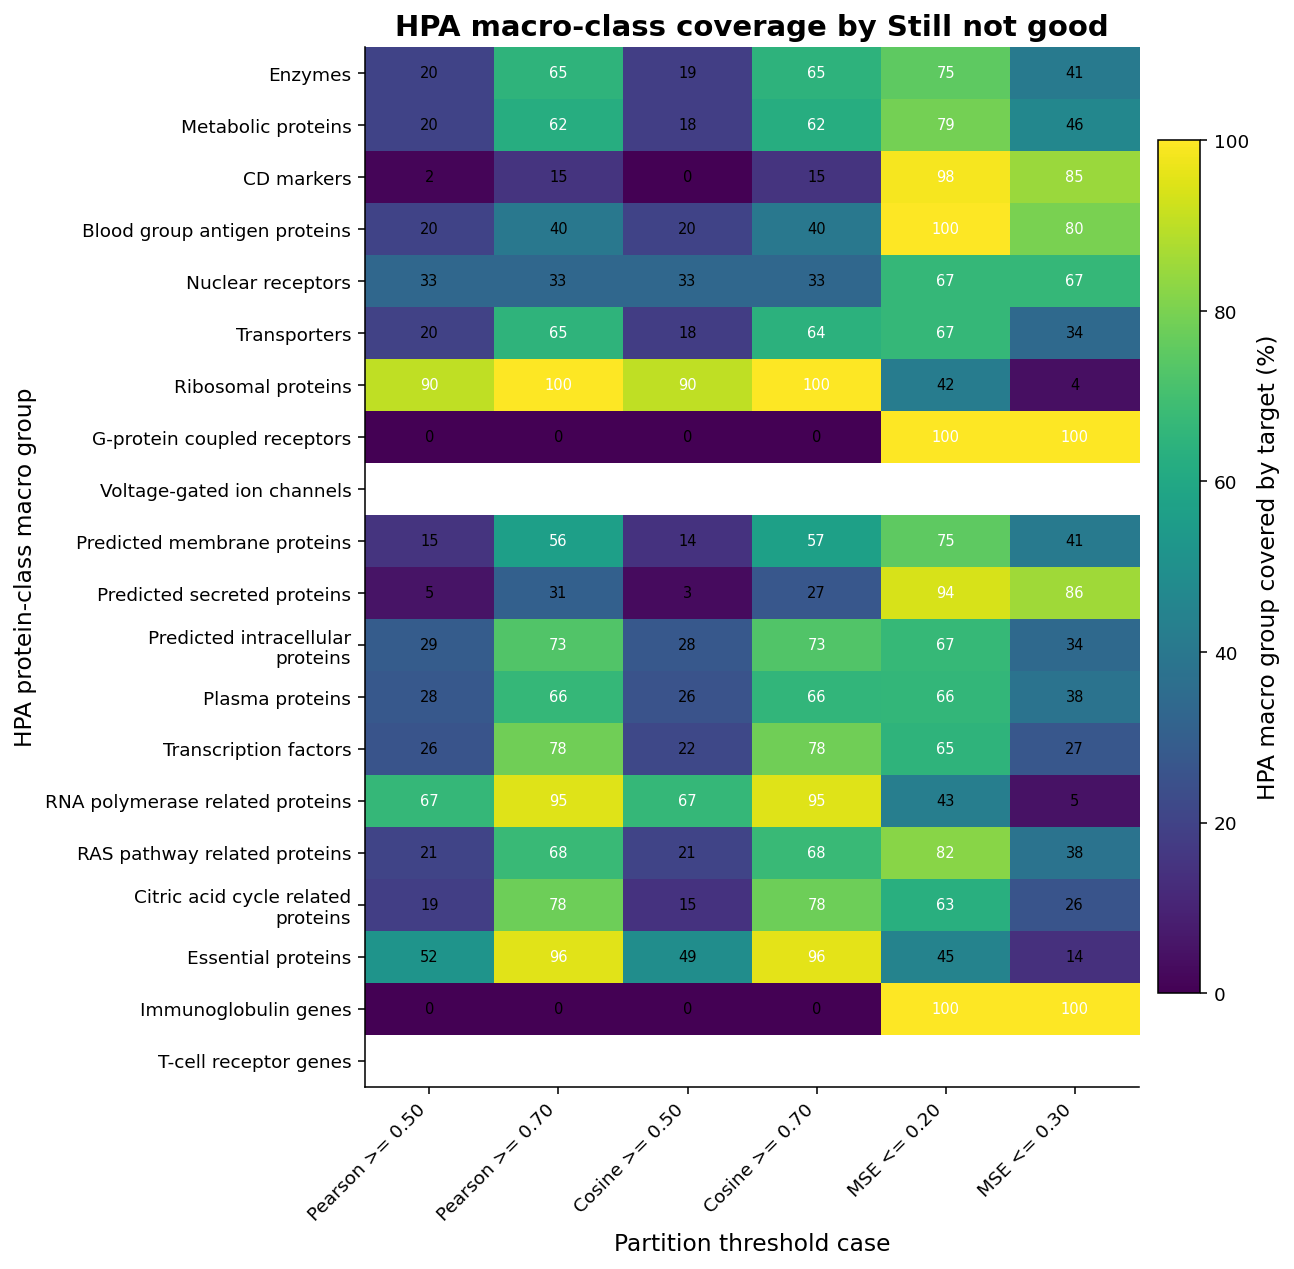

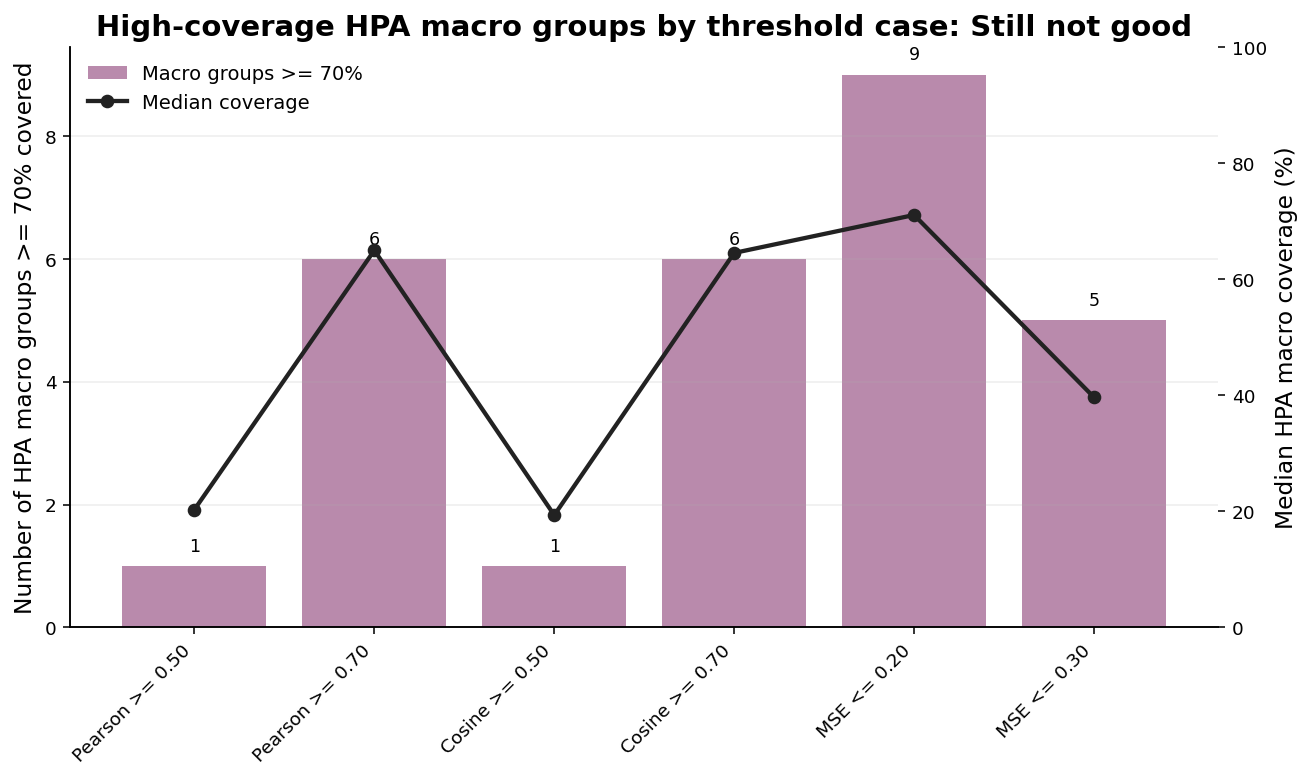

C:\Users\hp\AppData\Local\Temp\ipykernel_19564\3617896359.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap('magma').copy()


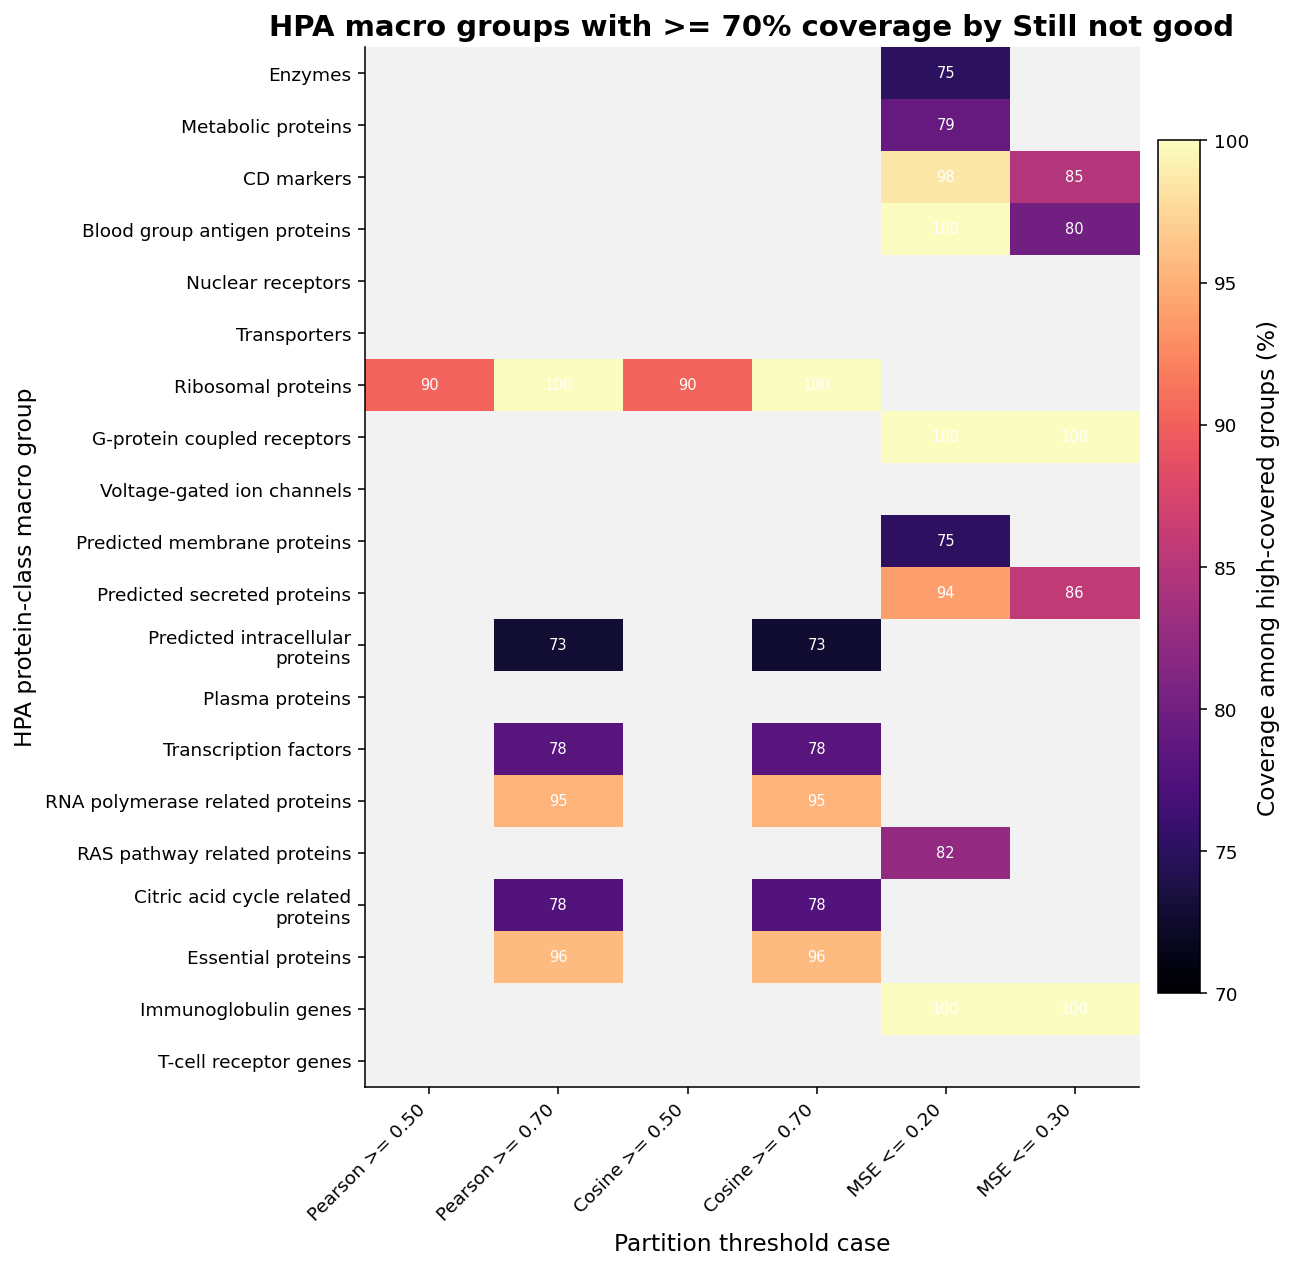

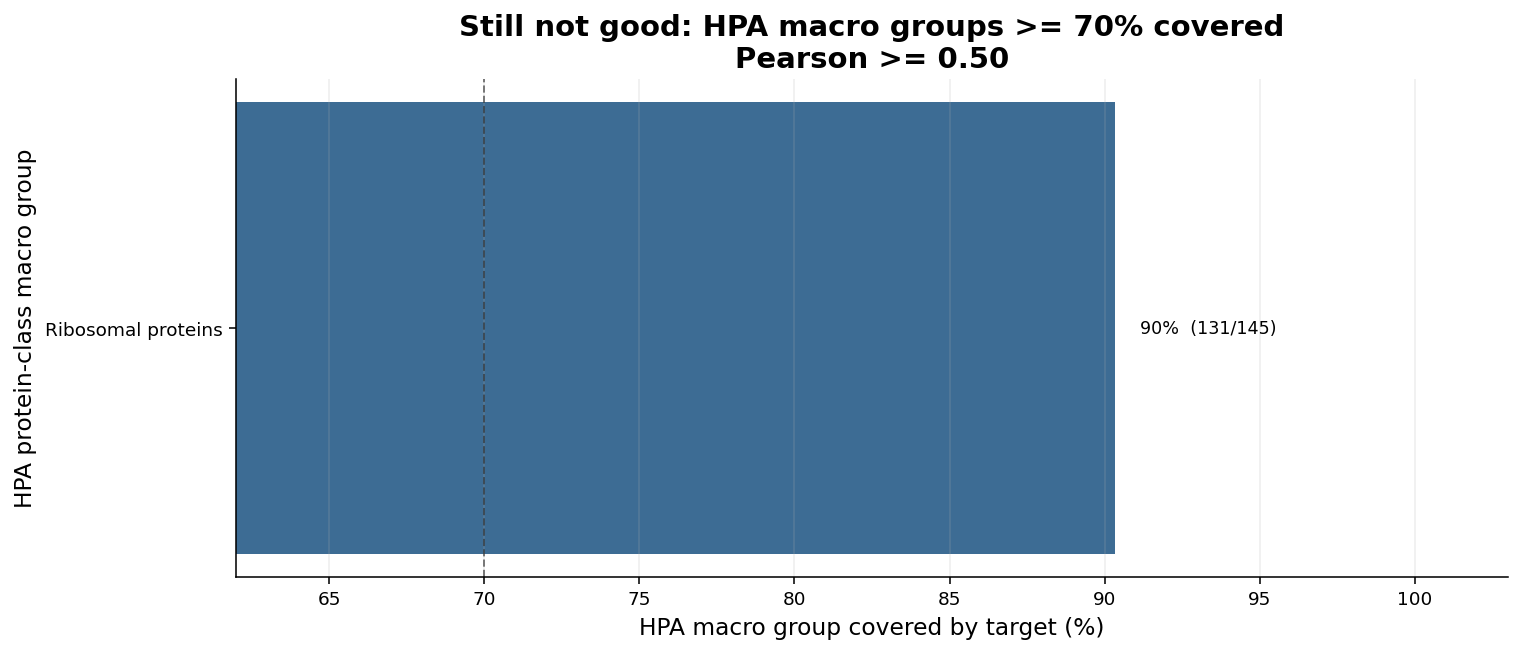

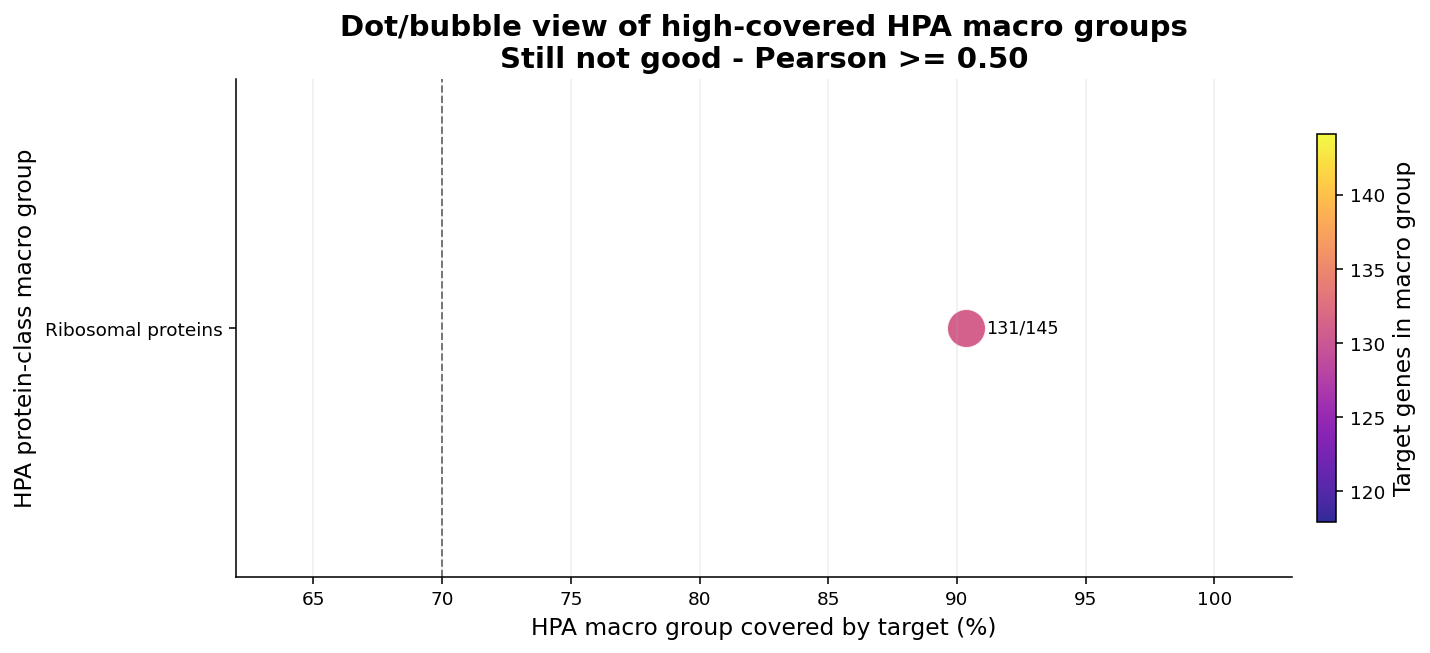

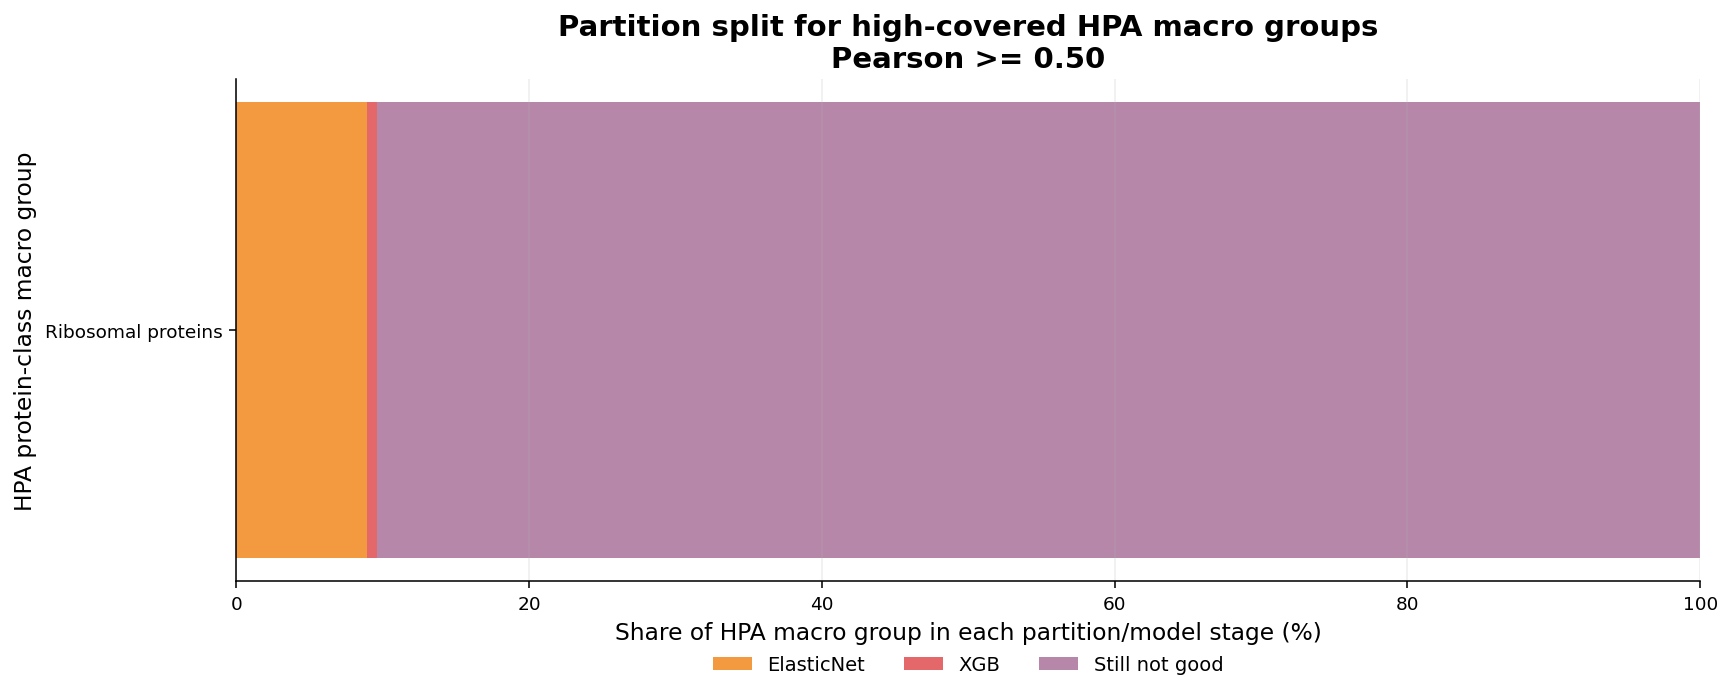

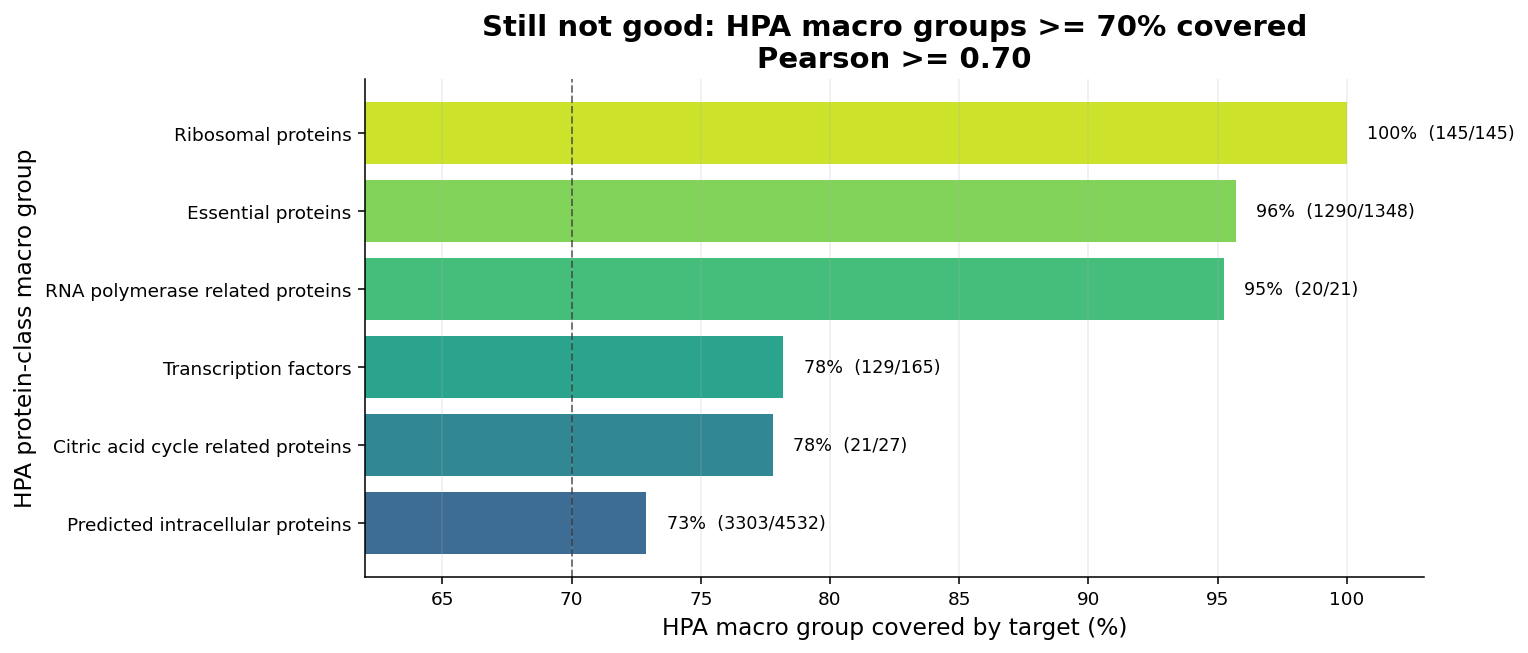

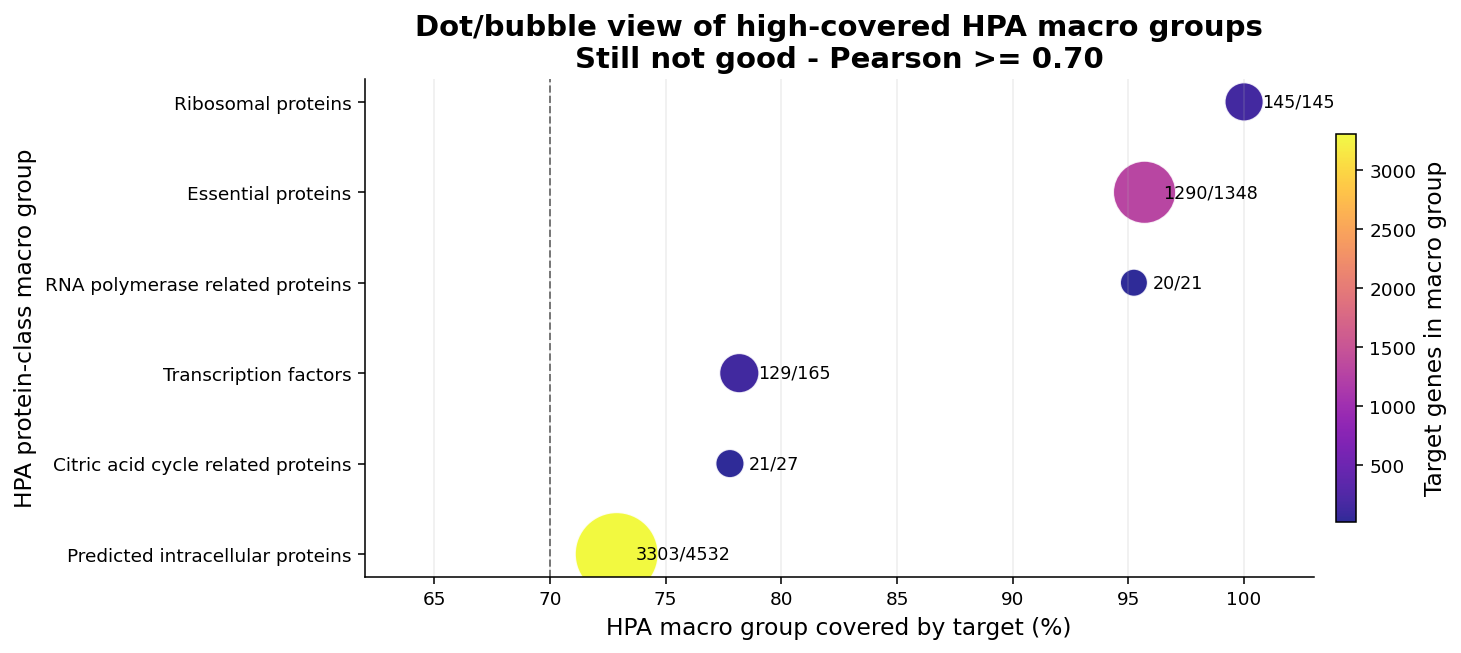

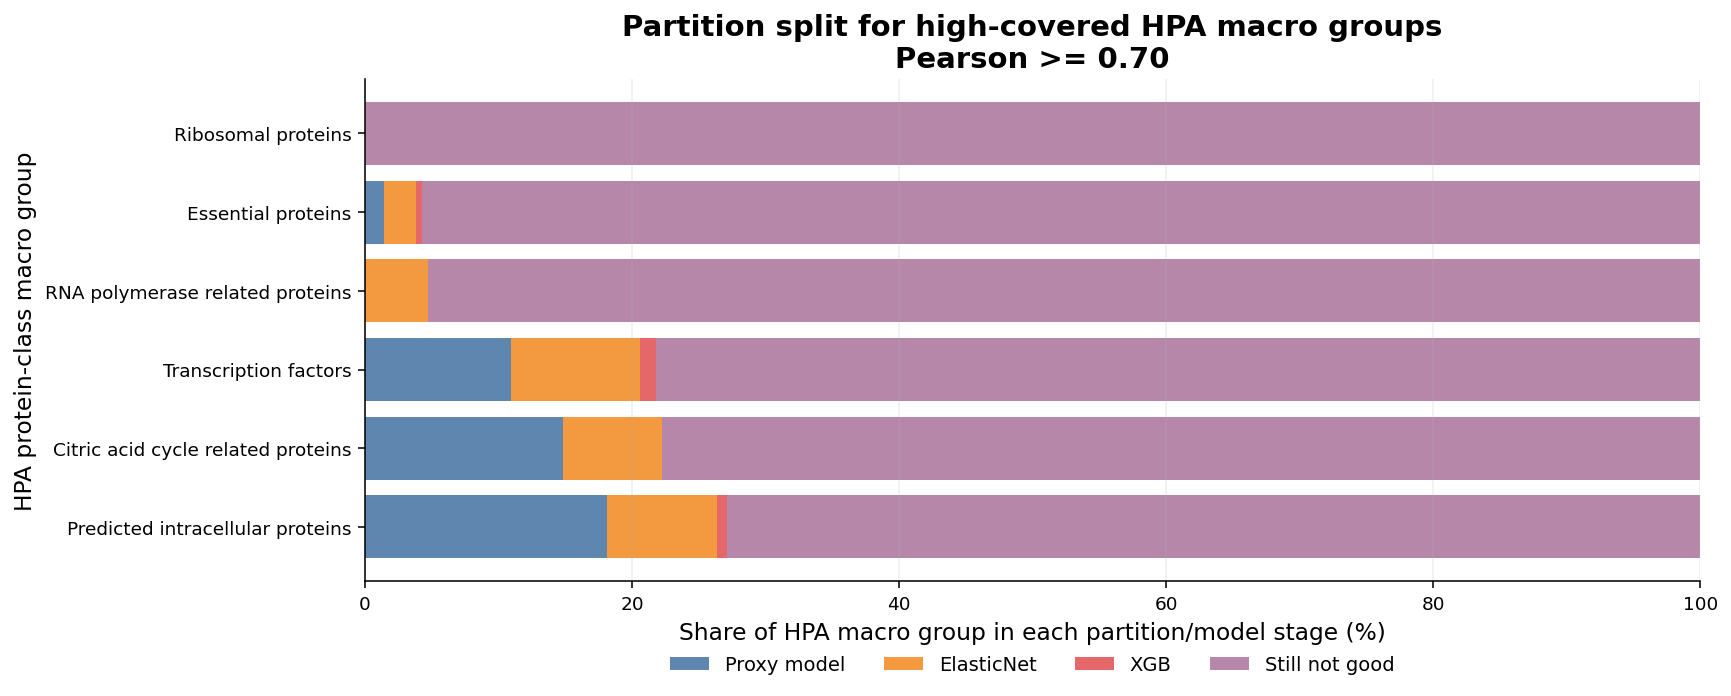

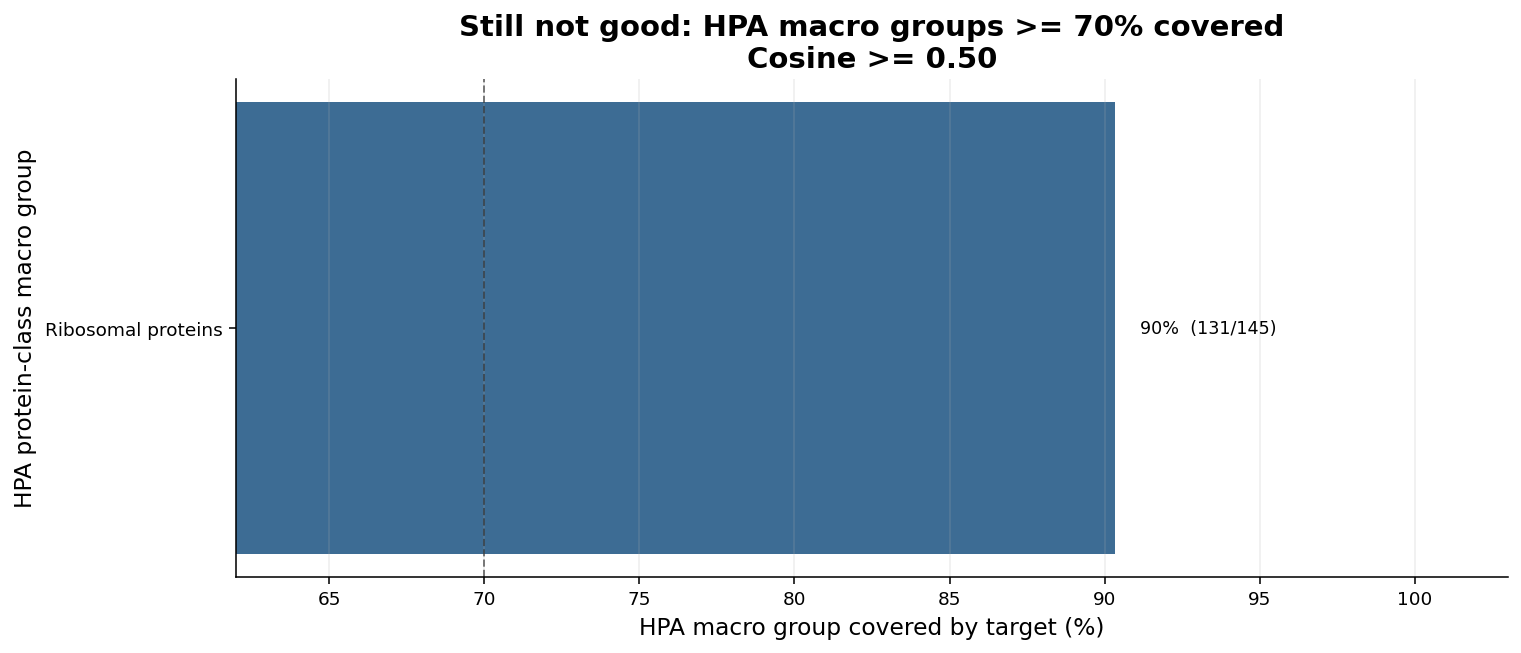

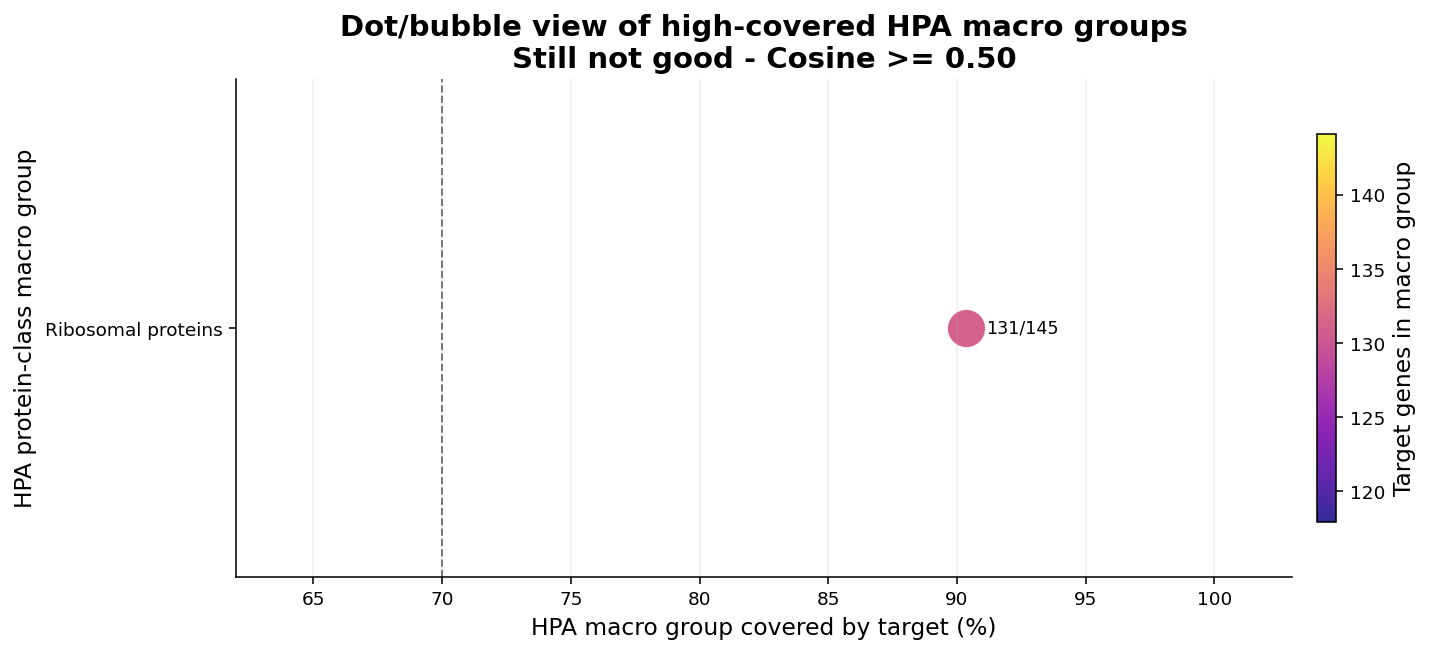

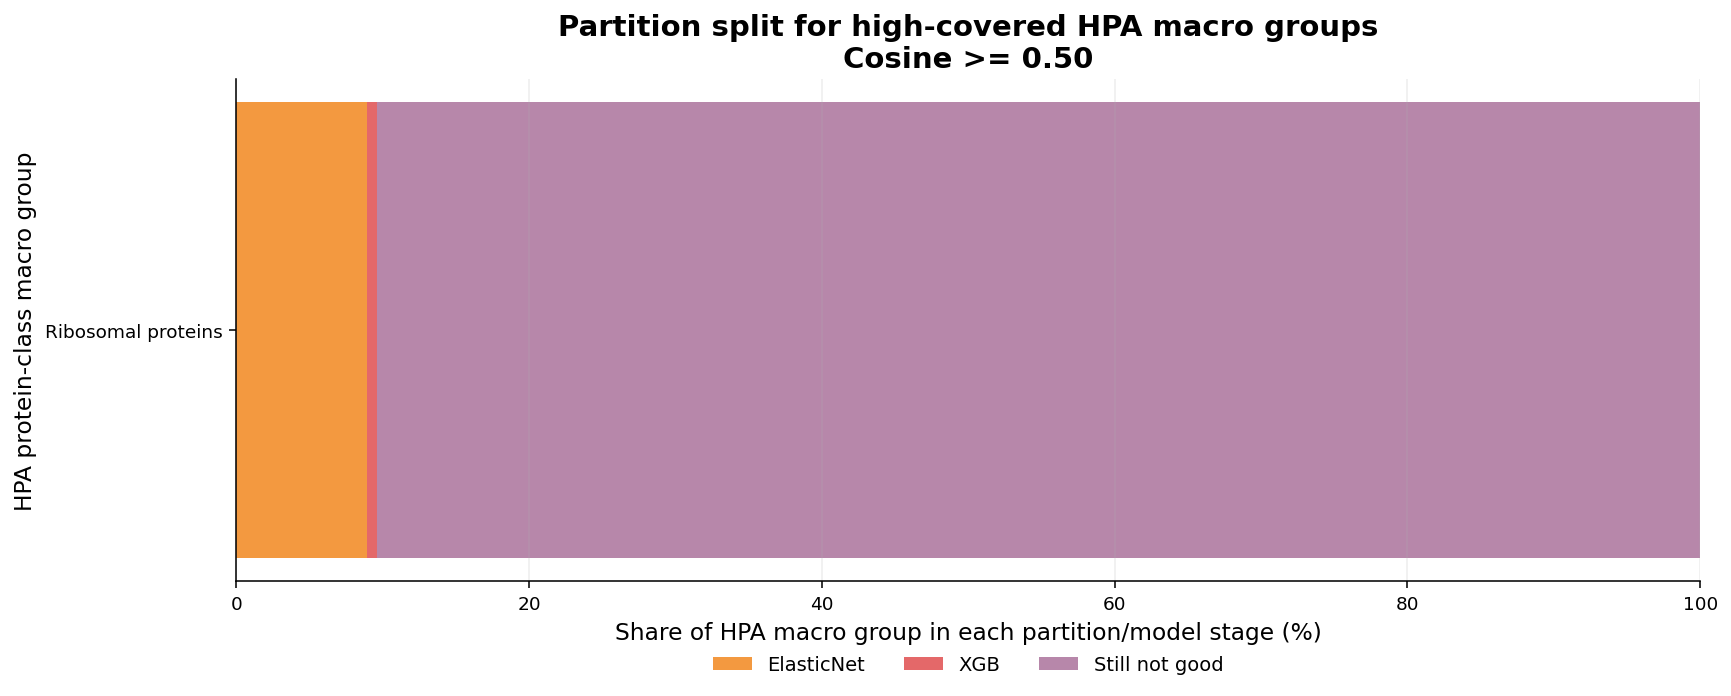

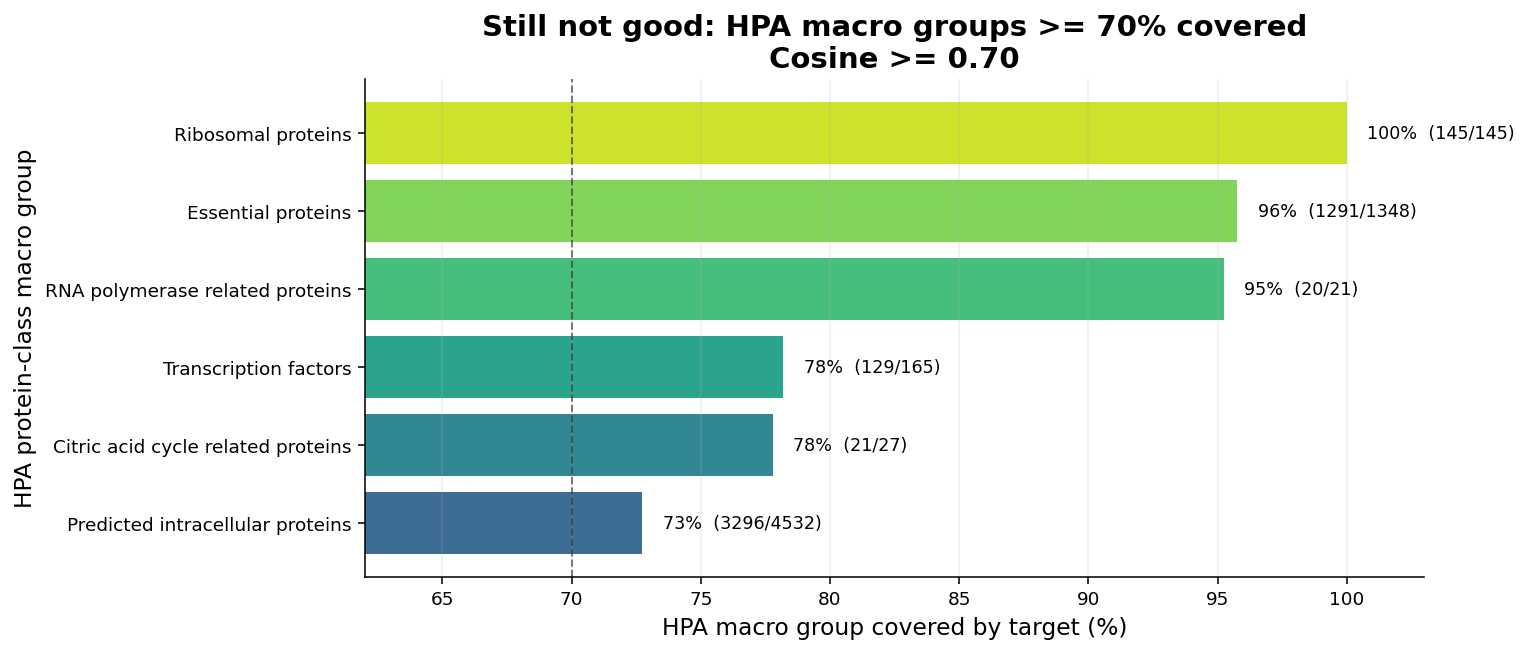

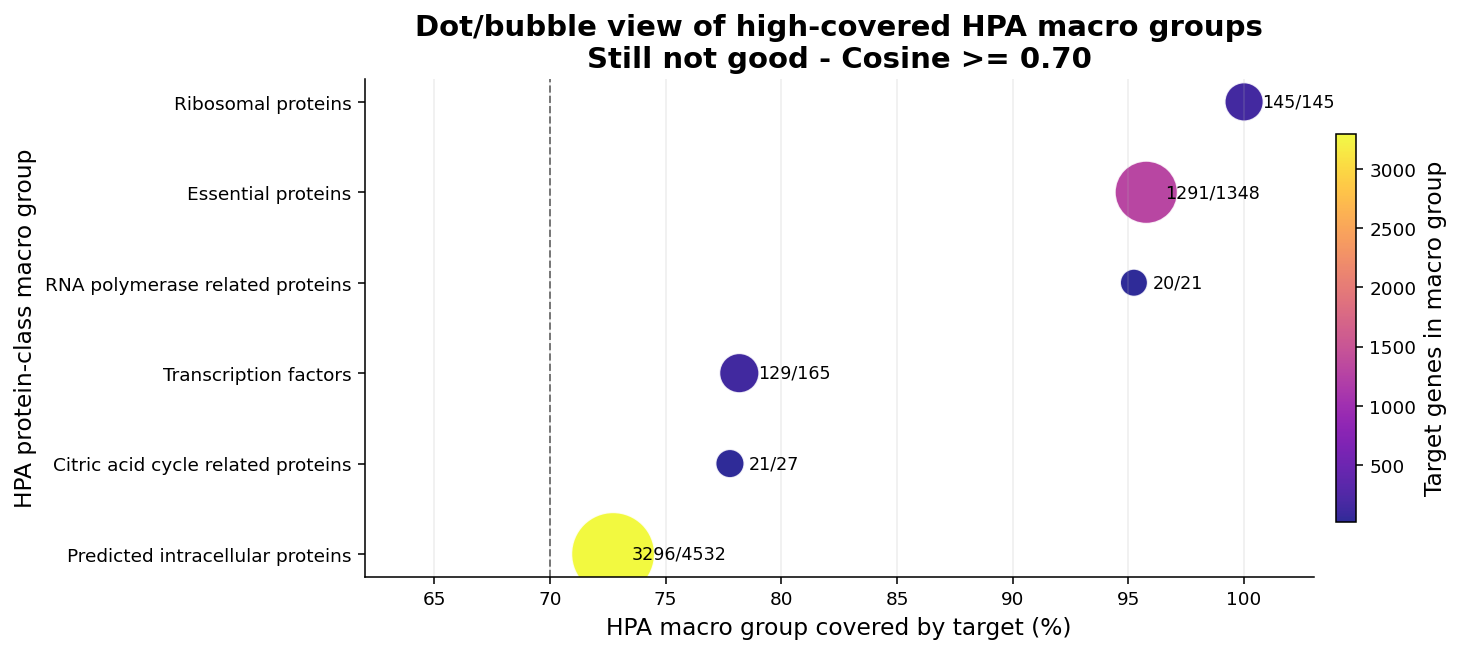

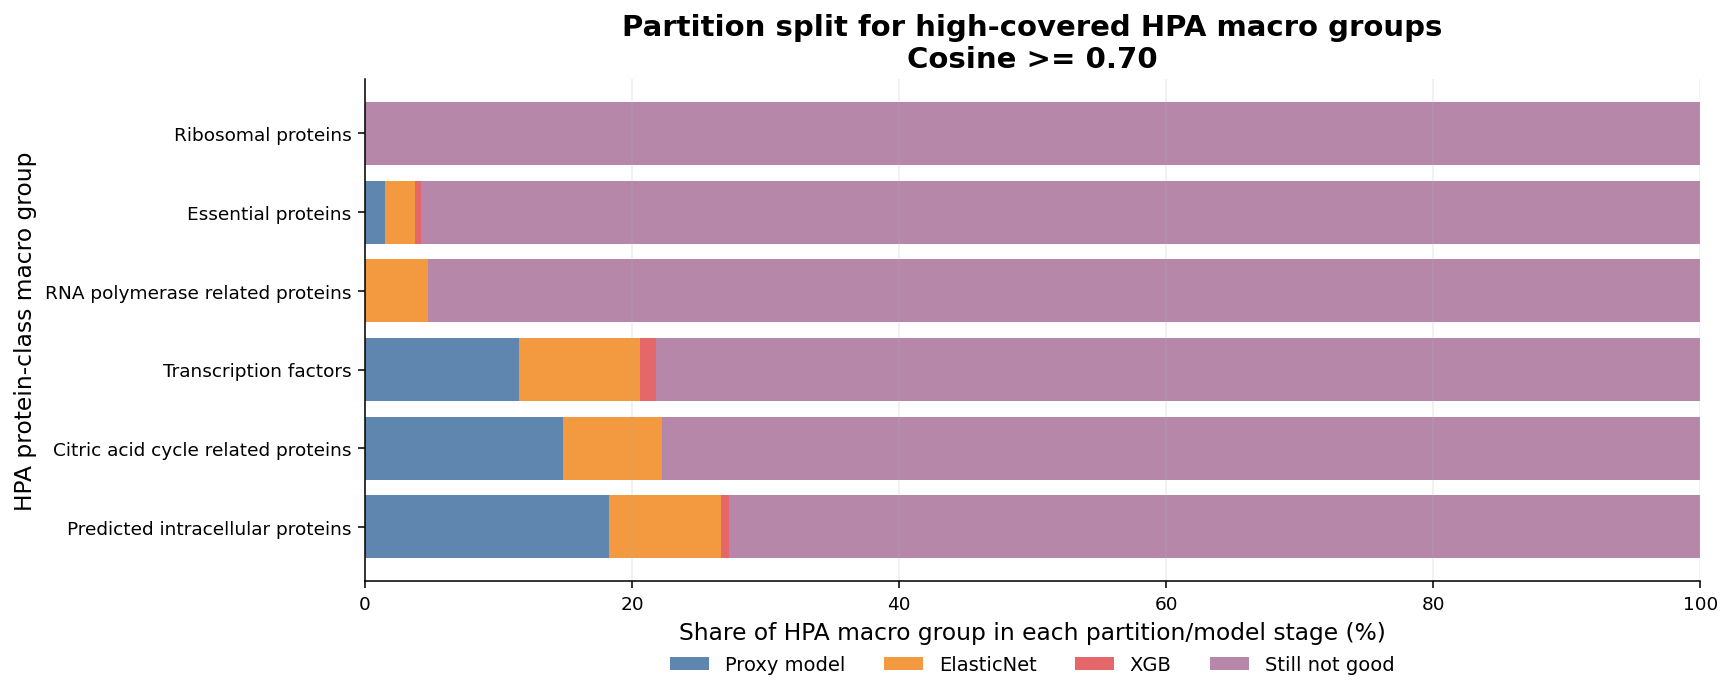

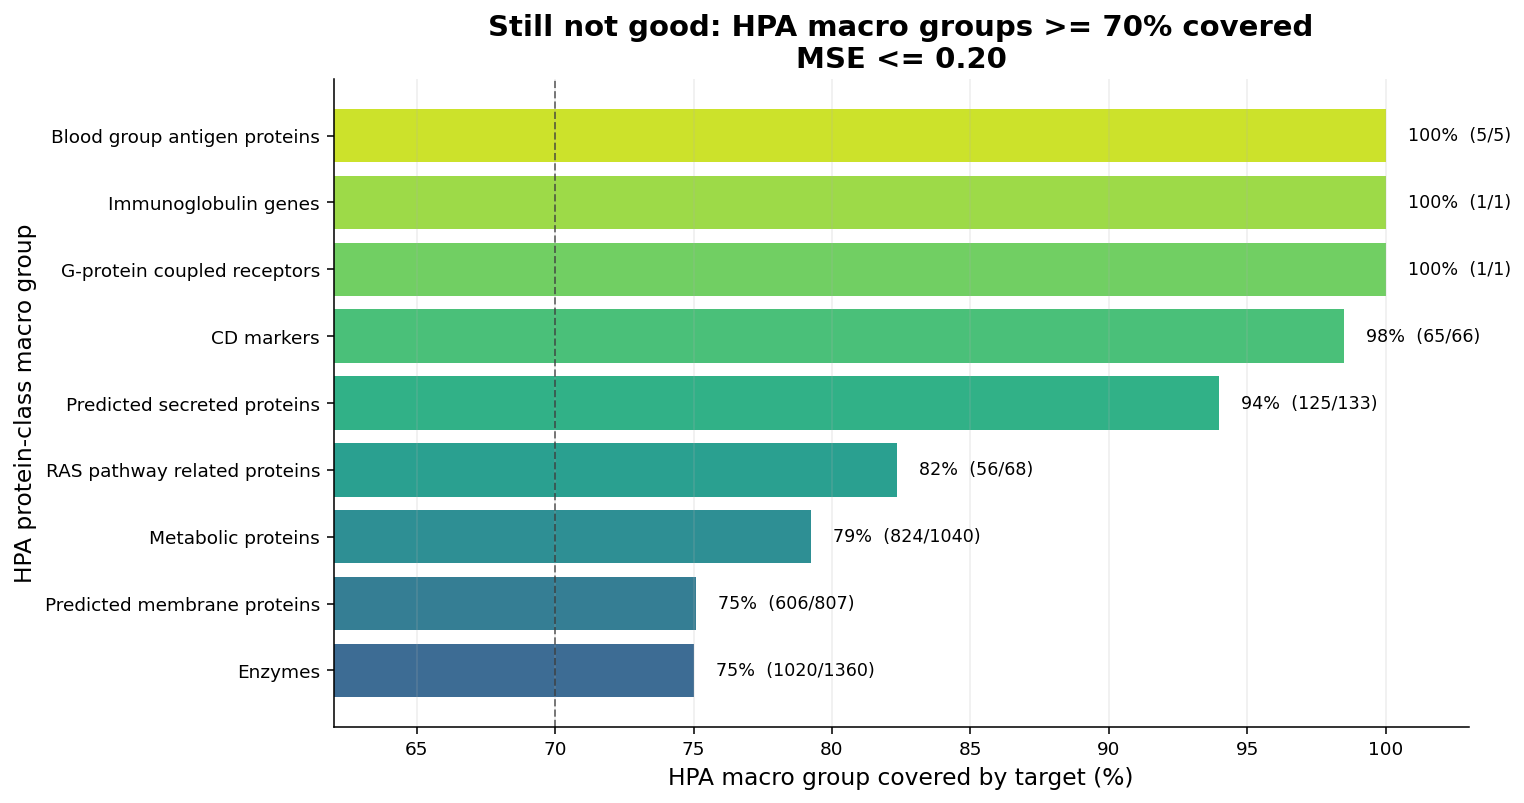

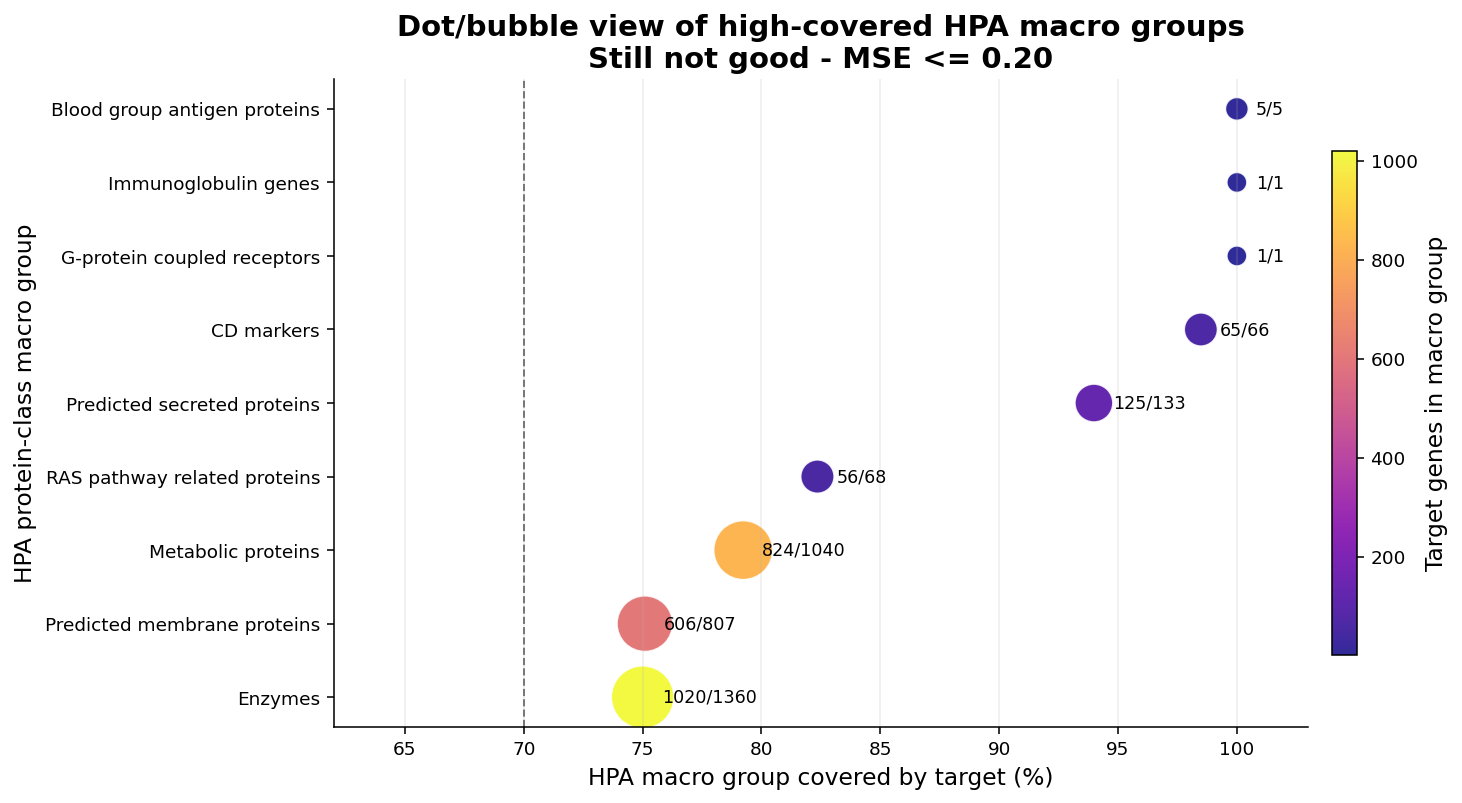

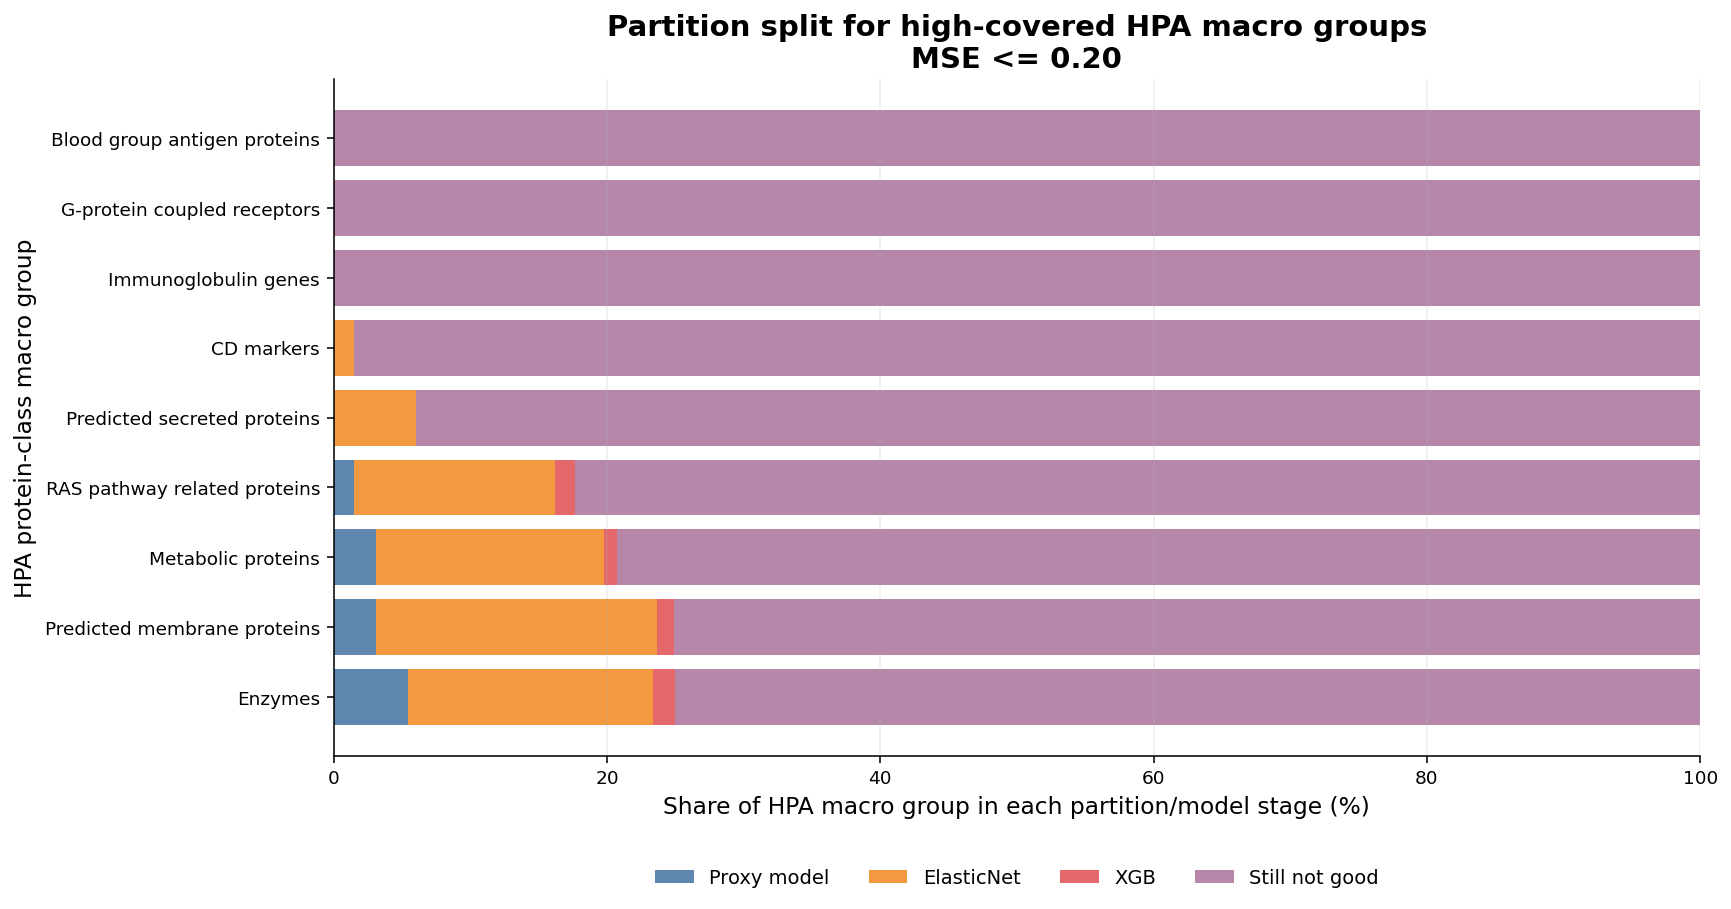

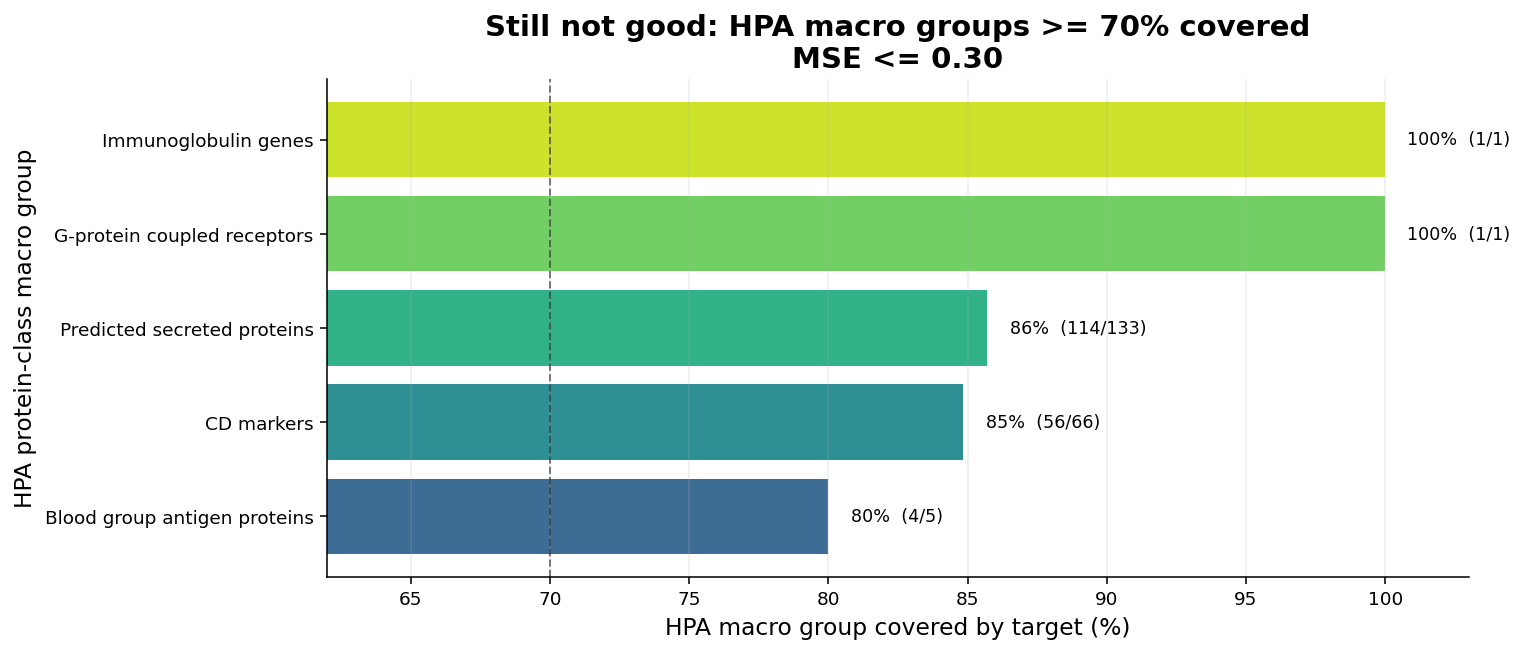

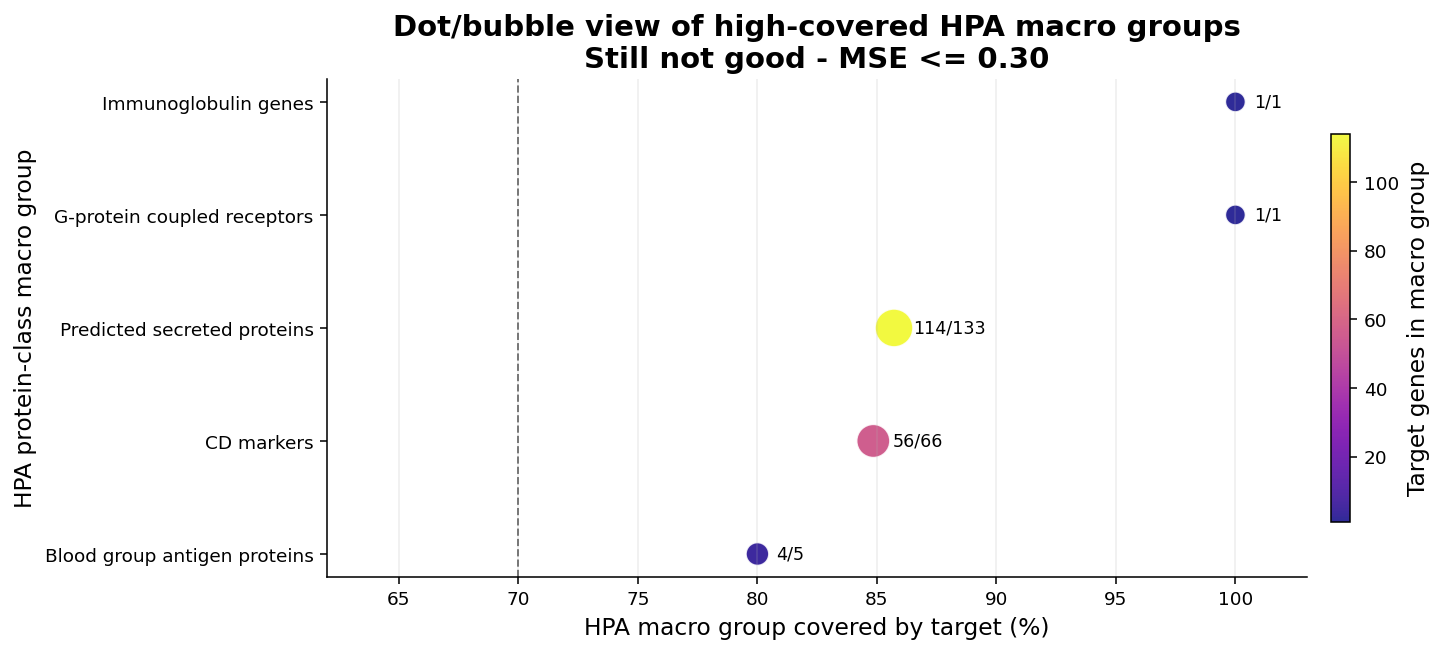

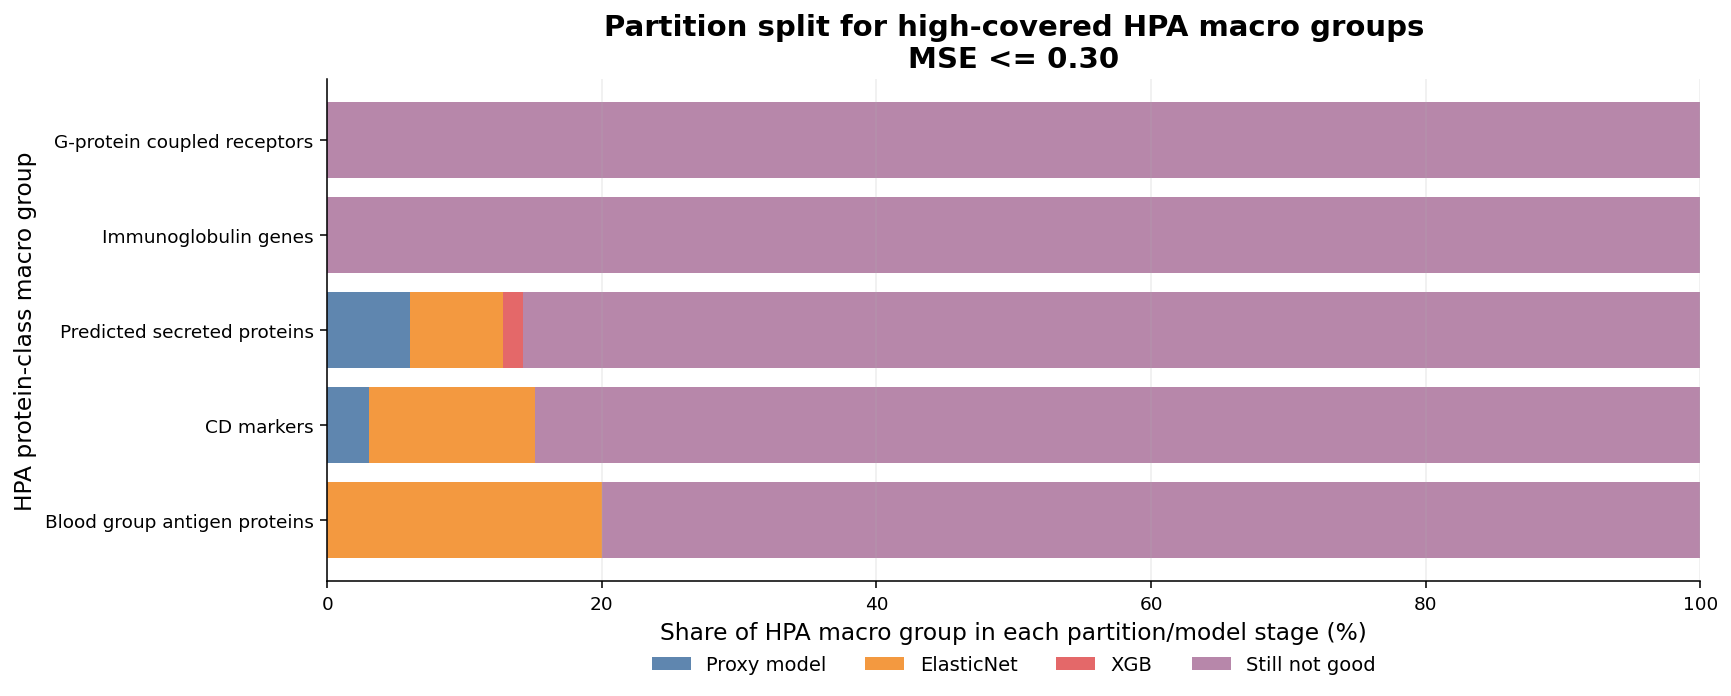


Figures saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_still_not_good_mse020_030_outputs\figures
High-coverage bar plots created: 6
High-coverage dot/bubble plots created: 6
High-coverage partition-split plots created: 6
Tables saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_still_not_good_mse020_030_outputs\tables


## Model-good union: Proxy + ElasticNet + XGB

Stage groups used as numerator: ['Proxy model', 'ElasticNet', 'XGB']

Compact HPA macro-class coverage summary
source_id dataset metric_family threshold_name  macro_classes_with_denominator  target_gene_macro_memberships  median_pct_macro_captured  max_pct_macro_captured  macro_classes_ge_70pct
  proxy_z    CCLE        Cosine        >= 0.50                              18                           8788                      80.66                  100.00                      14
  proxy_z    CCLE        Cosine        >= 0.70                              18                           3533                      35.50                  100.00                       4
  proxy_z    CCLE           MSE        <= 0.20                              18                           3949                      28.96                   57.93                       0
  proxy_z    CCLE           MSE        <= 0.30                              18                           7794                      60.37             

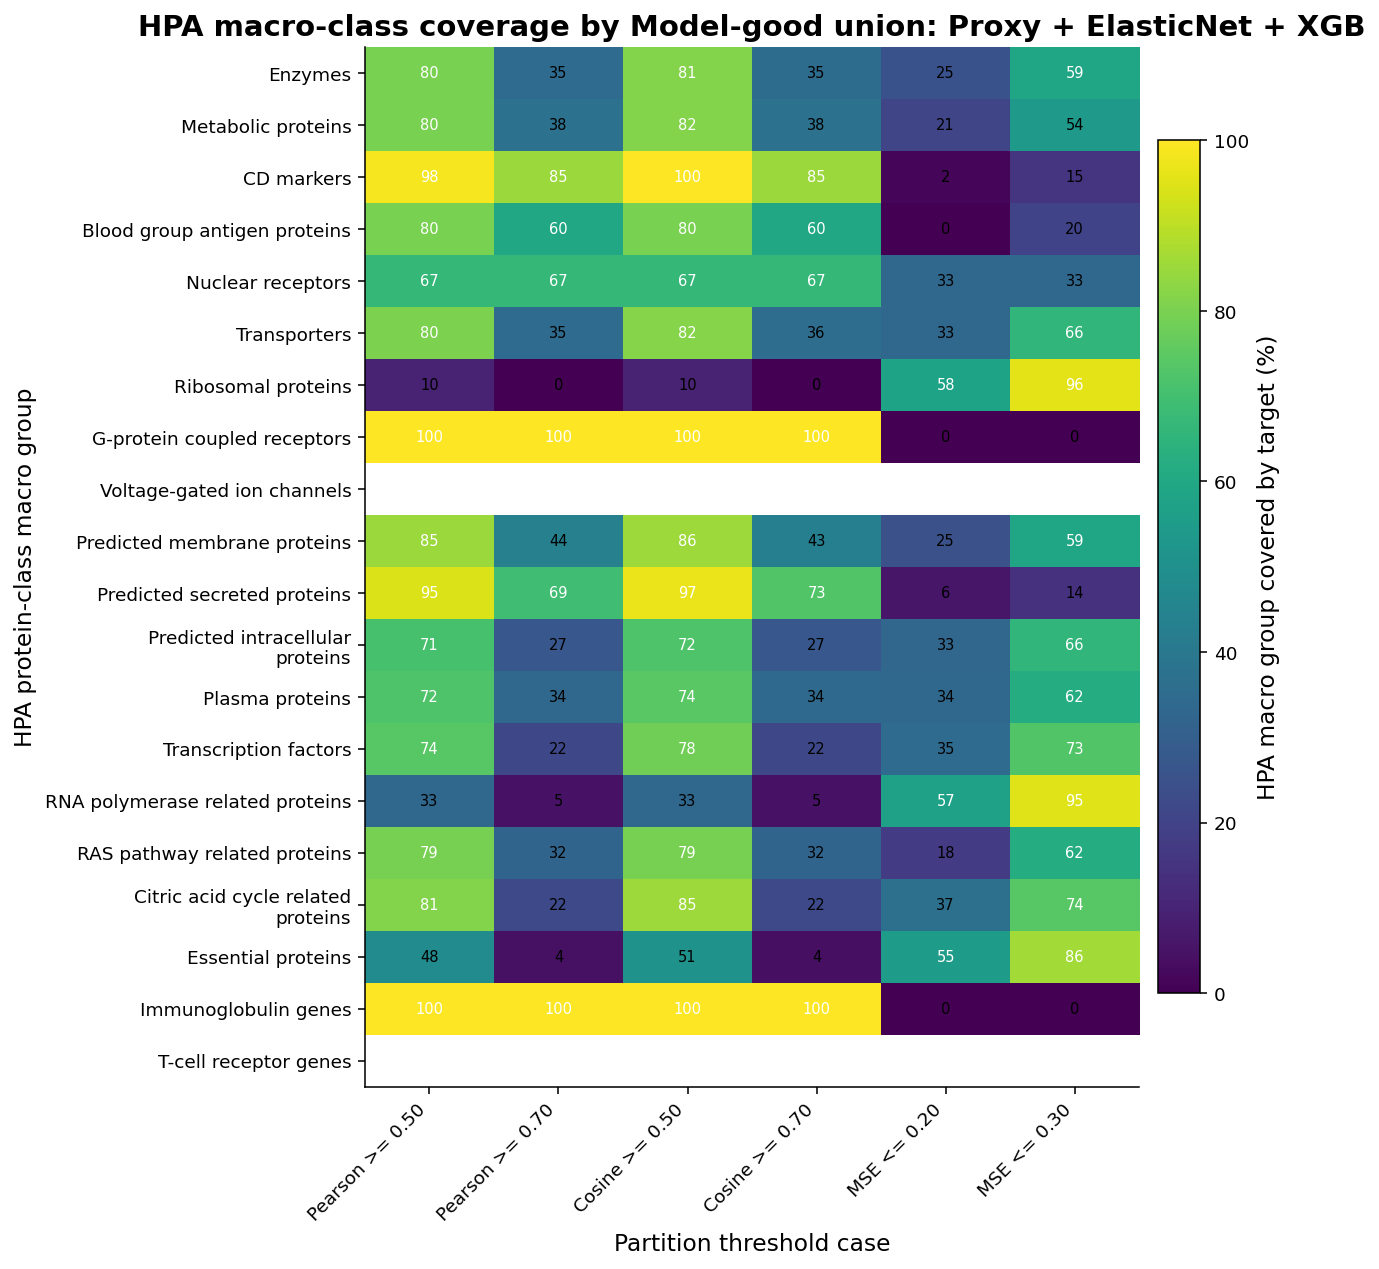

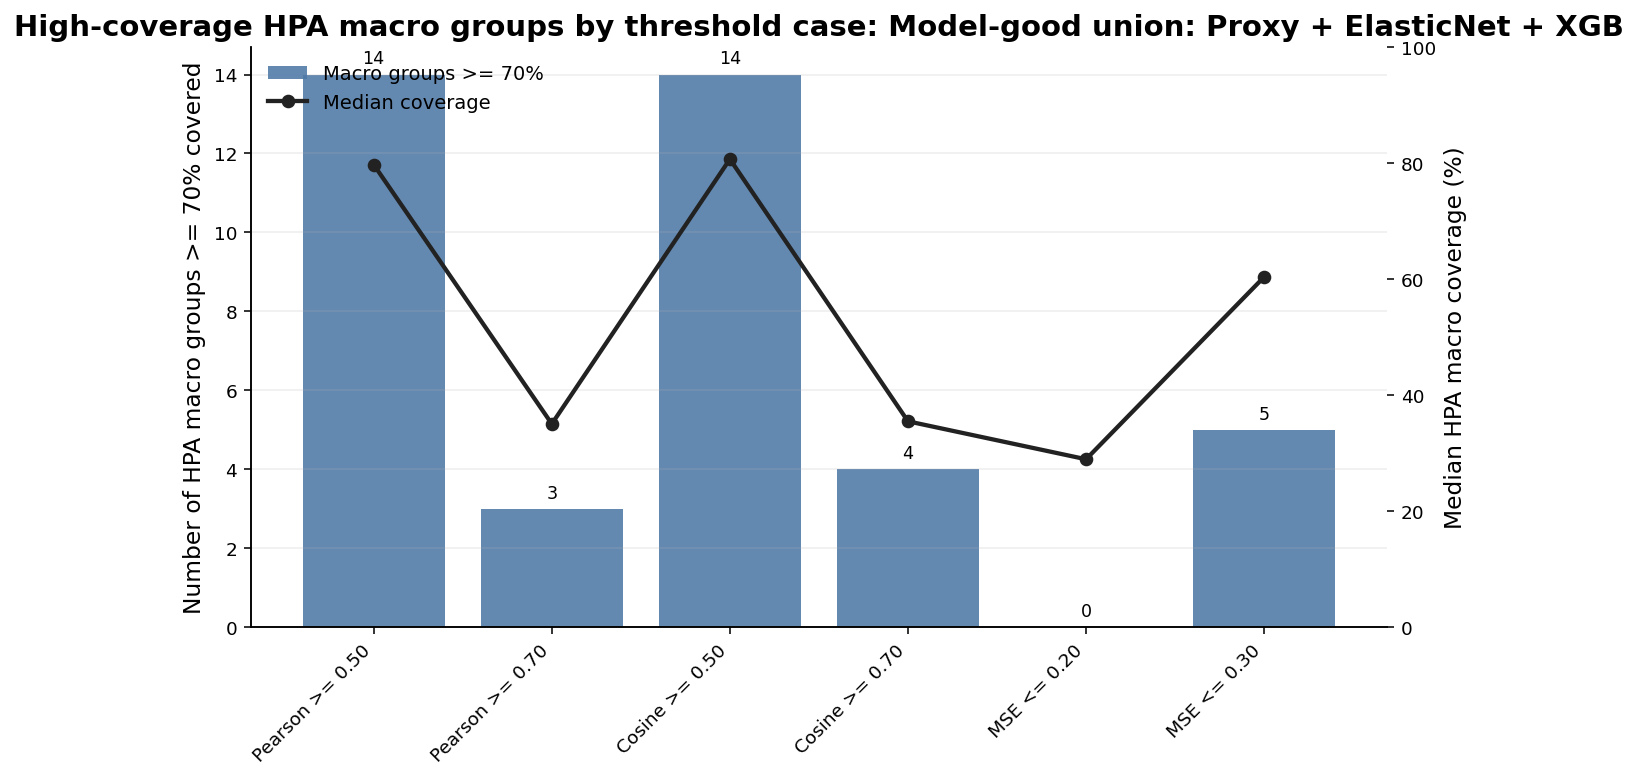

C:\Users\hp\AppData\Local\Temp\ipykernel_19564\3617896359.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap('magma').copy()


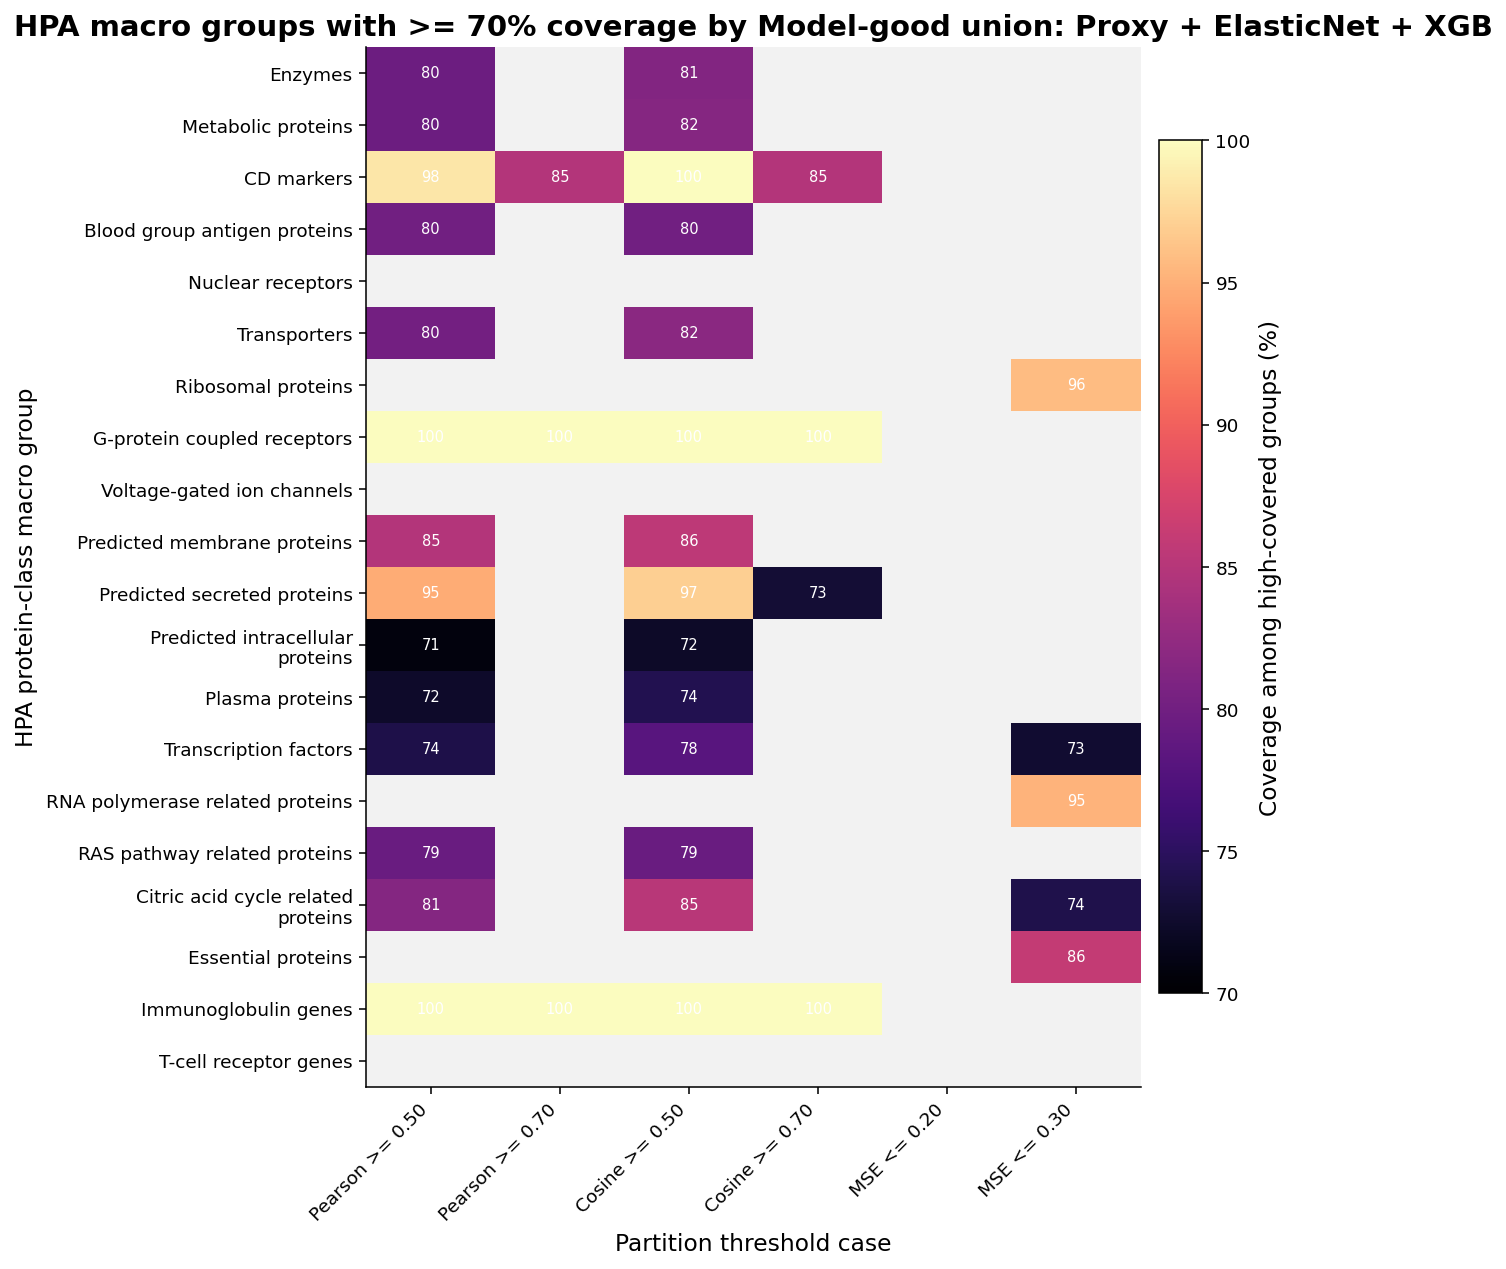

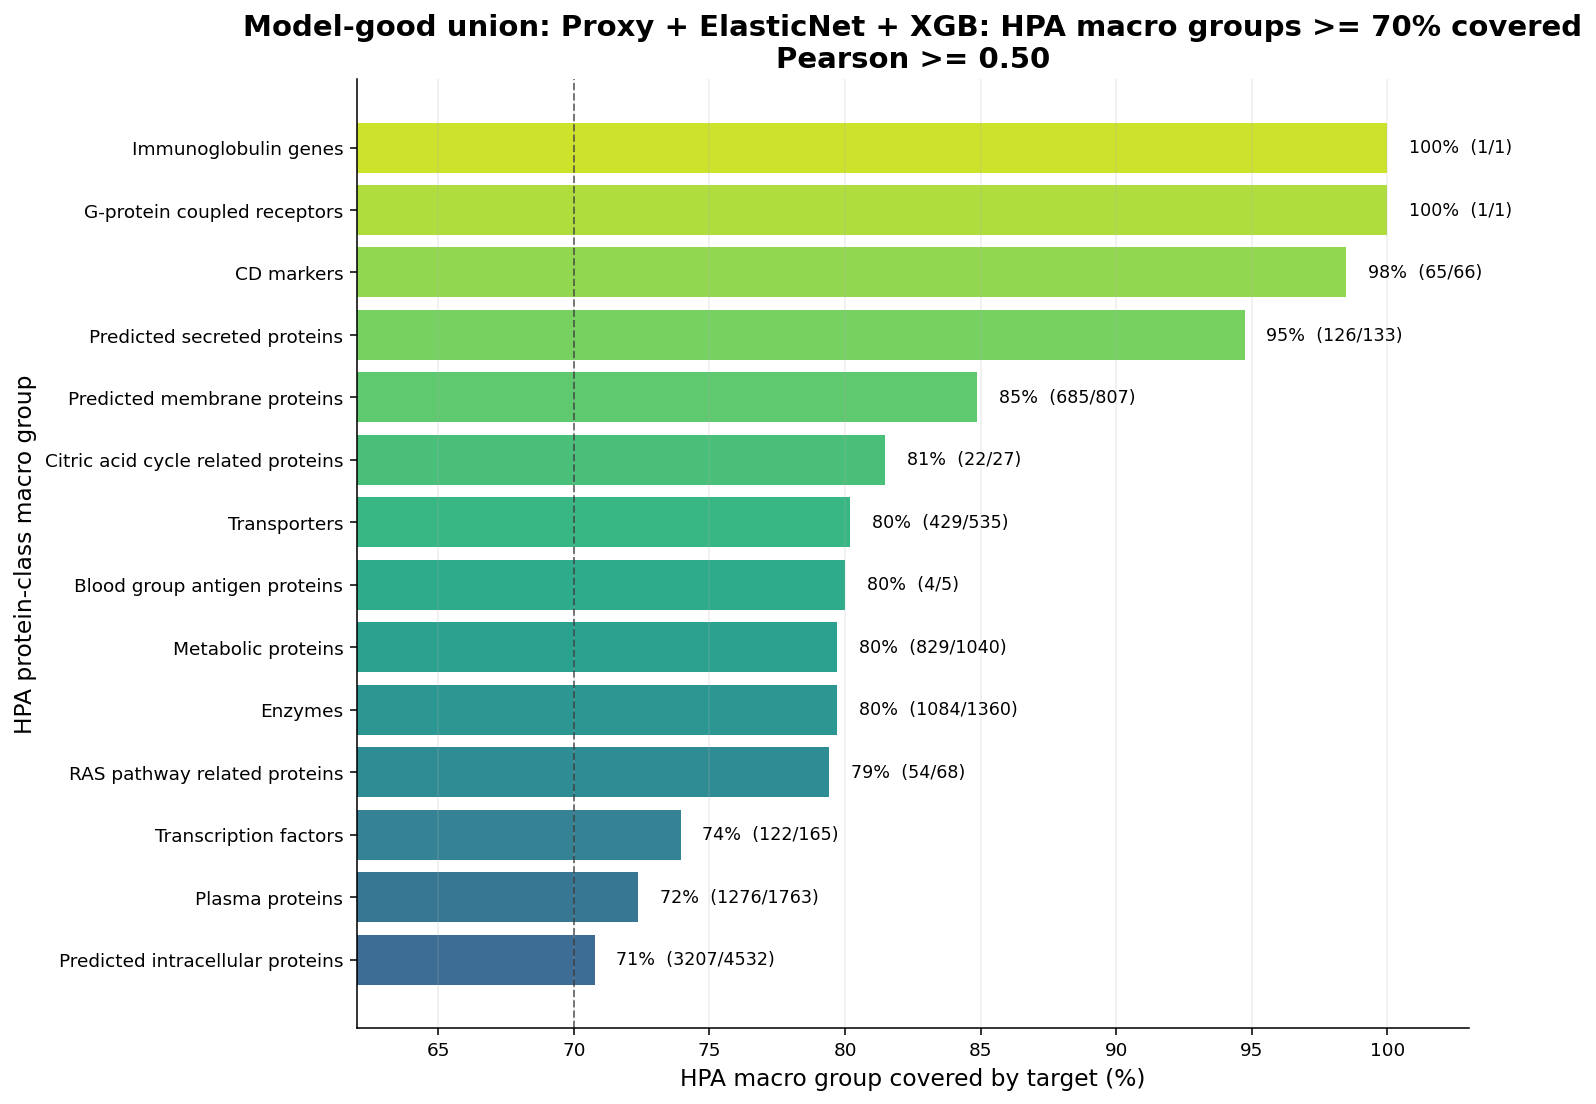

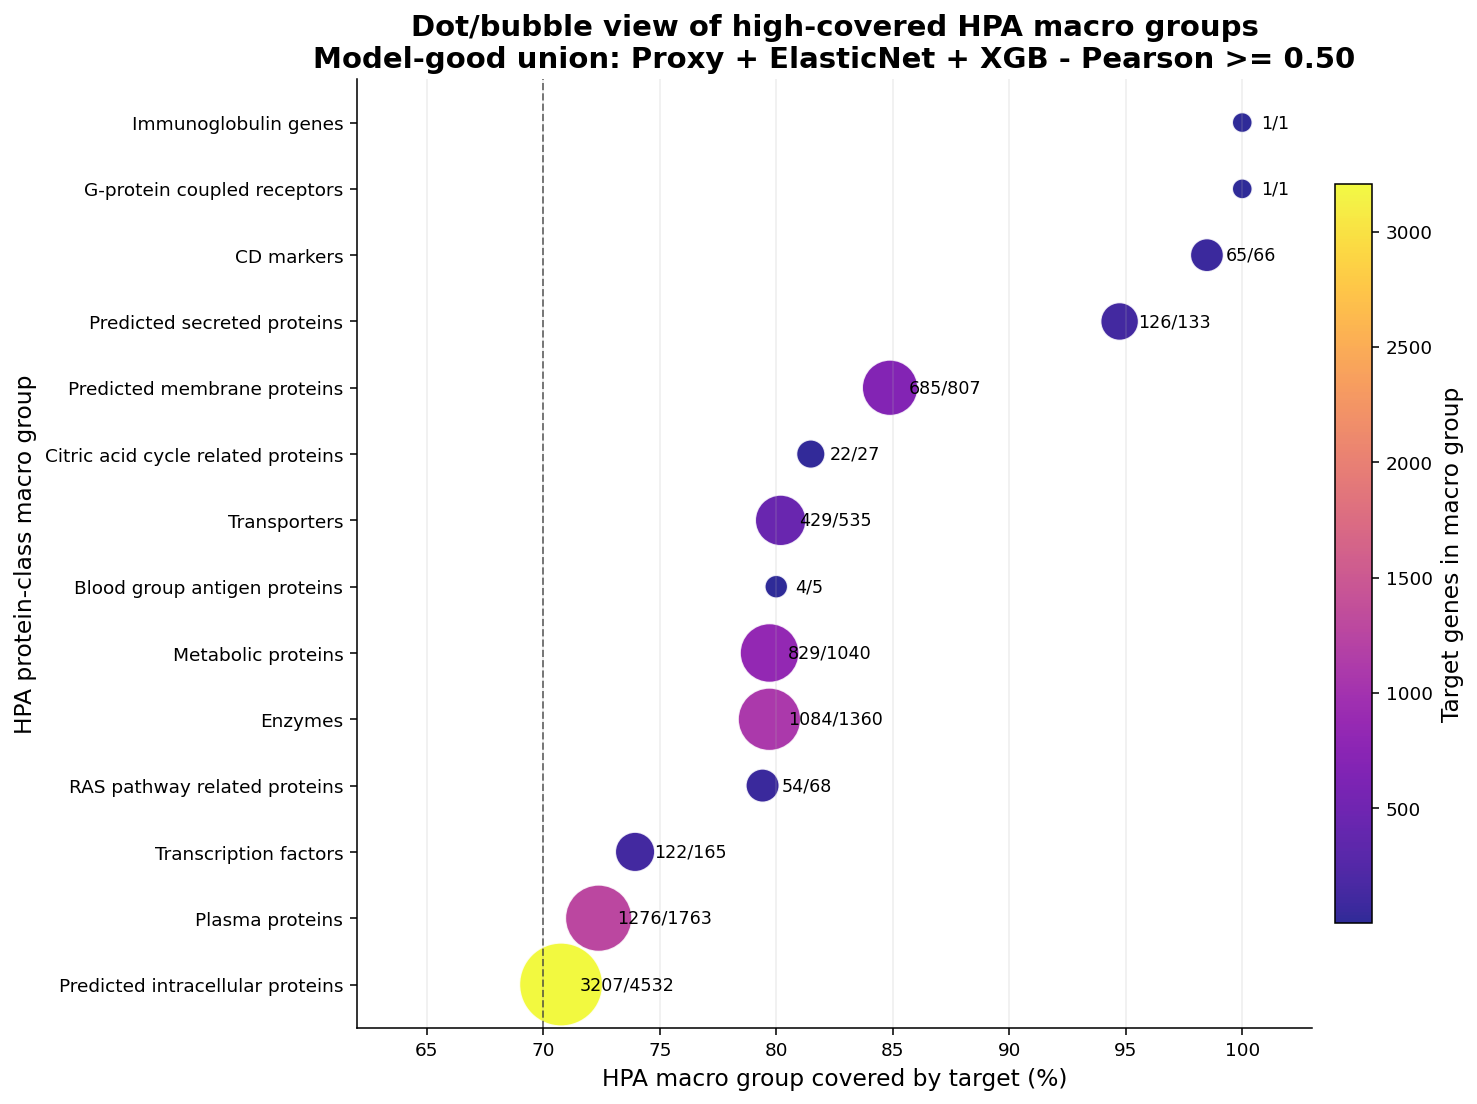

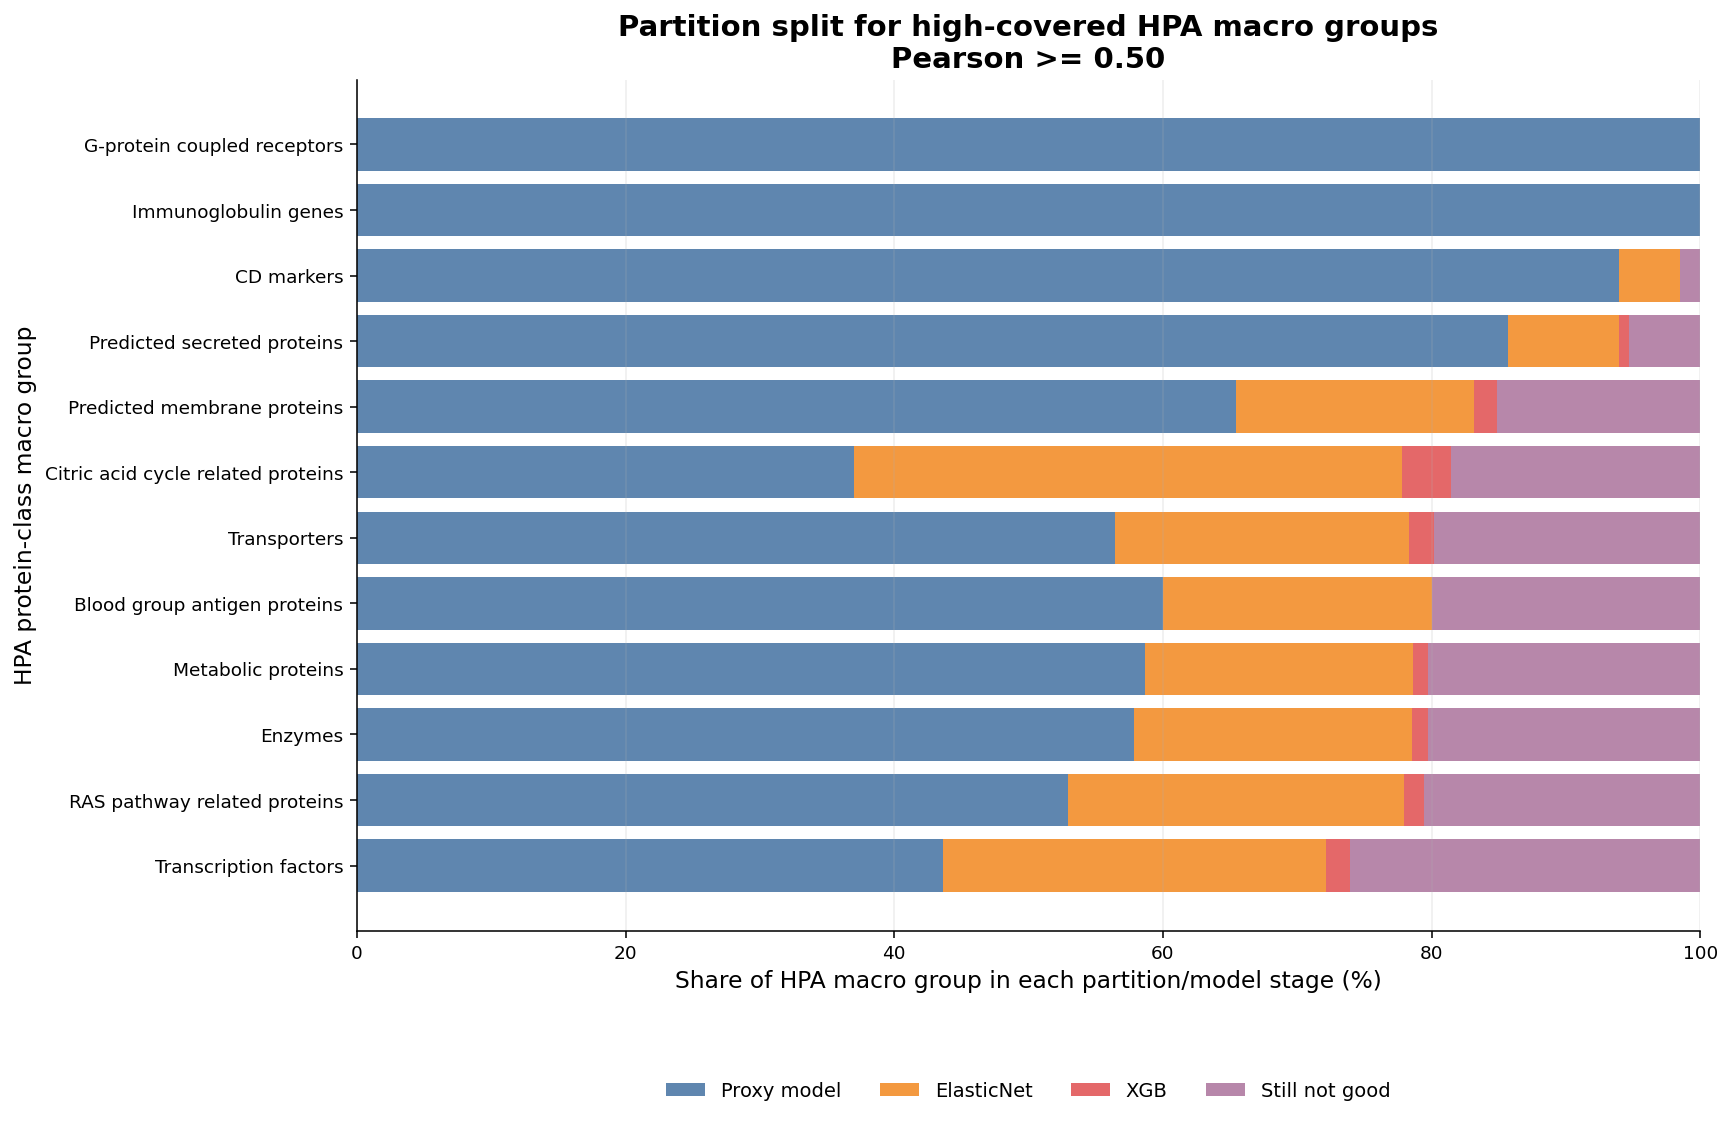

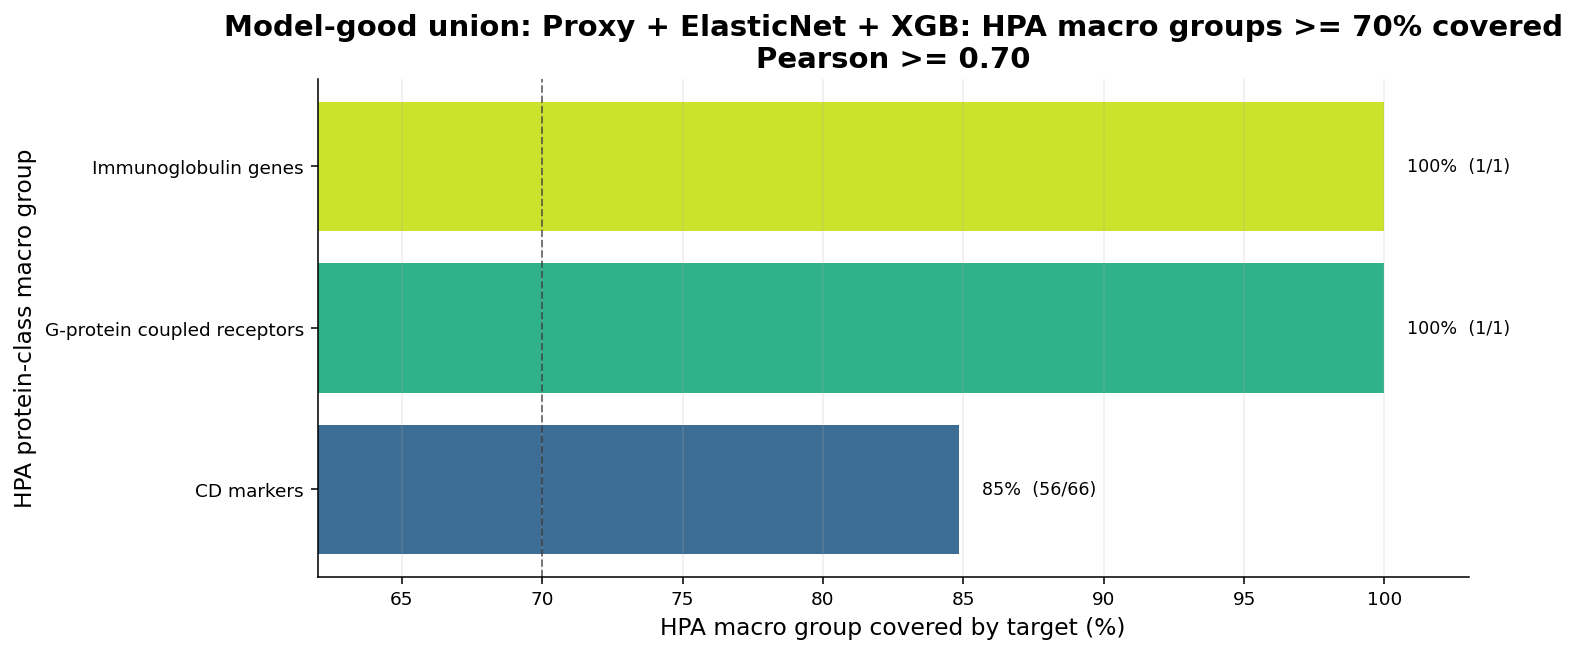

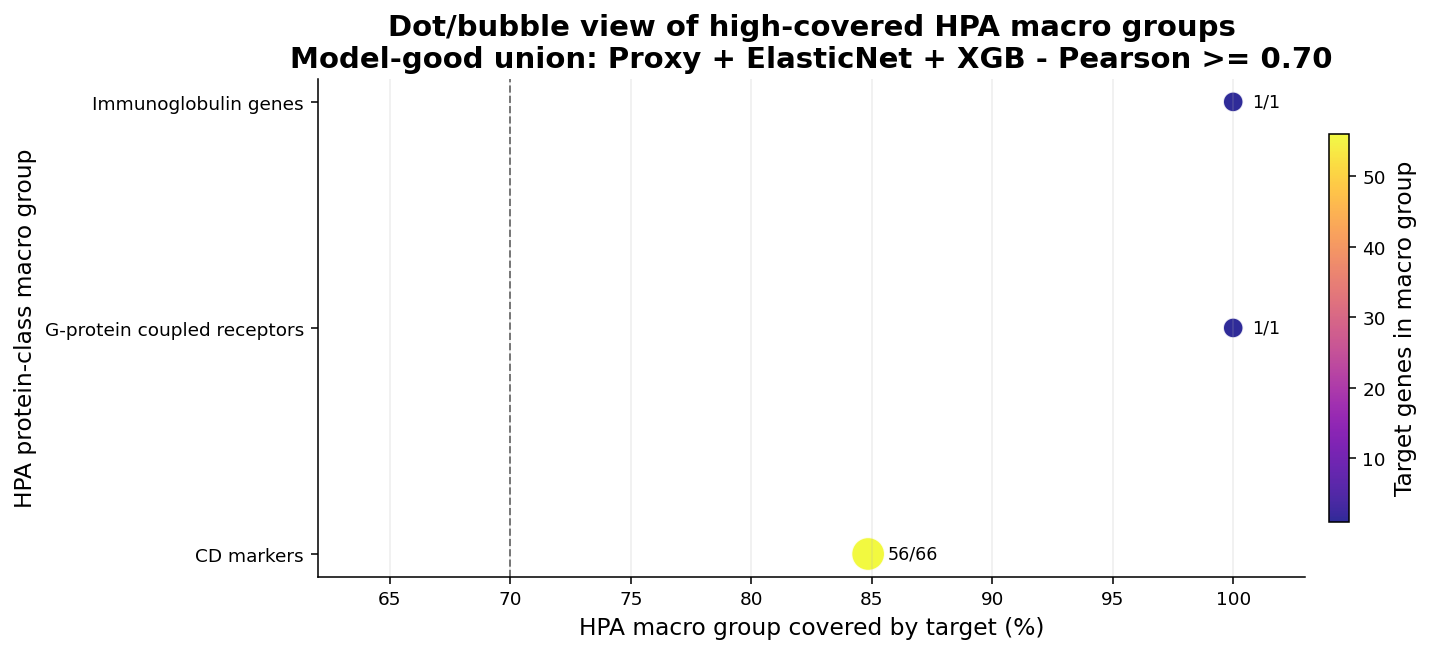

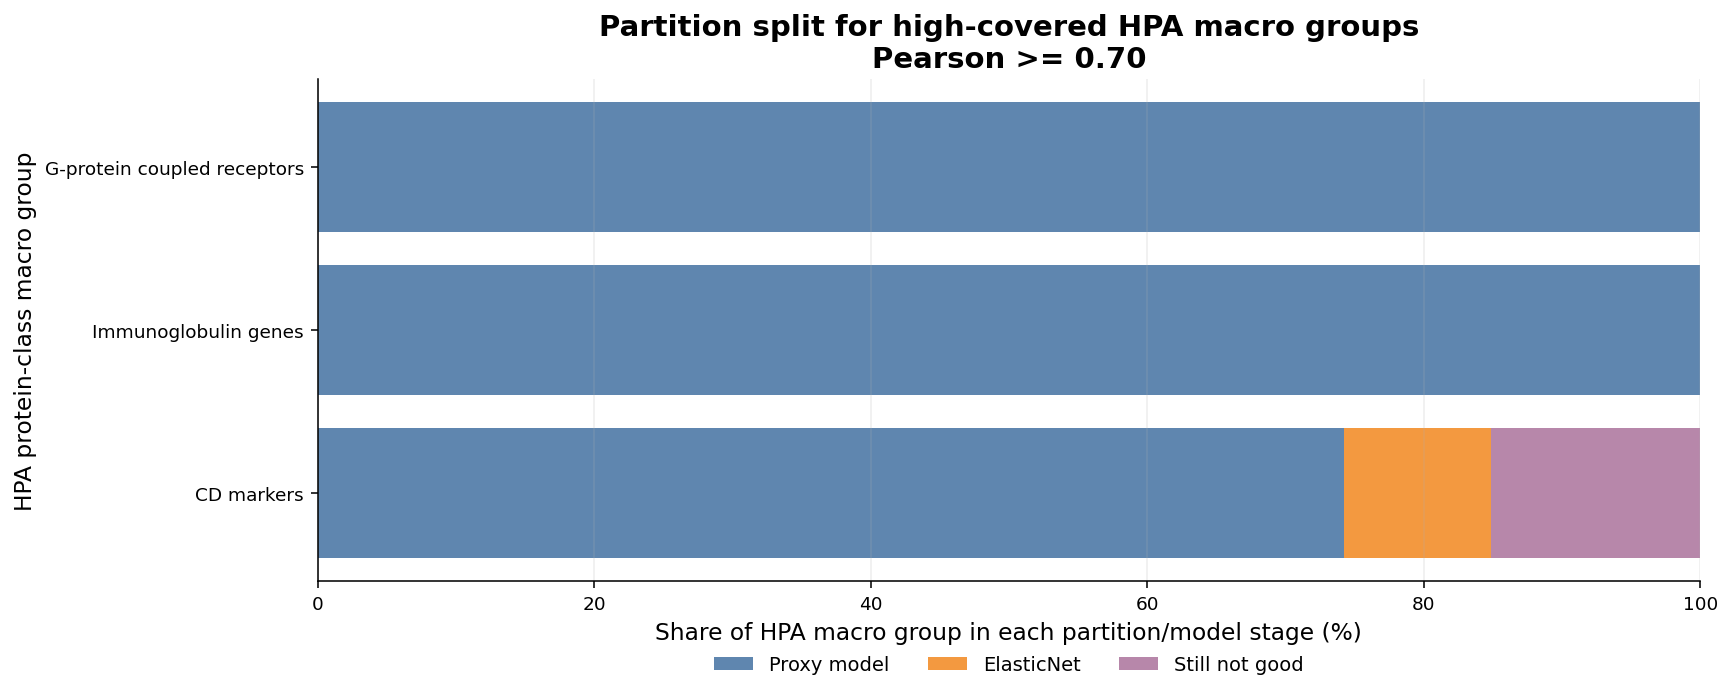

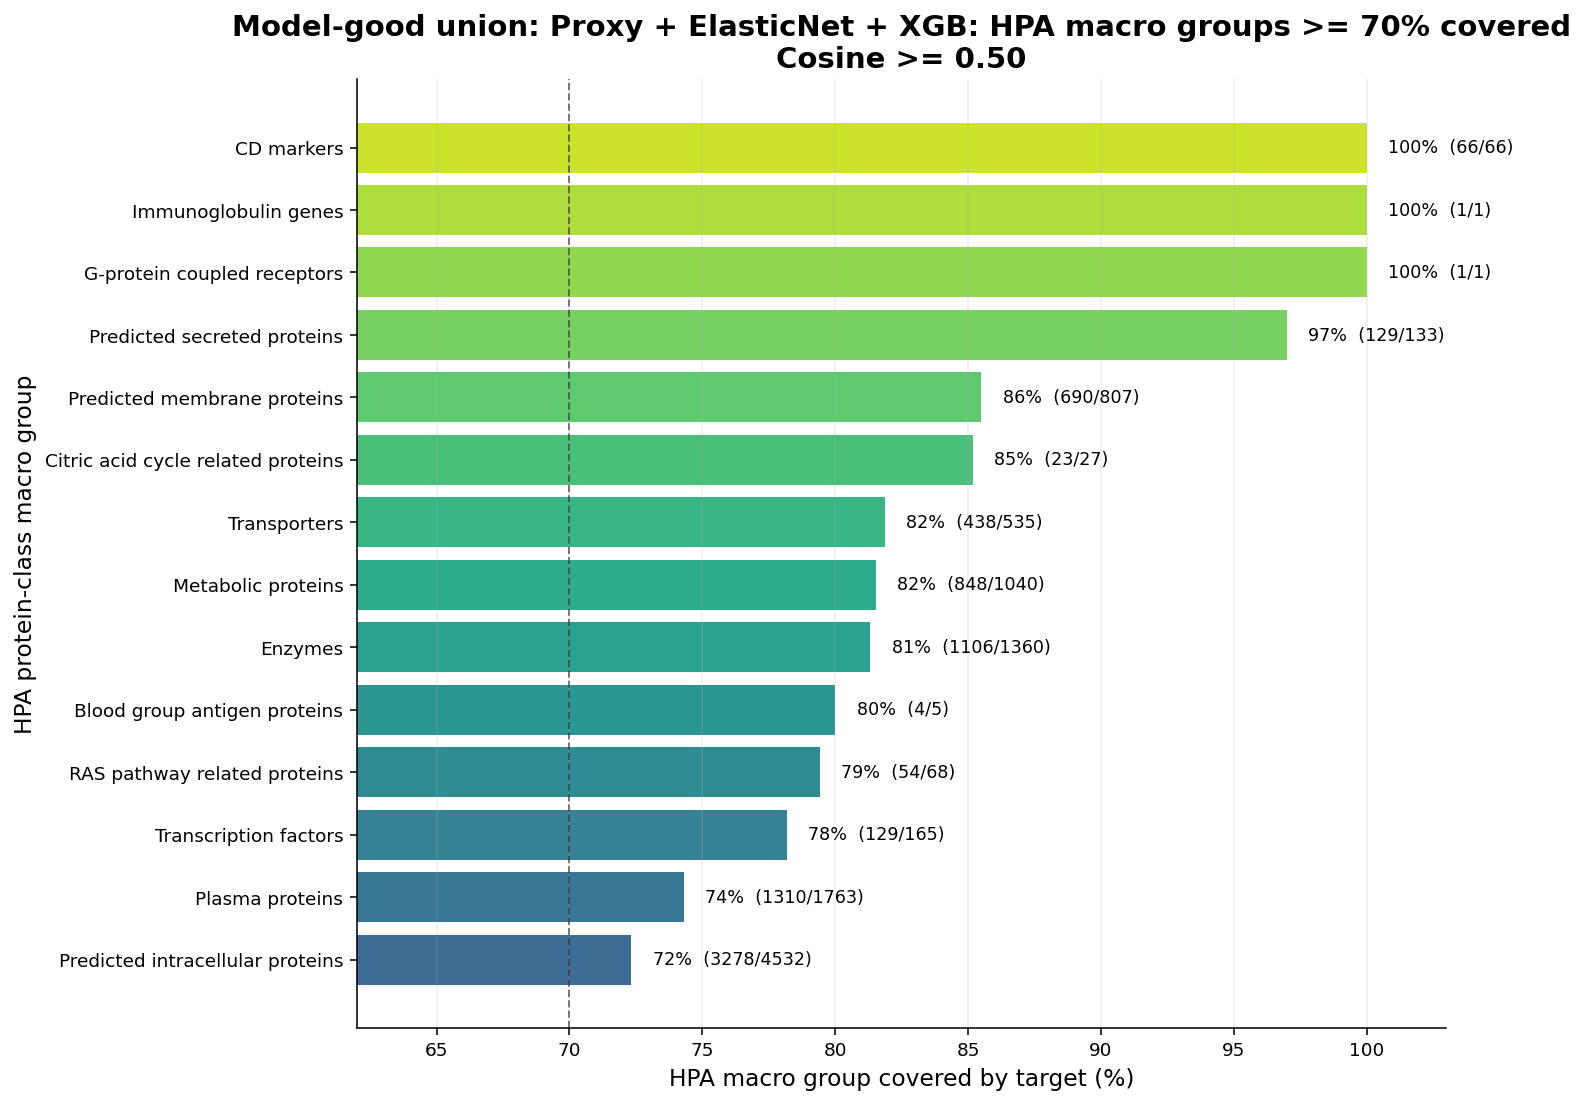

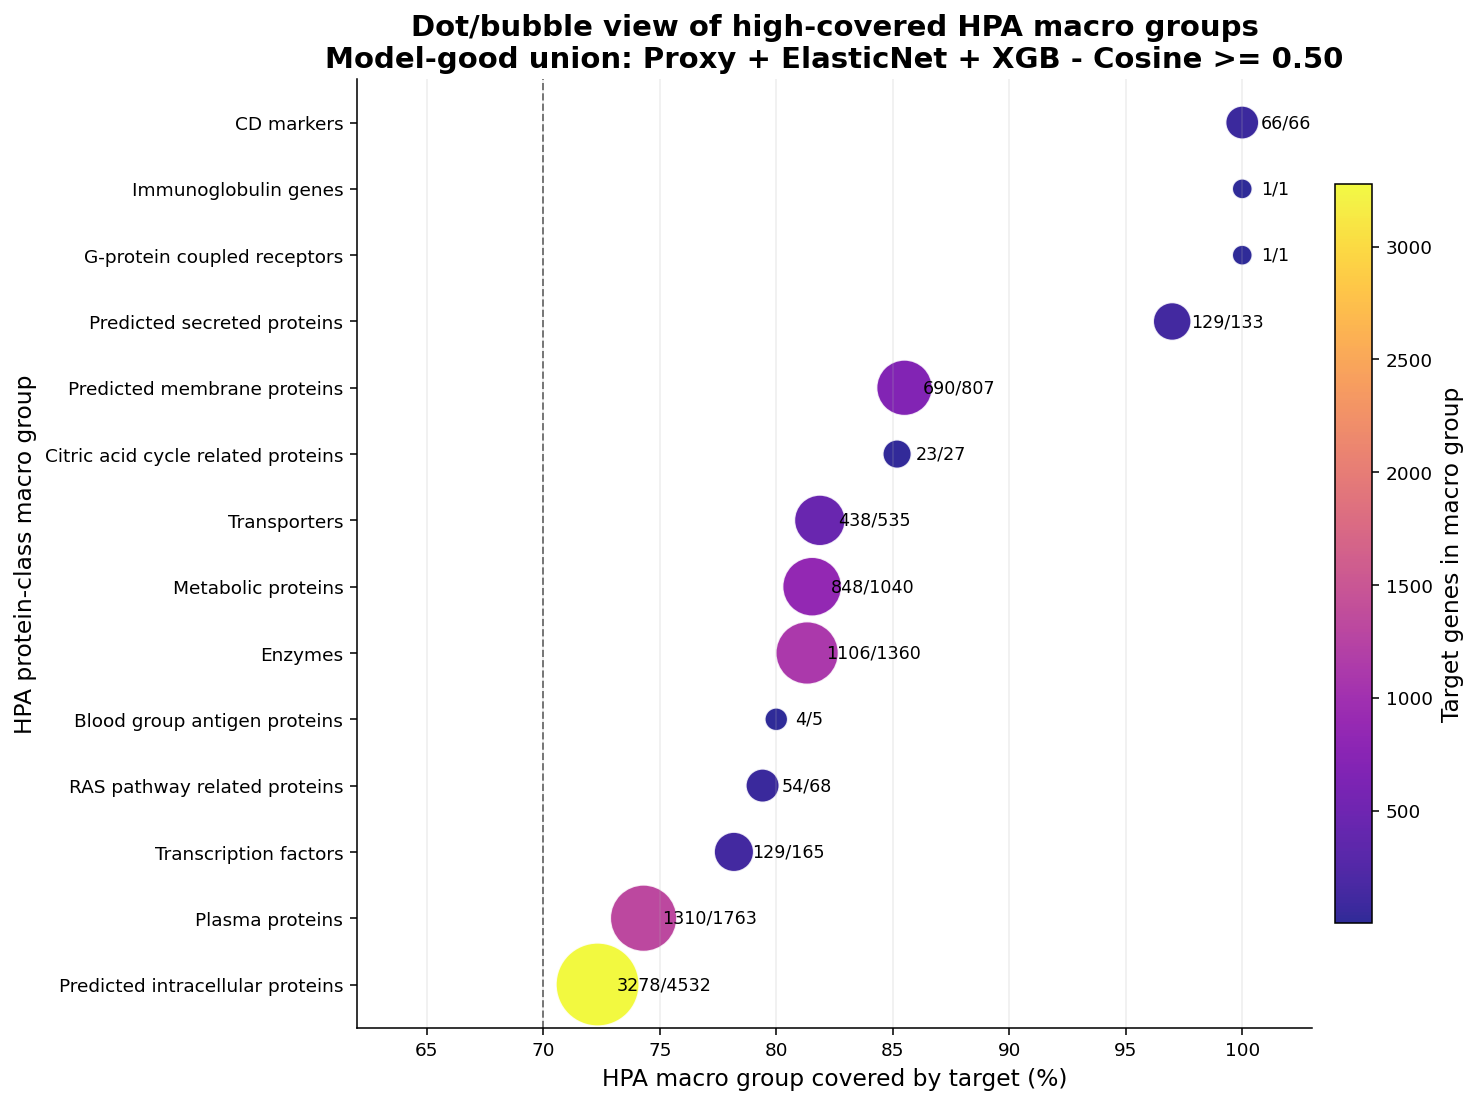

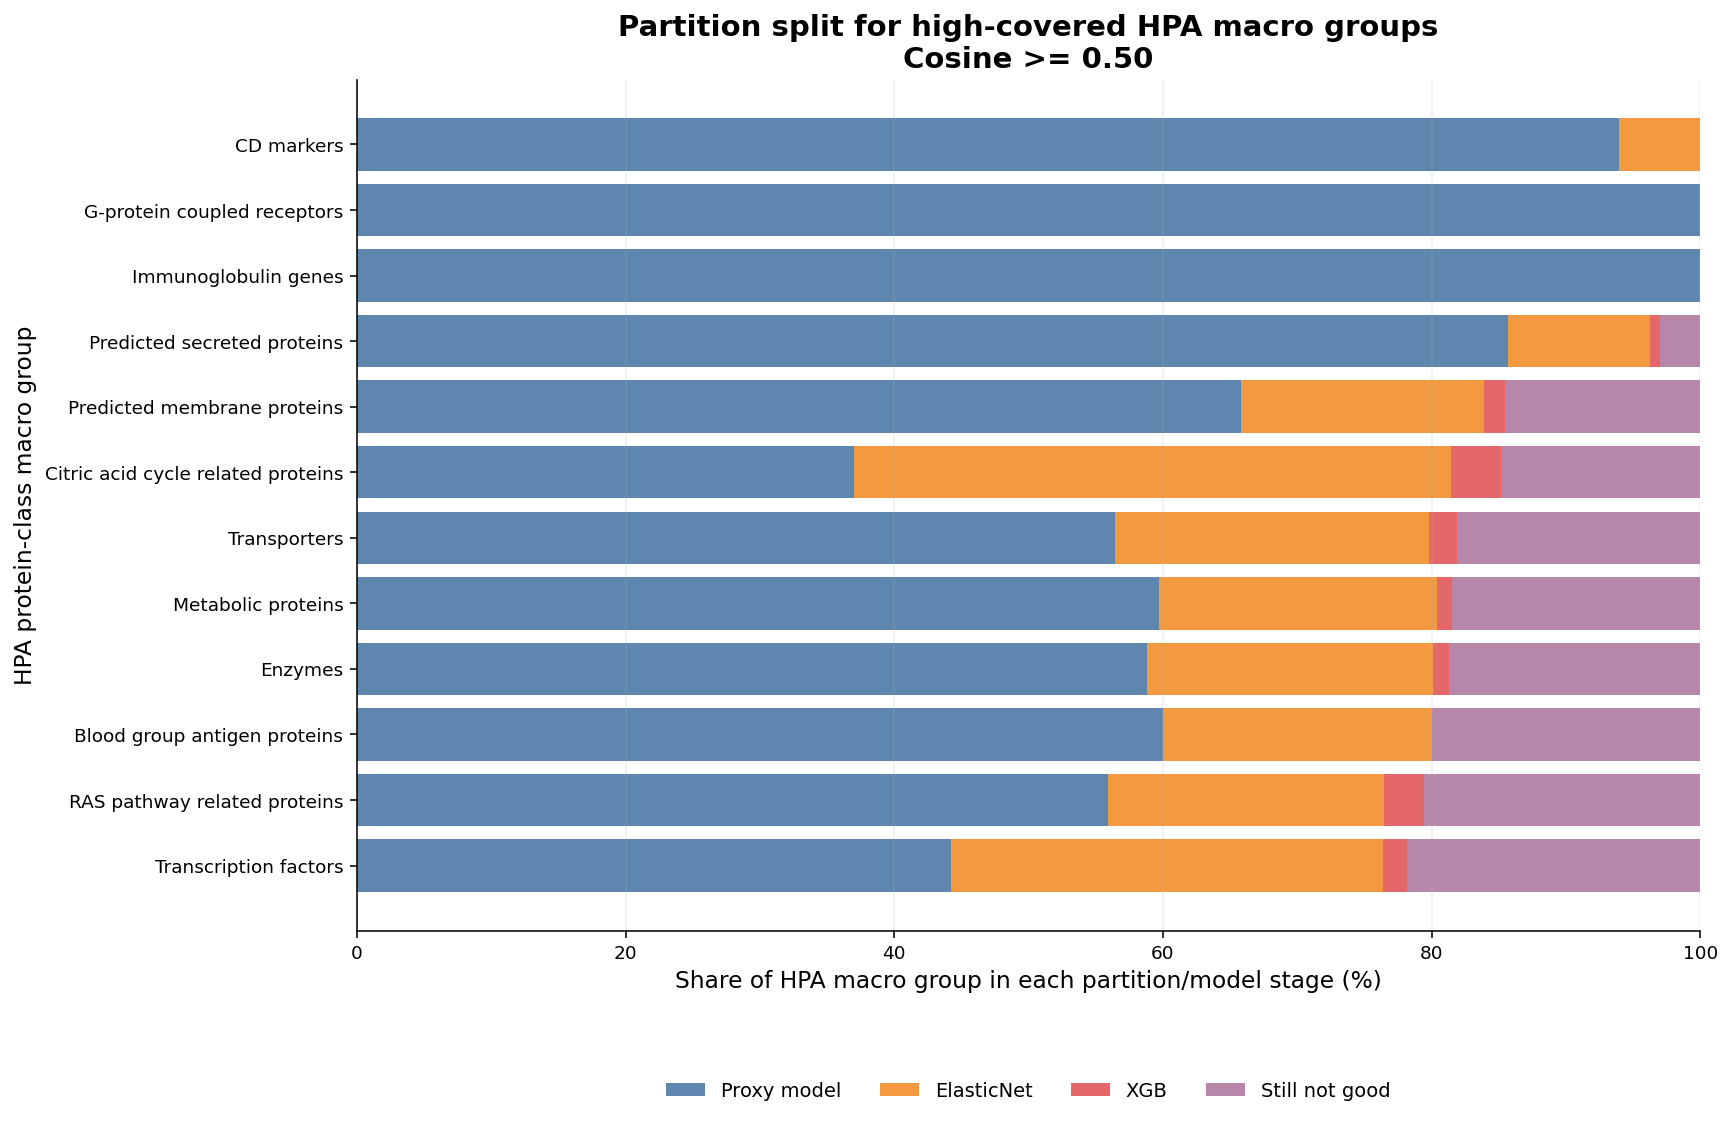

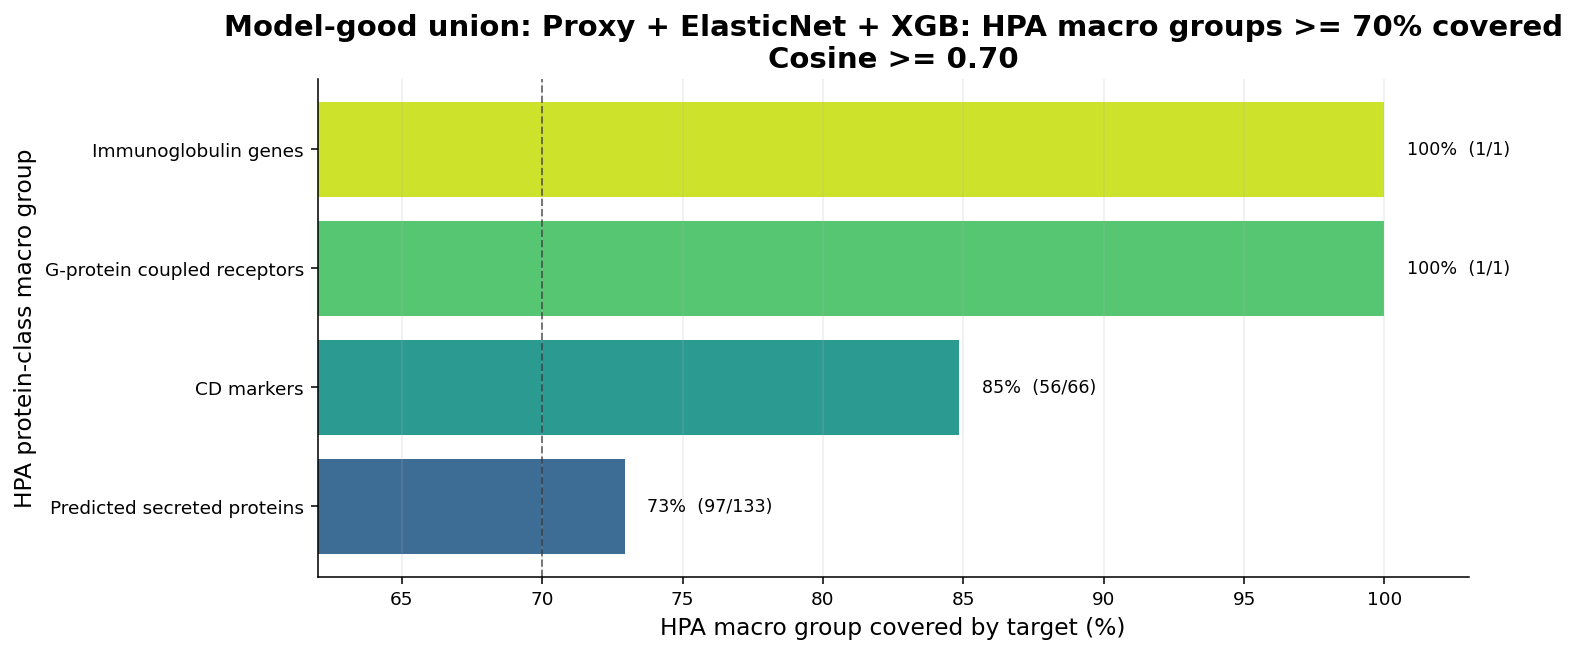

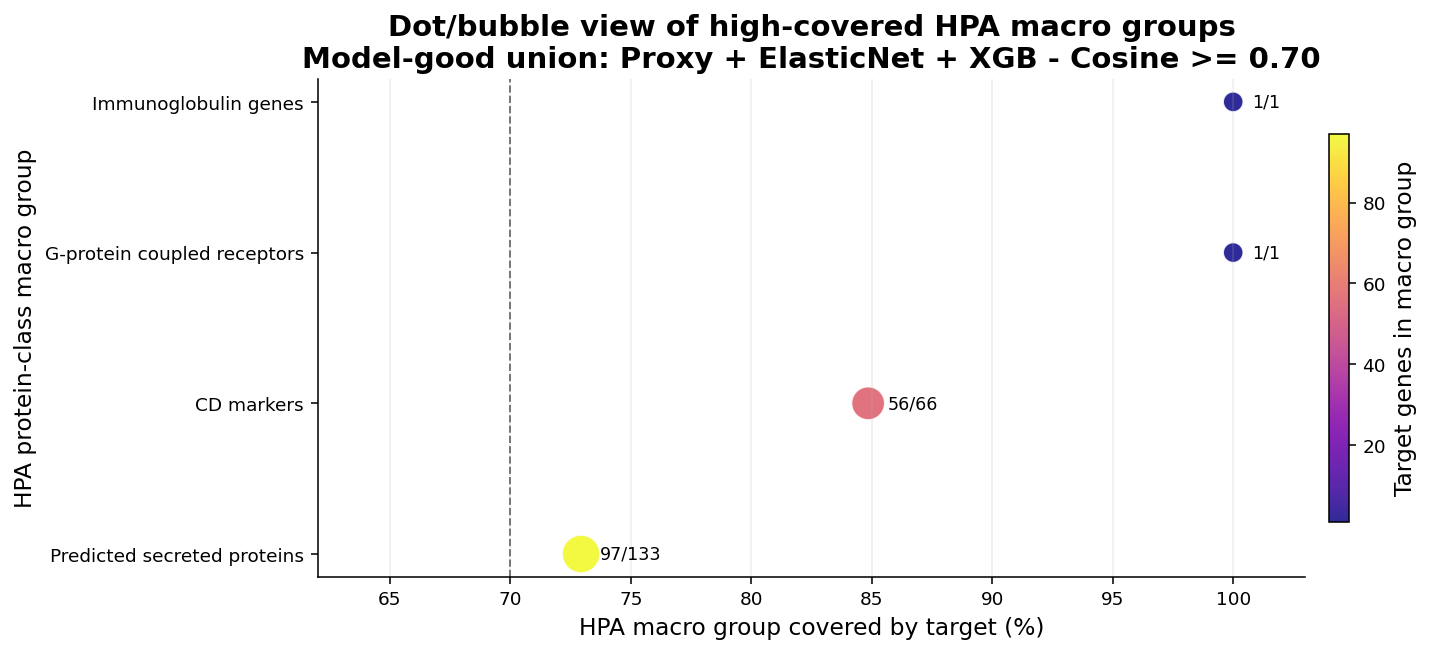

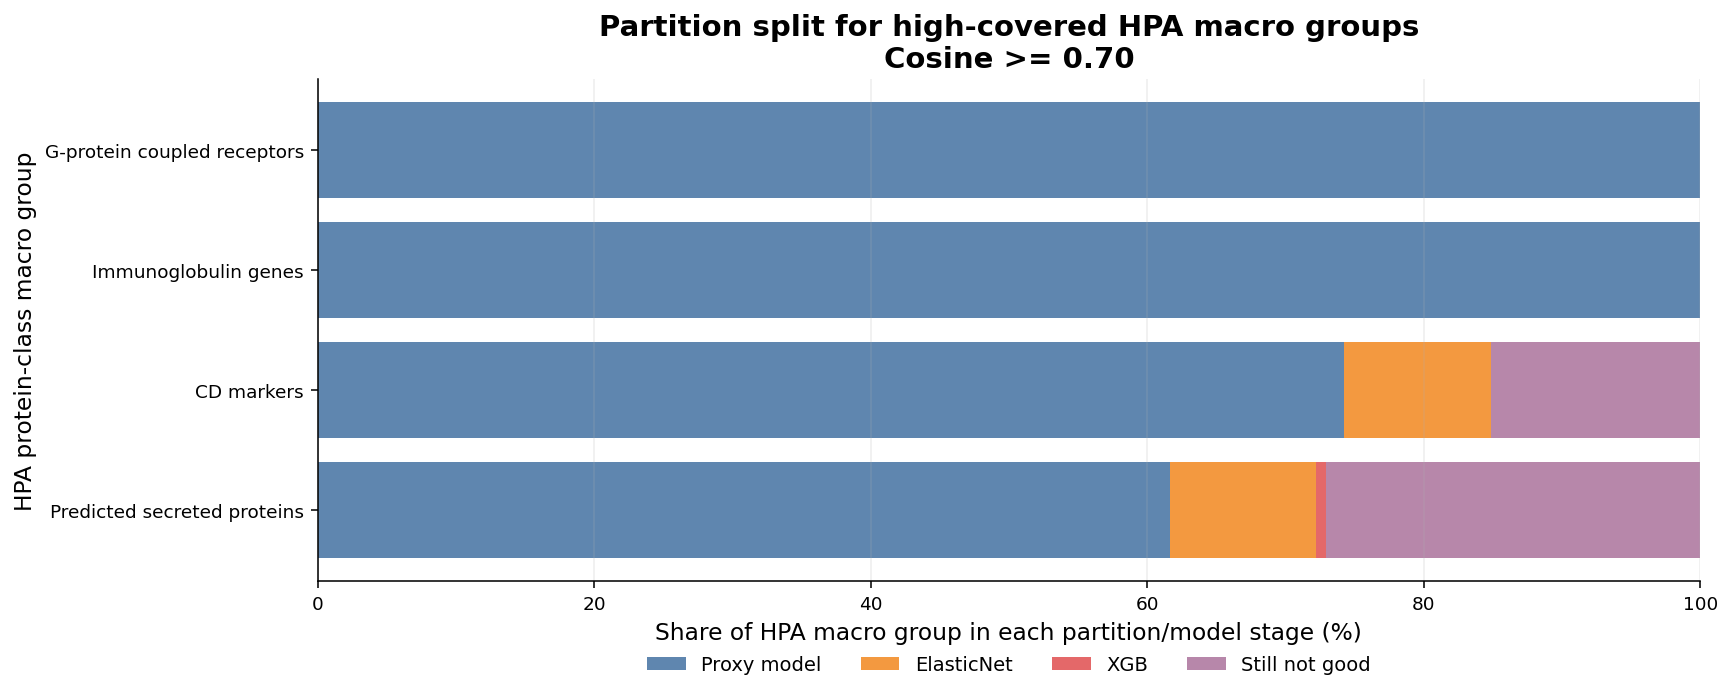

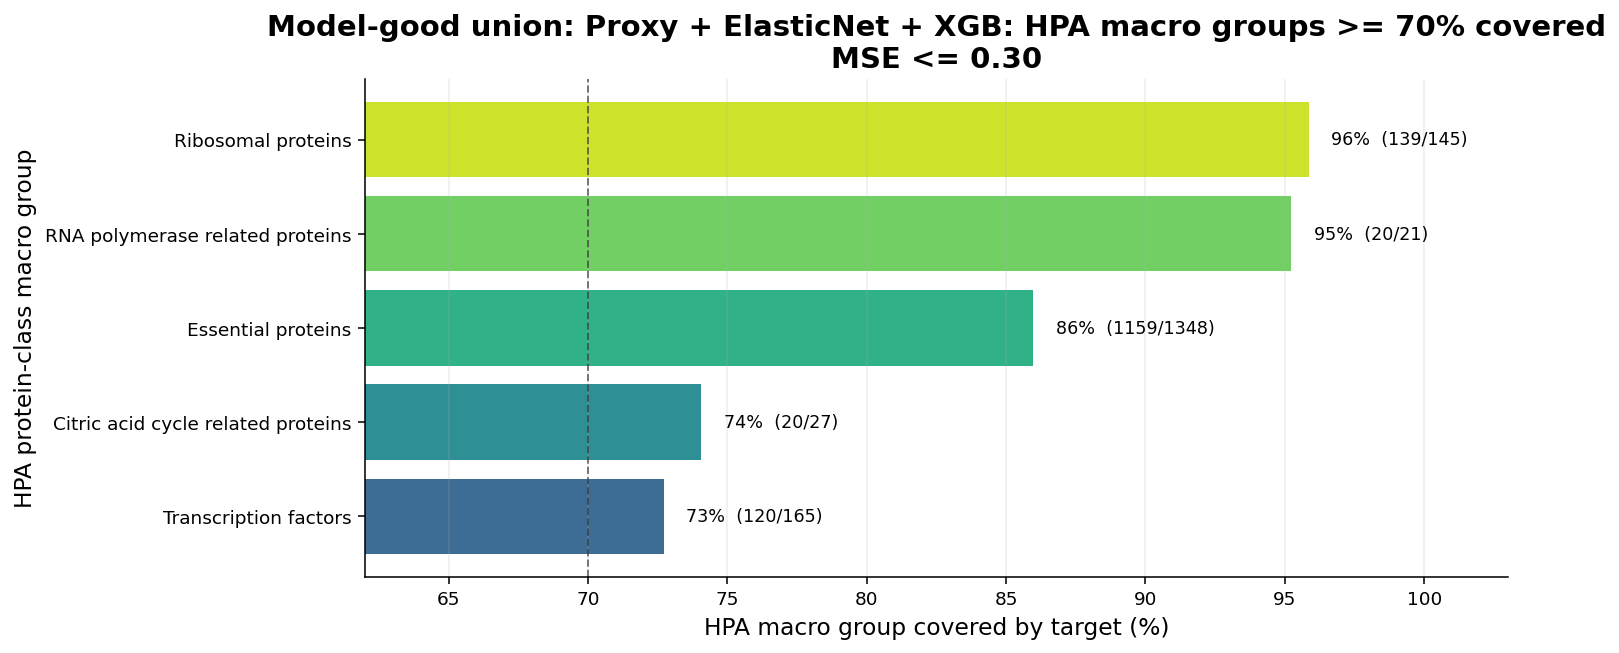

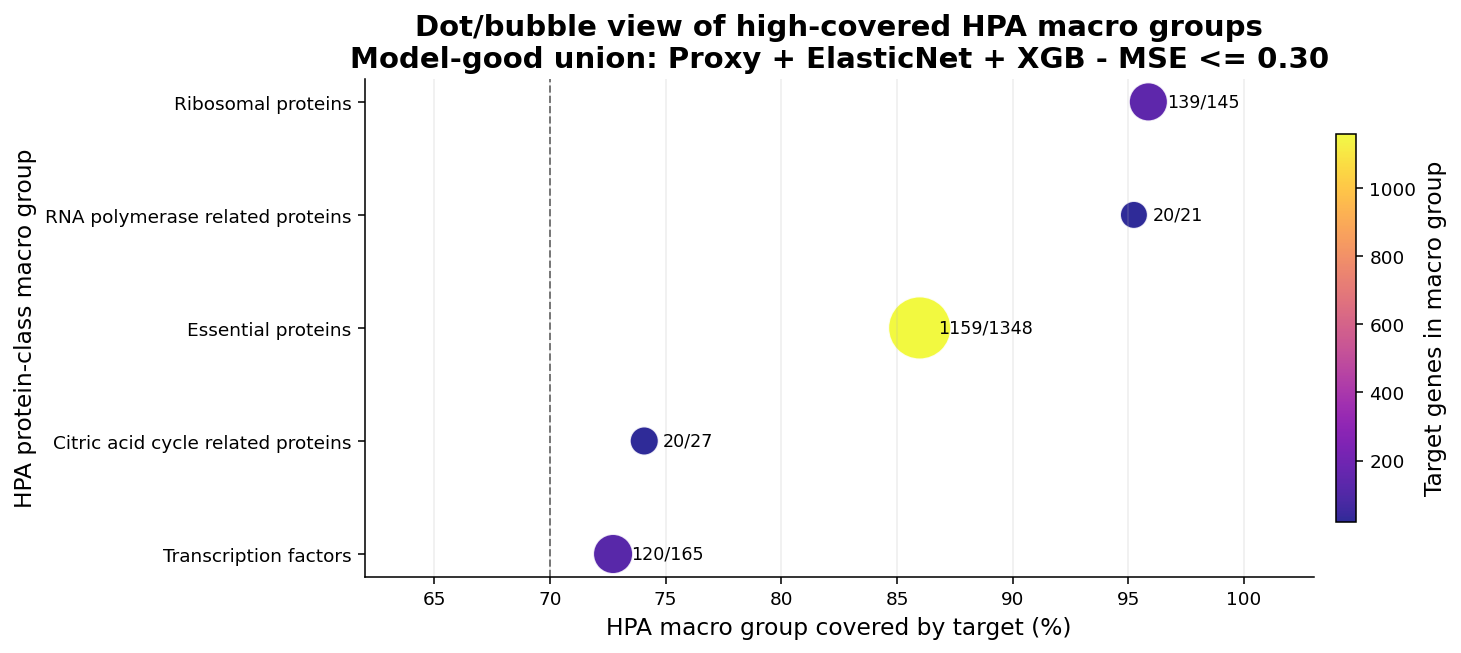

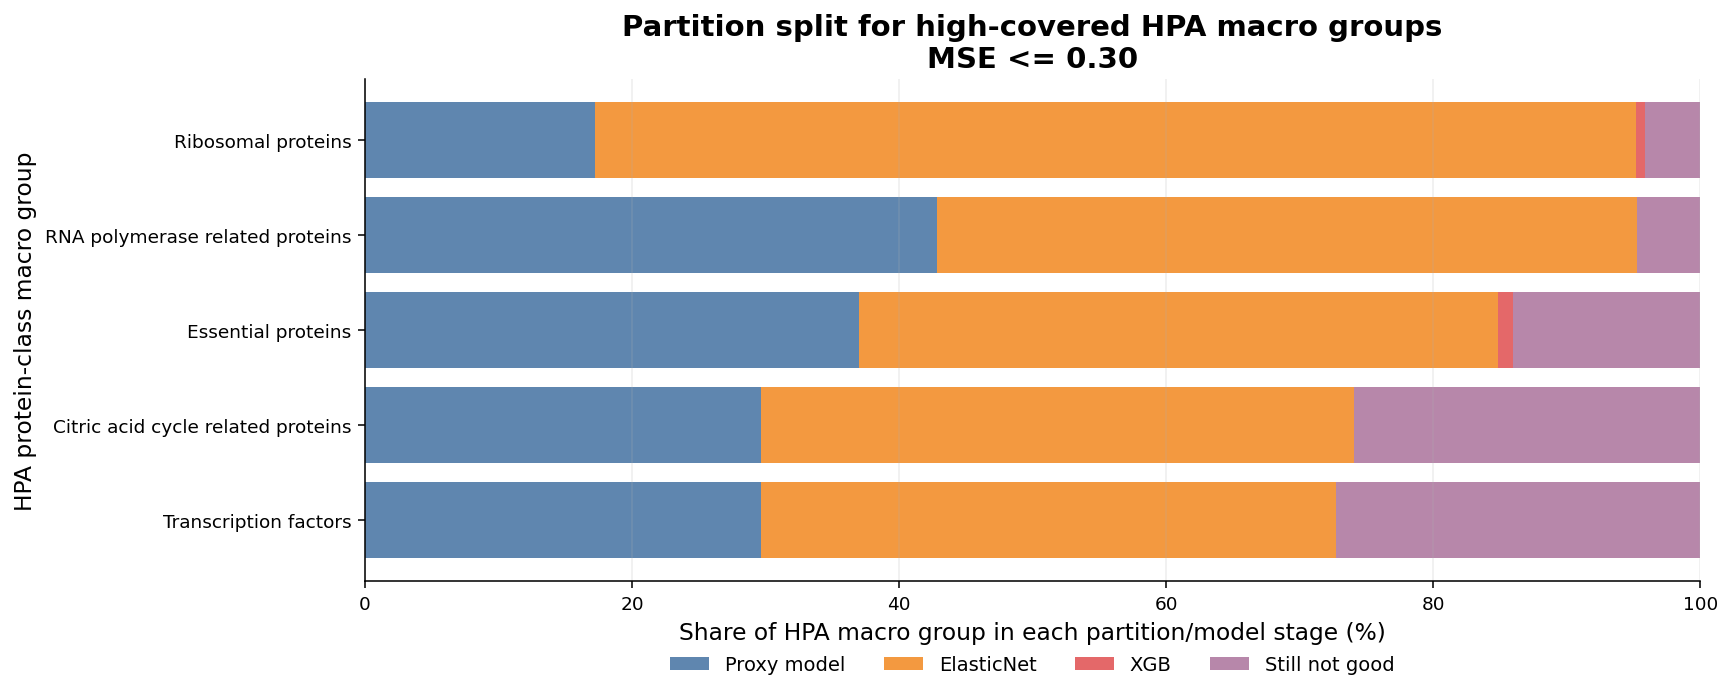


Figures saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_all_model_threshold_good_union_mse020_030_outputs\figures
High-coverage bar plots created: 5
High-coverage dot/bubble plots created: 5
High-coverage partition-split plots created: 5
Tables saved to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs\hpa_macroclass_all_model_threshold_good_union_mse020_030_outputs\tables

All target analyses completed.
Merged output root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.2_HPA_heatmaps_outputs
Completed targets: proxy, elasticnet, xgb, still_not_good, model_good_union


In [8]:
all_results = OrderedDict()

for spec in TARGET_SPECS:
    all_results[spec['key']] = run_target(
        spec,
        display_all=DISPLAY_ALL_PLOTS,
    )

print('\nAll target analyses completed.')
print('Merged output root:', OUTPUT_ROOT)
print('Completed targets:', ', '.join(all_results.keys()))

## Outputs

Shared tables are saved under `4.2_HPA_heatmaps_outputs/shared/tables`. Each target retains its original output-folder name under `4.2_HPA_heatmaps_outputs/`, with separate `tables` and `figures` subfolders.